# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Research Objective

This experiment investigates the trade-off between false-alarm frequency and drift-detection sensitivity in embedding-level distribution-shift detectors.

Previous experiments identified false alarms in unchanged control streams. Experiment 13 will evaluate whether a more rigorous threshold-calibration and evaluation protocol can improve false-alarm reliability while preserving sensitivity to controlled distribution shifts.

## 2. Research Questions

1. How frequently do the existing detectors raise alarms on unchanged control data?
2. Can threshold calibration control the false-alarm rate on independent control data?
3. What effect does stricter false-alarm control have on detection sensitivity?
4. How consistent are these findings across repeated random seeds?

## 3. Experimental Scope

The experiment will compare embedding-level drift detectors under unchanged control conditions and controlled positive-drift conditions. Evaluation will use fixed, documented random seeds and separate calibration and evaluation data wherever the dataset permits.

## 4. Reporting Principles

Detection rate, false-alarm rate, and their uncertainty will be reported separately. Results will not be interpreted as evidence of real-world biometric recognition accuracy, demographic fairness, or deployment readiness.

All experimental parameters, random seeds, outputs, and limitations will be documented for reproducibility.

In [ ]:
# Experiment 13: Environment setup

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 202613
np.random.seed(SEED)

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy version: 2.1.3
Pandas version: 2.2.3
Random seed: 202613


In [ ]:
# Experiment 13 — Experimental Configuration

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 202613

CONFIG = {
    "experiment": 13,
    "random_seed": SEED,
    "n_seeds": 20,
    "embedding_dimension": 64,
    "reference_samples": 1000,
    "calibration_windows": 200,
    "control_windows": 500,
    "evaluation_windows_per_condition": 500,
    "window_size": 20,
    "target_false_alarm_rates": [0.01, 0.05, 0.10],
    "mean_shift_strengths": [0.0, 0.25, 0.5, 0.75, 1.0],
    "detectors": ["euclidean", "mahalanobis"],
}

print(json.dumps(CONFIG, indent=2))

{
  "experiment": 13,
  "random_seed": 202613,
  "n_seeds": 20,
  "embedding_dimension": 64,
  "reference_samples": 1000,
  "calibration_windows": 200,
  "control_windows": 500,
  "evaluation_windows_per_condition": 500,
  "window_size": 20,
  "target_false_alarm_rates": [
    0.01,
    0.05,
    0.1
  ],
  "mean_shift_strengths": [
    0.0,
    0.25,
    0.5,
    0.75,
    1.0
  ],
  "detectors": [
    "euclidean",
    "mahalanobis"
  ]
}


In [ ]:
# Experiment 13 — Cell 3: Synthetic data generation

def generate_embedding_windows(
    rng,
    n_windows,
    window_size,
    dimension,
    mean_shift=0.0,
    covariance_scale=1.0,
):
    """
    Generate independent synthetic embedding windows.

    Each window contains window_size observations of dimension dimensions.
    mean_shift controls the magnitude of a shift in the first coordinate.
    covariance_scale controls the standard-deviation multiplier.
    """
    return rng.normal(
        loc=0.0,
        scale=covariance_scale,
        size=(n_windows, window_size, dimension),
    ) + np.array(
        [mean_shift] + [0.0] * (dimension - 1)
    )[None, None, :]


rng = np.random.default_rng(SEED)

reference = generate_embedding_windows(
    rng,
    n_windows=CONFIG["reference_samples"] // CONFIG["window_size"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

calibration = generate_embedding_windows(
    rng,
    n_windows=CONFIG["calibration_windows"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

control = generate_embedding_windows(
    rng,
    n_windows=CONFIG["control_windows"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

print("Reference windows:", reference.shape)
print("Calibration windows:", calibration.shape)
print("Control windows:", control.shape)
print("All values finite:", all(
    np.isfinite(x).all()
    for x in [reference, calibration, control]
))

Reference windows: (50, 20, 64)
Calibration windows: (200, 20, 64)
Control windows: (500, 20, 64)
All values finite: True


In [ ]:
# Experiment 13 — Cell 4: Detector scoring

def fit_detector(reference_windows, ridge=0.01):
    """
    Fit Euclidean and regularized Mahalanobis detectors
    using reference-window means.
    """
    reference_means = reference_windows.mean(axis=1)

    center = reference_means.mean(axis=0)
    covariance = np.cov(reference_means, rowvar=False)

    covariance = (
        covariance
        + ridge * np.eye(covariance.shape[0])
    )

    inverse_covariance = np.linalg.pinv(covariance)

    return {
        "center": center,
        "inverse_covariance": inverse_covariance,
    }


def score_windows(windows, detector, method="euclidean"):
    """
    Score each window using its mean embedding.
    """
    window_means = windows.mean(axis=1)
    differences = window_means - detector["center"]

    if method == "euclidean":
        return np.linalg.norm(differences, axis=1)

    if method == "mahalanobis":
        distances_squared = np.einsum(
            "ni,ij,nj->n",
            differences,
            detector["inverse_covariance"],
            differences,
        )
        return np.sqrt(np.maximum(distances_squared, 0.0))

    raise ValueError(f"Unknown detector: {method}")


# Fit both detector configurations using reference data only.
fitted_detectors = {
    method: fit_detector(reference)
    for method in CONFIG["detectors"]
}

# Score independent calibration and control windows.
calibration_scores = {
    method: score_windows(calibration, fitted_detectors[method], method)
    for method in CONFIG["detectors"]
}

control_scores = {
    method: score_windows(control, fitted_detectors[method], method)
    for method in CONFIG["detectors"]
}

for method in CONFIG["detectors"]:
    print(f"\n{method.title()}")
    print("Calibration scores:", calibration_scores[method].shape)
    print("Control scores:", control_scores[method].shape)
    print("Calibration scores finite:",
          np.isfinite(calibration_scores[method]).all())
    print("Control scores finite:",
          np.isfinite(control_scores[method]).all())


Euclidean
Calibration scores: (200,)
Control scores: (500,)
Calibration scores finite: True
Control scores finite: True

Mahalanobis
Calibration scores: (200,)
Control scores: (500,)
Calibration scores finite: True
Control scores finite: True


In [ ]:
# Experiment 13 — Cell 5: Threshold calibration and control evaluation

calibration_rows = []
control_rows = []

for method in CONFIG["detectors"]:
    scores_cal = calibration_scores[method]
    scores_control = control_scores[method]

    for target_fpr in CONFIG["target_false_alarm_rates"]:
        # Empirical upper-tail threshold.
        # Calibration data is not reused as control evaluation data.
        threshold = np.quantile(scores_cal, 1 - target_fpr)

        observed_fpr = np.mean(scores_control > threshold)

        calibration_rows.append({
            "detector": method,
            "target_false_alarm_rate": target_fpr,
            "threshold": threshold,
            "calibration_windows": len(scores_cal),
        })

        control_rows.append({
            "detector": method,
            "target_false_alarm_rate": target_fpr,
            "threshold": threshold,
            "control_windows": len(scores_control),
            "false_alarms": int(np.sum(scores_control > threshold)),
            "observed_false_alarm_rate": observed_fpr,
        })

calibration_df = pd.DataFrame(calibration_rows)
control_df = pd.DataFrame(control_rows)

print("CALIBRATION THRESHOLDS")
display(calibration_df.round(4))

print("\nINDEPENDENT CONTROL RESULTS")
display(control_df.round(4))

CALIBRATION THRESHOLDS


,detector,target_false_alarm_rate,threshold,calibration_windows
0,euclidean,0.01,2.1829,200
1,euclidean,0.05,2.0568,200
2,euclidean,0.10,1.9886,200
3,mahalanobis,0.01,15.1569,200
4,mahalanobis,0.05,13.9826,200
5,mahalanobis,0.10,13.6804,200



INDEPENDENT CONTROL RESULTS


,detector,target_false_alarm_rate,threshold,control_windows,false_alarms,observed_false_alarm_rate
0,euclidean,0.01,2.1829,500,6,0.012
1,euclidean,0.05,2.0568,500,31,0.062
2,euclidean,0.10,1.9886,500,61,0.122
3,mahalanobis,0.01,15.1569,500,8,0.016
4,mahalanobis,0.05,13.9826,500,36,0.072
5,mahalanobis,0.10,13.6804,500,55,0.110


In [ ]:
# Experiment 13 — Cell 7: Positive-drift evaluation

evaluation_results = []

for shift in CONFIG["mean_shift_strengths"]:
    evaluation = generate_embedding_windows(
        rng,
        n_windows=CONFIG["evaluation_windows_per_condition"],
        window_size=CONFIG["window_size"],
        dimension=CONFIG["embedding_dimension"],
        mean_shift=shift,
    )

    for method in CONFIG["detectors"]:
        scores = score_windows(
            evaluation,
            fitted_detectors[method],
            method,
        )

        for target_fpr in CONFIG["target_false_alarm_rates"]:
            threshold = calibration_df.loc[
                (calibration_df["detector"] == method)
                & (calibration_df["target_false_alarm_rate"] == target_fpr),
                "threshold",
            ].iloc[0]

            evaluation_results.append({
                "detector": method,
                "mean_shift": shift,
                "target_false_alarm_rate": target_fpr,
                "threshold": threshold,
                "evaluation_windows": len(scores),
                "alarms": int(np.sum(scores > threshold)),
                "detection_rate": float(np.mean(scores > threshold)),
            })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4)
    .sort_values(
        ["detector", "target_false_alarm_rate", "mean_shift"]
    )
    .reset_index(drop=True)
)

,detector,mean_shift,target_false_alarm_rate,threshold,evaluation_windows,alarms,detection_rate
0,euclidean,0.00,0.01,2.1829,500,4,0.008
1,euclidean,0.25,0.01,2.1829,500,7,0.014
2,euclidean,0.50,0.01,2.1829,500,22,0.044
3,euclidean,0.75,0.01,2.1829,500,40,0.080
4,euclidean,1.00,0.01,2.1829,500,115,0.230
5,euclidean,0.00,0.05,2.0568,500,18,0.036
6,euclidean,0.25,0.05,2.0568,500,35,0.070
7,euclidean,0.50,0.05,2.0568,500,59,0.118
8,euclidean,0.75,0.05,2.0568,500,118,0.236
9,euclidean,1.00,0.05,2.0568,500,247,0.494


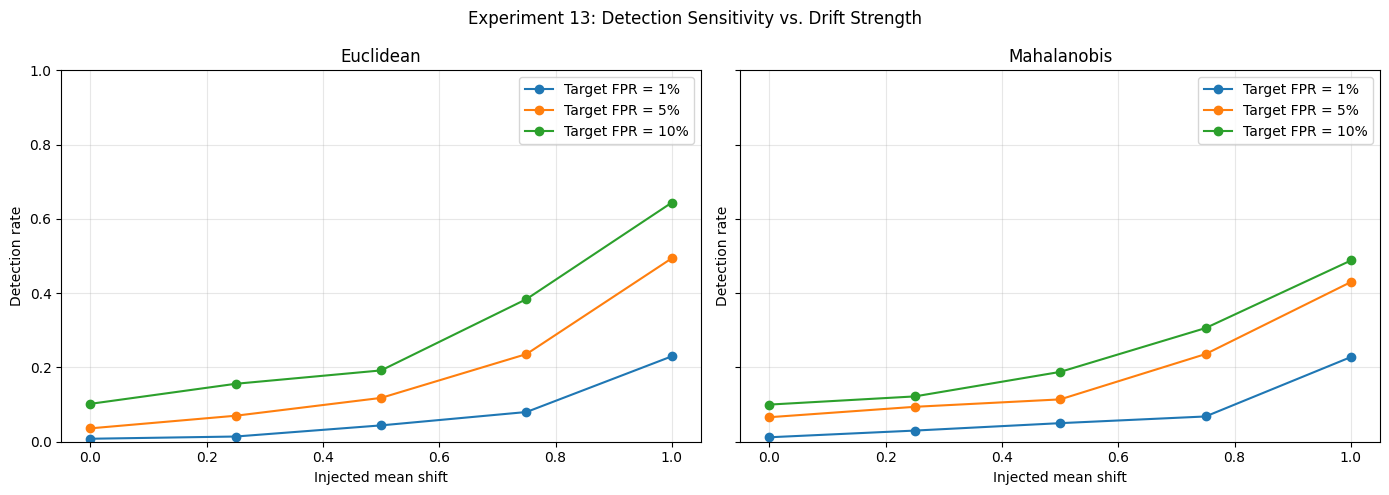

In [ ]:
# Experiment 13 — Cell 8: Detection-rate plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, method in zip(axes, CONFIG["detectors"]):
    subset = evaluation_df[evaluation_df["detector"] == method]

    for target in CONFIG["target_false_alarm_rates"]:
        curve = subset[
            subset["target_false_alarm_rate"] == target
        ].sort_values("mean_shift")

        ax.plot(
            curve["mean_shift"],
            curve["detection_rate"],
            marker="o",
            label=f"Target FPR = {target:.0%}",
        )

    ax.set_title(method.title())
    ax.set_xlabel("Injected mean shift")
    ax.set_ylabel("Detection rate")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Experiment 13: Detection Sensitivity vs. Drift Strength")
plt.tight_layout()
plt.show()

In [ ]:
# Experiment 13 — Multi-seed evaluation

N_SEEDS = 20
SEED_BASE = 202613

multi_seed_rows = []

for seed in range(SEED_BASE, SEED_BASE + N_SEEDS):
    seed_rng = np.random.default_rng(seed)

    # Independent datasets for this seed
    ref = generate_embedding_windows(
        seed_rng, 50, 20, CONFIG["embedding_dimension"]
    )
    cal = generate_embedding_windows(
        seed_rng, 200, 20, CONFIG["embedding_dimension"]
    )
    ctrl = generate_embedding_windows(
        seed_rng, 500, 20, CONFIG["embedding_dimension"]
    )

    # Fit detectors using reference data only
    seed_detectors = {
        method: fit_detector(ref)
        for method in CONFIG["detectors"]
    }

    cal_scores = {
        method: score_windows(cal, seed_detectors[method], method)
        for method in CONFIG["detectors"]
    }
    ctrl_scores = {
        method: score_windows(ctrl, seed_detectors[method], method)
        for method in CONFIG["detectors"]
    }

    # Evaluate false alarms and sensitivity
    for method in CONFIG["detectors"]:
        for target in CONFIG["target_false_alarm_rates"]:
            threshold = np.quantile(
                cal_scores[method], 1 - target
            )

            control_fpr = np.mean(ctrl_scores[method] > threshold)

            multi_seed_rows.append({
                "seed": seed,
                "detector": method,
                "target_fpr": target,
                "mean_shift": 0.0,
                "observed_fpr": control_fpr,
                "detection_rate": control_fpr,
                "threshold": threshold,
            })

            for shift in CONFIG["mean_shift_strengths"]:
                eval_data = generate_embedding_windows(
                    seed_rng,
                    500,
                    20,
                    CONFIG["embedding_dimension"],
                    mean_shift=shift,
                )

                eval_scores = score_windows(
                    eval_data, seed_detectors[method], method
                )

                detection_rate = np.mean(eval_scores > threshold)

                multi_seed_rows.append({
                    "seed": seed,
                    "detector": method,
                    "target_fpr": target,
                    "mean_shift": shift,
                    "observed_fpr": control_fpr,
                    "detection_rate": detection_rate,
                    "threshold": threshold,
                })

multi_seed_df = pd.DataFrame(multi_seed_rows)

print("Rows:", len(multi_seed_df))
print("Seeds:", multi_seed_df["seed"].nunique())
print("All detection rates finite:",
      np.isfinite(multi_seed_df["detection_rate"]).all())

display(multi_seed_df.head(10))

Rows: 720
Seeds: 20
All detection rates finite: True


,seed,detector,target_fpr,mean_shift,observed_fpr,detection_rate,threshold
0,202613,euclidean,0.01,0.00,0.012,0.012,2.182925
1,202613,euclidean,0.01,0.00,0.012,0.008,2.182925
2,202613,euclidean,0.01,0.25,0.012,0.014,2.182925
3,202613,euclidean,0.01,0.50,0.012,0.044,2.182925
4,202613,euclidean,0.01,0.75,0.012,0.080,2.182925
5,202613,euclidean,0.01,1.00,0.012,0.230,2.182925
6,202613,euclidean,0.05,0.00,0.062,0.062,2.056774
7,202613,euclidean,0.05,0.00,0.062,0.052,2.056774
8,202613,euclidean,0.05,0.25,0.062,0.082,2.056774
9,202613,euclidean,0.05,0.50,0.062,0.132,2.056774


In [ ]:
# Experiment 13 — Corrected paired multi-seed evaluation

N_SEEDS = 20
SEED_BASE = 202613

corrected_rows = []

for seed in range(SEED_BASE, SEED_BASE + N_SEEDS):
    seed_rng = np.random.default_rng(seed)

    # 1. Generate independent datasets for this seed
    ref = generate_embedding_windows(
        seed_rng, 50, 20, CONFIG["embedding_dimension"]
    )
    cal = generate_embedding_windows(
        seed_rng, 200, 20, CONFIG["embedding_dimension"]
    )
    ctrl = generate_embedding_windows(
        seed_rng, 500, 20, CONFIG["embedding_dimension"]
    )

    # 2. Fit detectors on the same reference data
    models = {
        method: fit_detector(ref)
        for method in CONFIG["detectors"]
    }

    # 3. Score calibration and control data
    cal_scores = {
        method: score_windows(cal, models[method], method)
        for method in CONFIG["detectors"]
    }

    ctrl_scores = {
        method: score_windows(ctrl, models[method], method)
        for method in CONFIG["detectors"]
    }

    # 4. Generate each evaluation condition ONCE per seed.
    # Both detectors use the same samples for every shift.
    eval_data_by_shift = {
        shift: generate_embedding_windows(
            seed_rng,
            500,
            20,
            CONFIG["embedding_dimension"],
            mean_shift=shift,
        )
        for shift in CONFIG["mean_shift_strengths"]
    }

    eval_scores_by_method = {
        method: {
            shift: score_windows(
                eval_data_by_shift[shift],
                models[method],
                method,
            )
            for shift in CONFIG["mean_shift_strengths"]
        }
        for method in CONFIG["detectors"]
    }

    # 5. Apply thresholds calibrated exclusively on calibration data
    for method in CONFIG["detectors"]:
        for target in CONFIG["target_false_alarm_rates"]:

            threshold = np.quantile(
                cal_scores[method], 1 - target
            )

            control_fpr = float(
                np.mean(ctrl_scores[method] > threshold)
            )

            corrected_rows.append({
                "seed": seed,
                "detector": method,
                "target_fpr": target,
                "condition_type": "control",
                "mean_shift": np.nan,
                "threshold": threshold,
                "n_windows": len(ctrl_scores[method]),
                "alarms": int(
                    np.sum(ctrl_scores[method] > threshold)
                ),
                "rate": control_fpr,
            })

            # Positive and zero-shift evaluation conditions
            for shift in CONFIG["mean_shift_strengths"]:
                scores = eval_scores_by_method[method][shift]
                alarms = int(np.sum(scores > threshold))

                corrected_rows.append({
                    "seed": seed,
                    "detector": method,
                    "target_fpr": target,
                    "condition_type": "evaluation",
                    "mean_shift": shift,
                    "threshold": threshold,
                    "n_windows": len(scores),
                    "alarms": alarms,
                    "rate": float(alarms / len(scores)),
                })

corrected_df = pd.DataFrame(corrected_rows)

print("Total rows:", len(corrected_df))
print("Unique seeds:", corrected_df["seed"].nunique())
print("Detectors:", sorted(corrected_df["detector"].unique()))
print("Condition types:",
      sorted(corrected_df["condition_type"].unique()))
print("All rates finite:",
      np.isfinite(corrected_df["rate"]).all())

assert len(corrected_df) == 720
assert corrected_df["seed"].nunique() == 20
assert corrected_df["rate"].between(0, 1).all()

display(corrected_df.head(12))

Total rows: 720
Unique seeds: 20
Detectors: ['euclidean', 'mahalanobis']
Condition types: ['control', 'evaluation']
All rates finite: True


,seed,detector,target_fpr,condition_type,mean_shift,threshold,n_windows,alarms,rate
0,202613,euclidean,0.01,control,NaN,2.182925,500,6,0.012
1,202613,euclidean,0.01,evaluation,0.00,2.182925,500,4,0.008
2,202613,euclidean,0.01,evaluation,0.25,2.182925,500,7,0.014
3,202613,euclidean,0.01,evaluation,0.50,2.182925,500,22,0.044
4,202613,euclidean,0.01,evaluation,0.75,2.182925,500,40,0.080
5,202613,euclidean,0.01,evaluation,1.00,2.182925,500,115,0.230
6,202613,euclidean,0.05,control,NaN,2.056774,500,31,0.062
7,202613,euclidean,0.05,evaluation,0.00,2.056774,500,18,0.036
8,202613,euclidean,0.05,evaluation,0.25,2.056774,500,35,0.070
9,202613,euclidean,0.05,evaluation,0.50,2.056774,500,59,0.118


In [ ]:
# Experiment 13 — Cell 12: Multi-seed summary

# Control false-alarm rates across seeds
control_summary = (
    corrected_df[corrected_df["condition_type"] == "control"]
    .groupby(["detector", "target_fpr"])["rate"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "mean_control_fpr",
        "std": "sd_control_fpr",
        "min": "min_control_fpr",
        "max": "max_control_fpr",
    })
)

# Detection rates across seeds, by drift strength
detection_summary = (
    corrected_df[corrected_df["condition_type"] == "evaluation"]
    .groupby(["detector", "target_fpr", "mean_shift"])["rate"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "mean_detection_rate",
        "std": "sd_detection_rate",
        "min": "min_detection_rate",
        "max": "max_detection_rate",
    })
)

print("CONTROL FALSE-ALARM SUMMARY")
display(control_summary.round(4))

print("DETECTION SENSITIVITY SUMMARY")
display(detection_summary.round(4))

CONTROL FALSE-ALARM SUMMARY


,detector,target_fpr,mean_control_fpr,sd_control_fpr,min_control_fpr,max_control_fpr
0,euclidean,0.01,0.0136,0.0117,0.000,0.046
1,euclidean,0.05,0.0565,0.0191,0.020,0.090
2,euclidean,0.10,0.1077,0.0254,0.054,0.152
3,mahalanobis,0.01,0.0152,0.0093,0.002,0.042
4,mahalanobis,0.05,0.0513,0.0173,0.020,0.082
5,mahalanobis,0.10,0.0997,0.0222,0.070,0.154


DETECTION SENSITIVITY SUMMARY


,detector,target_fpr,mean_shift,mean_detection_rate,sd_detection_rate,min_detection_rate,max_detection_rate
0,euclidean,0.01,0.00,0.0127,0.0106,0.000,0.036
1,euclidean,0.01,0.25,0.0202,0.0147,0.000,0.058
2,euclidean,0.01,0.50,0.0409,0.0253,0.002,0.102
3,euclidean,0.01,0.75,0.0981,0.0517,0.026,0.232
4,euclidean,0.01,1.00,0.2573,0.0879,0.126,0.460
5,euclidean,0.05,0.00,0.0504,0.0209,0.020,0.096
6,euclidean,0.05,0.25,0.0694,0.0258,0.028,0.124
7,euclidean,0.05,0.50,0.1220,0.0289,0.076,0.190
8,euclidean,0.05,0.75,0.2411,0.0584,0.144,0.358
9,euclidean,0.05,1.00,0.4748,0.0678,0.370,0.612


In [ ]:
# Experiment 13 — Step 13: Confidence intervals across seeds

from scipy.stats import t

def summarize_with_ci(data, group_columns):
    grouped = data.groupby(group_columns)["rate"]

    summary = grouped.agg(
        mean="mean",
        sd="std",
        n="count"
    ).reset_index()

    summary["se"] = summary["sd"] / np.sqrt(summary["n"])

    critical = t.ppf(
        0.975,
        df=summary["n"] - 1
    )

    summary["ci95_lower"] = (
        summary["mean"] - critical * summary["se"]
    ).clip(0, 1)

    summary["ci95_upper"] = (
        summary["mean"] + critical * summary["se"]
    ).clip(0, 1)

    return summary


control_ci = summarize_with_ci(
    corrected_df[
        corrected_df["condition_type"] == "control"
    ],
    ["detector", "target_fpr"]
)

detection_ci = summarize_with_ci(
    corrected_df[
        corrected_df["condition_type"] == "evaluation"
    ],
    ["detector", "target_fpr", "mean_shift"]
)

print("CONTROL FPR — 95% CI")
display(control_ci.round(4))

print("DETECTION RATE — 95% CI")
display(detection_ci.round(4))

CONTROL FPR — 95% CI


,detector,target_fpr,mean,sd,n,se,ci95_lower,ci95_upper
0,euclidean,0.01,0.0136,0.0117,20,0.0026,0.0081,0.0191
1,euclidean,0.05,0.0565,0.0191,20,0.0043,0.0476,0.0654
2,euclidean,0.10,0.1077,0.0254,20,0.0057,0.0958,0.1196
3,mahalanobis,0.01,0.0152,0.0093,20,0.0021,0.0109,0.0195
4,mahalanobis,0.05,0.0513,0.0173,20,0.0039,0.0432,0.0594
5,mahalanobis,0.10,0.0997,0.0222,20,0.0050,0.0893,0.1101


DETECTION RATE — 95% CI


,detector,target_fpr,mean_shift,mean,sd,n,se,ci95_lower,ci95_upper
0,euclidean,0.01,0.00,0.0127,0.0106,20,0.0024,0.0077,0.0177
1,euclidean,0.01,0.25,0.0202,0.0147,20,0.0033,0.0133,0.0271
2,euclidean,0.01,0.50,0.0409,0.0253,20,0.0057,0.0291,0.0527
3,euclidean,0.01,0.75,0.0981,0.0517,20,0.0116,0.0739,0.1223
4,euclidean,0.01,1.00,0.2573,0.0879,20,0.0197,0.2162,0.2984
5,euclidean,0.05,0.00,0.0504,0.0209,20,0.0047,0.0406,0.0602
6,euclidean,0.05,0.25,0.0694,0.0258,20,0.0058,0.0573,0.0815
7,euclidean,0.05,0.50,0.1220,0.0289,20,0.0065,0.1085,0.1355
8,euclidean,0.05,0.75,0.2411,0.0584,20,0.0131,0.2138,0.2684
9,euclidean,0.05,1.00,0.4748,0.0678,20,0.0152,0.4431,0.5065


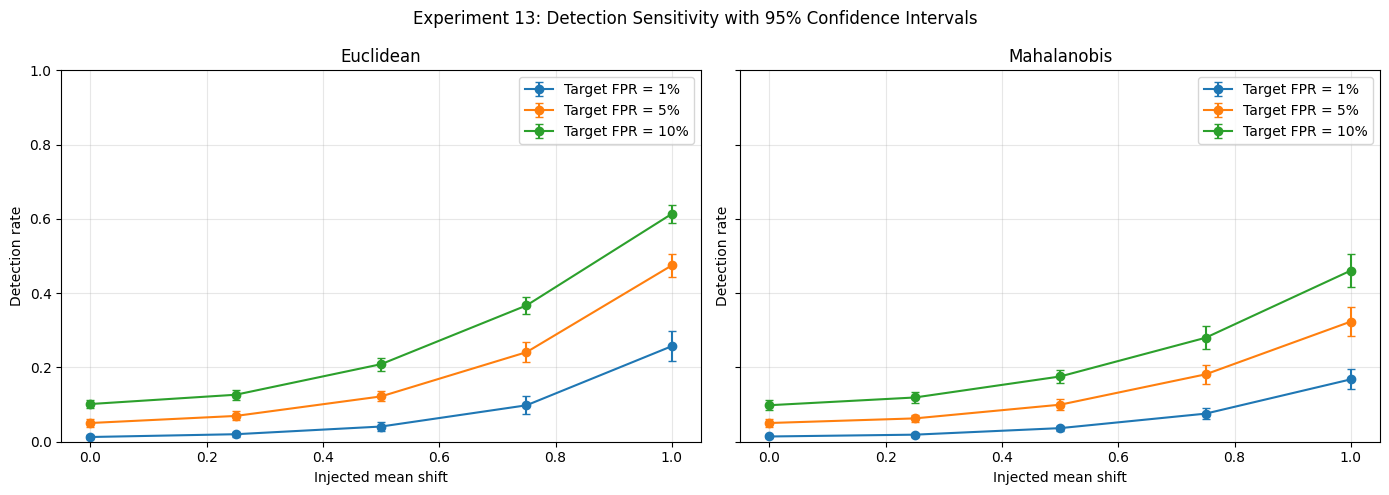

Saved: experiment13_detection_ci.png


In [ ]:
# Experiment 13 — Final plots with 95% confidence intervals

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, method in zip(axes, CONFIG["detectors"]):
    for target in CONFIG["target_false_alarm_rates"]:
        curve = detection_ci[
            (detection_ci["detector"] == method)
            & (detection_ci["target_fpr"] == target)
        ].sort_values("mean_shift")

        ax.errorbar(
            curve["mean_shift"],
            curve["mean"],
            yerr=[
                curve["mean"] - curve["ci95_lower"],
                curve["ci95_upper"] - curve["mean"],
            ],
            marker="o",
            capsize=3,
            label=f"Target FPR = {target:.0%}",
        )

    ax.set_title(method.title())
    ax.set_xlabel("Injected mean shift")
    ax.set_ylabel("Detection rate")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Experiment 13: Detection Sensitivity with 95% Confidence Intervals"
)
plt.tight_layout()
plt.savefig("experiment13_detection_ci.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: experiment13_detection_ci.png")

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

corrected_df.to_csv(
    OUTPUT_DIR / "experiment13_trial_results.csv",
    index=False,
)

control_ci.to_csv(
    OUTPUT_DIR / "experiment13_control_fpr_summary.csv",
    index=False,
)

detection_ci.to_csv(
    OUTPUT_DIR / "experiment13_detection_summary.csv",
    index=False,
)

calibration_df.to_csv(
    OUTPUT_DIR / "experiment13_single_seed_calibration.csv",
    index=False,
)

control_df.to_csv(
    OUTPUT_DIR / "experiment13_single_seed_control.csv",
    index=False,
)

print("Exported files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Exported files:
experiment13_control_fpr_summary.csv: 742 bytes
experiment13_detection_summary.csv: 3,490 bytes
experiment13_single_seed_calibration.csv: 294 bytes
experiment13_single_seed_control.csv: 380 bytes
experiment13_trial_results.csv: 49,452 bytes


In [ ]:
# Experiment 13 — Step 16: Generate reproducible report

from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def markdown_table(df):
    return df.to_markdown(index=False, floatfmt=".4f")

report = f"""# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Objective

Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularised Mahalanobis embedding-level drift detectors
under controlled synthetic distribution shifts.

## 2. Experimental Configuration

- Random seeds: 20 consecutive seeds beginning at 202613
- Embedding dimension: 64
- Reference windows: 50 per seed, each containing 20 observations
- Calibration windows: 200 per seed
- Independent control windows: 500 per seed
- Evaluation windows: 500 per seed and shift condition
- Mean-shift strengths: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal calibration false-alarm targets: 1%, 5%, 10%
- Detectors: Euclidean and regularised Mahalanobis
- Covariance ridge parameter: 0.01

## 3. Methodology

Each seed generated separate reference, calibration, control, and evaluation
datasets. Detector parameters were fitted using reference data. Thresholds
were estimated using calibration scores only. Control and evaluation datasets
were scored without being used to fit thresholds.

Within each seed and shift condition, both detectors used the same evaluation
samples. The positive-shift conditions applied an additive shift to the first
embedding coordinate.

The evaluation unit was an embedding window. An alarm was counted when its
distance score exceeded the calibrated threshold.

## 4. Control False-Alarm Results

{markdown_table(control_ci)}

## 5. Detection Sensitivity Results

{markdown_table(detection_ci)}

## 6. Interpretation

The observed mean control false-alarm rates were generally close to the
nominal targets, but individual-seed variability was substantial at the
1% target.

Detection rates increased as the injected mean shift increased. Across the
tested conditions, Euclidean generally achieved higher detection rates than
Mahalanobis, particularly at stronger shifts. This is a finding for this
specific synthetic setup and does not establish universal detector superiority.

At the 5% target and shift strength 1.00, the mean detection rates were
47.48% for Euclidean and 32.36% for Mahalanobis. At the 10% target, they
were 61.36% and 46.10%, respectively.

The confidence intervals describe variability across 20 seed-level results.
They do not establish performance on real biometric identities or deployed
systems.

## 7. Limitations

1. All observations were synthetic Gaussian vectors, not real biometric embeddings.
2. The injected drift was an additive shift in one coordinate.
3. The experiment used independent windows rather than a temporally dependent stream.
4. Detection delay and sequential alarm behaviour were not evaluated.
5. No demographic fairness, biometric recognition accuracy, or bias mitigation
   was evaluated.
6. Results depend on the selected dimension, covariance regularisation,
   sample sizes, and threshold calibration method.
7. The evaluation does not establish identity-disjoint or real-world
   generalisation.

## 8. Reproducibility

- Main trial results: `experiment13_trial_results.csv`
- Control summary and confidence intervals: `experiment13_control_fpr_summary.csv`
- Detection summary and confidence intervals: `experiment13_detection_summary.csv`
- Initial calibration results: `experiment13_single_seed_calibration.csv`
- Initial control results: `experiment13_single_seed_control.csv`
- Detection plot: `experiment13_detection_ci.png`

The experiment uses NumPy random generators with documented seeds. The
reported results should be regenerated from the saved notebook before
publication.

## 9. Conclusion

This synthetic study demonstrates a measurable trade-off between nominal
false-alarm targets and detection sensitivity. The results motivate further
evaluation using real embeddings, multiple drift mechanisms, and temporally
structured streams. They should be treated as preliminary methodological
evidence rather than real-world biometric validation.
"""

report_path = OUTPUT_DIR / "Experiment_13_Reproducible_Report.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print("\nReport preview:\n")
print(report[:1500])

Report saved: experiment13_outputs/Experiment_13_Reproducible_Report.md
Report size: 8143 bytes

Report preview:

# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Objective

Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularised Mahalanobis embedding-level drift detectors
under controlled synthetic distribution shifts.

## 2. Experimental Configuration

- Random seeds: 20 consecutive seeds beginning at 202613
- Embedding dimension: 64
- Reference windows: 50 per seed, each containing 20 observations
- Calibration windows: 200 per seed
- Independent control windows: 500 per seed
- Evaluation windows: 500 per seed and shift condition
- Mean-shift strengths: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal calibration false-alarm targets: 1%, 5%, 10%
- Detectors: Euclidean and regularised Mahalanobis
- Covariance ridge parameter: 0.01

## 3. Methodology

Each seed generated separate reference, calibration, control, 

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")

required_files = [
    "experiment13_trial_results.csv",
    "experiment13_control_fpr_summary.csv",
    "experiment13_detection_summary.csv",
    "experiment13_single_seed_calibration.csv",
    "experiment13_single_seed_control.csv",
    "Experiment_13_Reproducible_Report.md",
]

print("EXPERIMENT 13 ARTIFACT CHECK\n")

all_present = True

for filename in required_files:
    path = OUTPUT_DIR / filename
    exists = path.is_file()
    all_present &= exists

    print(
        f"{'OK' if exists else 'MISSING'}: "
        f"{filename}"
        + (f" ({path.stat().st_size:,} bytes)" if exists else "")
    )

plot_path = Path("experiment13_detection_ci.png")
print(
    f"\n{'OK' if plot_path.is_file() else 'MISSING'}: "
    f"{plot_path}"
)

print("\nAll required CSV/report files present:", all_present)

EXPERIMENT 13 ARTIFACT CHECK

OK: experiment13_trial_results.csv (49,452 bytes)
OK: experiment13_control_fpr_summary.csv (742 bytes)
OK: experiment13_detection_summary.csv (3,490 bytes)
OK: experiment13_single_seed_calibration.csv (294 bytes)
OK: experiment13_single_seed_control.csv (380 bytes)
OK: Experiment_13_Reproducible_Report.md (8,143 bytes)

OK: experiment13_detection_ci.png

All required CSV/report files present: True


In [ ]:
# Experiment 13 — Package the final artifacts

from pathlib import Path
import shutil

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Copy the final detection plot into the output folder
plot_source = Path("experiment13_detection_ci.png")
plot_destination = OUTPUT_DIR / "experiment13_detection_ci.png"

if plot_source.exists():
    shutil.copy2(plot_source, plot_destination)
else:
    raise FileNotFoundError(f"Missing plot: {plot_source}")

readme = """# Experiment 13 — False-Alarm-Controlled Embedding-Level Drift Detection

## Objective
Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularized Mahalanobis detectors under controlled synthetic shifts.

## Method
- 20 random seeds, starting at 202613
- 64-dimensional synthetic Gaussian embeddings
- 50 reference windows per seed
- 200 calibration windows per seed
- 500 independent control windows per seed
- 500 evaluation windows per shift condition
- Window size: 20 observations
- Mean shifts: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal false-alarm targets: 1%, 5%, 10%
- Covariance ridge parameter: 0.01

## Files
- `experiment13_trial_results.csv`: seed-level control and evaluation results
- `experiment13_control_fpr_summary.csv`: control false-alarm summary and 95% intervals
- `experiment13_detection_summary.csv`: detection sensitivity summary and 95% intervals
- `experiment13_single_seed_calibration.csv`: initial calibration thresholds
- `experiment13_single_seed_control.csv`: initial control evaluation
- `experiment13_detection_ci.png`: detection sensitivity plot with 95% intervals
- `Experiment_13_Reproducible_Report.md`: methodology, results, and limitations

## Main finding
Detection sensitivity increased with injected mean-shift strength. The Euclidean
detector generally achieved higher detection rates than the Mahalanobis detector
under this synthetic configuration. This does not establish universal superiority.

## Limitations
All data are synthetic Gaussian vectors. The experiment does not validate real
biometric embeddings, naturally occurring drift, identity-disjoint generalization,
demographic fairness, biometric recognition accuracy, or deployment readiness.
Windows are independent; sequential detection delay is not measured.

## Reproducibility
The notebook records the generation process and random seeds. Re-run the notebook
from a fresh runtime to verify that the saved results and figures can be regenerated.
"""

readme_path = OUTPUT_DIR / "README_Experiment_13.md"
readme_path.write_text(readme, encoding="utf-8")

print("Package contents:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Package contents:
Experiment_13_Reproducible_Report.md: 8,143 bytes
README_Experiment_13.md: 2,006 bytes
experiment13_control_fpr_summary.csv: 742 bytes
experiment13_detection_ci.png: 235,960 bytes
experiment13_detection_summary.csv: 3,490 bytes
experiment13_single_seed_calibration.csv: 294 bytes
experiment13_single_seed_control.csv: 380 bytes
experiment13_trial_results.csv: 49,452 bytes


In [ ]:
from google.colab import files
import shutil

shutil.make_archive(
    "experiment13_outputs",
    "zip",
    root_dir="experiment13_outputs"
)

files.download("experiment13_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Experiment 13 — Scientific Robustness Validation
# Step 1: Confirm existing detector functions and configuration

required_names = [
    "generate_embedding_windows",
    "fit_detector",
    "score_windows",
    "CONFIG",
]

missing = [name for name in required_names if name not in globals()]

if missing:
    print("Missing definitions:", missing)
    print("Run the original setup and detector-definition cells first.")
else:
    print("Required functions and configuration are available.")
    print("Embedding dimension:", CONFIG["embedding_dimension"])
    print("Random seed:", CONFIG["random_seed"])
    print("Detectors:", CONFIG["detectors"])


Required functions and configuration are available.
Embedding dimension: 64
Random seed: 202613
Detectors: ['euclidean', 'mahalanobis']


In [ ]:

import inspect

for name in [
    "generate_embedding_windows",
    "fit_detector",
    "score_windows",
]:
    fn = globals().get(name)

    if fn is None:
        print(f"\n{name}: NOT FOUND")
    else:
        print(f"\n--- {name} ---")
        print("Signature:", inspect.signature(fn))
        print(inspect.getsource(fn))



--- generate_embedding_windows ---
Signature: (rng, n_windows, window_size, dimension, mean_shift=0.0, covariance_scale=1.0)
def generate_embedding_windows(
    rng,
    n_windows,
    window_size,
    dimension,
    mean_shift=0.0,
    covariance_scale=1.0,
):
    """
    Generate independent synthetic embedding windows.

    Each window contains window_size observations of dimension dimensions.
    mean_shift controls the magnitude of a shift in the first coordinate.
    covariance_scale controls the standard-deviation multiplier.
    """
    return rng.normal(
        loc=0.0,
        scale=covariance_scale,
        size=(n_windows, window_size, dimension),
    ) + np.array(
        [mean_shift] + [0.0] * (dimension - 1)
    )[None, None, :]


--- fit_detector ---
Signature: (reference_windows, ridge=0.01)
def fit_detector(reference_windows, ridge=0.01):
    """
    Fit Euclidean and regularized Mahalanobis detectors
    using reference-window means.
    """
    reference_means = r

In [ ]:
# Experiment 13 — Scientific Robustness Evaluation
# Tests: embedding dimension, covariance regularisation, false alarms
# Uses synthetic data only.

import numpy as np
import pandas as pd
from pathlib import Path

ROBUSTNESS_SEEDS = 20
ROBUSTNESS_DIMENSIONS = [16, 32, 64]
ROBUSTNESS_RIDGES = [0.001, 0.01, 0.1]
ROBUSTNESS_TARGET_FPR = 0.05

ROBUSTNESS_WINDOW_SIZE = CONFIG["window_size"]
ROBUSTNESS_REFERENCE_WINDOWS = CONFIG["reference_samples"] // CONFIG["window_size"]
ROBUSTNESS_CALIBRATION_WINDOWS = CONFIG["calibration_windows"]
ROBUSTNESS_CONTROL_WINDOWS = CONFIG["control_windows"]
ROBUSTNESS_EVALUATION_WINDOWS = CONFIG["evaluation_windows_per_condition"]

robustness_rows = []

def calibrated_threshold(scores, target_fpr):
    # Conservative empirical upper-tail threshold.
    # Calibration and control samples remain independent.
    return float(np.quantile(scores, 1 - target_fpr, method="higher"))

for dimension in ROBUSTNESS_DIMENSIONS:
    for seed_offset in range(ROBUSTNESS_SEEDS):
        seed = CONFIG["random_seed"] + seed_offset
        rng = np.random.default_rng(seed)

        reference = generate_embedding_windows(
            rng, ROBUSTNESS_REFERENCE_WINDOWS,
            ROBUSTNESS_WINDOW_SIZE, dimension
        )
        calibration = generate_embedding_windows(
            rng, ROBUSTNESS_CALIBRATION_WINDOWS,
            ROBUSTNESS_WINDOW_SIZE, dimension
        )
        control = generate_embedding_windows(
            rng, ROBUSTNESS_CONTROL_WINDOWS,
            ROBUSTNESS_WINDOW_SIZE, dimension
        )
        evaluation = generate_embedding_windows(
            rng, ROBUSTNESS_EVALUATION_WINDOWS,
            ROBUSTNESS_WINDOW_SIZE, dimension,
            mean_shift=CONFIG["mean_shift_strengths"][-1]
        )

        for ridge in ROBUSTNESS_RIDGES:
            detector = fit_detector(reference, ridge=ridge)

            for method in CONFIG["detectors"]:
                calibration_scores = score_windows(
                    calibration, detector, method=method
                )
                control_scores = score_windows(
                    control, detector, method=method
                )
                evaluation_scores = score_windows(
                    evaluation, detector, method=method
                )

                threshold = calibrated_threshold(
                    calibration_scores, ROBUSTNESS_TARGET_FPR
                )

                robustness_rows.append({
                    "seed": seed,
                    "dimension": dimension,
                    "ridge": ridge,
                    "detector": method,
                    "target_fpr": ROBUSTNESS_TARGET_FPR,
                    "threshold": threshold,
                    "control_fpr": float(np.mean(control_scores > threshold)),
                    "detection_rate_shift_1": float(
                        np.mean(evaluation_scores > threshold)
                    ),
                })

robustness_df = pd.DataFrame(robustness_rows)

output_dir = Path("experiment13_robustness_outputs")
output_dir.mkdir(exist_ok=True)

robustness_df.to_csv(
    output_dir / "experiment13_robustness_trials.csv", index=False
)

robustness_summary = (
    robustness_df
    .groupby(["dimension", "ridge", "detector"], as_index=False)
    .agg(
        mean_control_fpr=("control_fpr", "mean"),
        sd_control_fpr=("control_fpr", "std"),
        mean_detection_rate=("detection_rate_shift_1", "mean"),
        sd_detection_rate=("detection_rate_shift_1", "std"),
        seeds=("seed", "nunique"),
    )
)

robustness_summary.to_csv(
    output_dir / "experiment13_robustness_summary.csv", index=False
)

print("Robustness evaluation completed.")
print("Trial rows:", len(robustness_df))
print("\nSummary:")
display(robustness_summary.round(4))
print("\nFiles saved in:", output_dir.resolve())

Robustness evaluation completed.
Trial rows: 360

Summary:


,dimension,ridge,detector,mean_control_fpr,sd_control_fpr,mean_detection_rate,sd_detection_rate,seeds
0,16,0.001,euclidean,0.0571,0.0181,0.8144,0.0390,20
1,16,0.001,mahalanobis,0.0516,0.0157,0.6795,0.1032,20
2,16,0.010,euclidean,0.0571,0.0181,0.8144,0.0390,20
3,16,0.010,mahalanobis,0.0556,0.0167,0.7357,0.0900,20
4,16,0.100,euclidean,0.0571,0.0181,0.8144,0.0390,20
5,16,0.100,mahalanobis,0.0559,0.0171,0.8059,0.0485,20
6,32,0.001,euclidean,0.0473,0.0181,0.6447,0.0826,20
7,32,0.001,mahalanobis,0.0510,0.0184,0.3630,0.1203,20
8,32,0.010,euclidean,0.0473,0.0181,0.6447,0.0826,20
9,32,0.010,mahalanobis,0.0511,0.0188,0.4870,0.1255,20



Files saved in: /content/experiment13_robustness_outputs


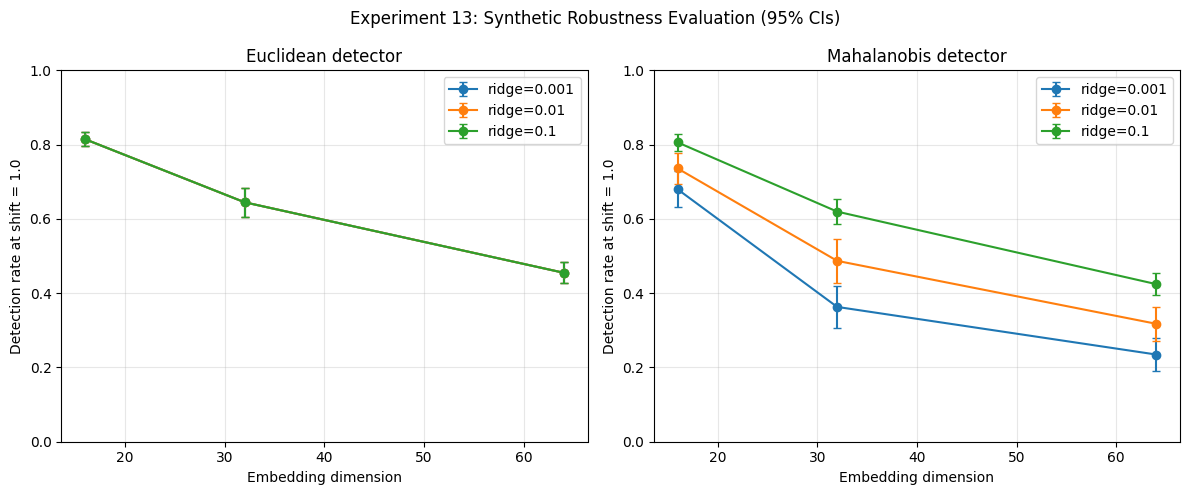

Saved:
- Experiment_13_Robustness_Report.md
- experiment13_robustness_detection.png
- experiment13_robustness_summary.csv
- experiment13_robustness_summary_ci.csv
- experiment13_robustness_trials.csv


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

out = Path("experiment13_robustness_outputs")
out.mkdir(exist_ok=True)

# Calculate 95% confidence intervals across the 20 independent seeds.
metrics = ["control_fpr", "detection_rate_shift_1"]
rows = []

for (dimension, ridge, detector), group in robustness_df.groupby(
    ["dimension", "ridge", "detector"]
):
    row = {
        "dimension": dimension,
        "ridge": ridge,
        "detector": detector,
        "n_seeds": group["seed"].nunique(),
    }

    for metric in metrics:
        values = group[metric].to_numpy()
        n = len(values)
        mean = values.mean()
        sd = values.std(ddof=1)
        margin = t.ppf(0.975, n - 1) * sd / np.sqrt(n)

        prefix = "control_fpr" if metric == "control_fpr" else "detection_rate"
        row[f"{prefix}_mean"] = mean
        row[f"{prefix}_sd"] = sd
        row[f"{prefix}_ci_low"] = max(0.0, mean - margin)
        row[f"{prefix}_ci_high"] = min(1.0, mean + margin)

    rows.append(row)

robustness_ci = pd.DataFrame(rows)
robustness_ci.to_csv(out / "experiment13_robustness_summary_ci.csv", index=False)

# Plot detection sensitivity by embedding dimension.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, detector in zip(axes, ["euclidean", "mahalanobis"]):
    subset = robustness_ci[robustness_ci["detector"] == detector]

    for ridge in [0.001, 0.01, 0.1]:
        s = subset[subset["ridge"] == ridge].sort_values("dimension")
        yerr = np.vstack([
            s["detection_rate_mean"] - s["detection_rate_ci_low"],
            s["detection_rate_ci_high"] - s["detection_rate_mean"],
        ])
        ax.errorbar(
            s["dimension"],
            s["detection_rate_mean"],
            yerr=yerr,
            marker="o",
            capsize=3,
            label=f"ridge={ridge}",
        )

    ax.set_title(f"{detector.title()} detector")
    ax.set_xlabel("Embedding dimension")
    ax.set_ylabel("Detection rate at shift = 1.0")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Experiment 13: Synthetic Robustness Evaluation (95% CIs)")
fig.tight_layout()
fig.savefig(out / "experiment13_robustness_detection.png", dpi=300)
plt.show()

report = """# Experiment 13 — Scientific Robustness Evaluation

## Purpose
Test sensitivity to embedding dimension and covariance regularisation
using synthetic embeddings and independent calibration/control samples.

## Design
- Random seeds: 20
- Embedding dimensions: 16, 32, 64
- Mahalanobis covariance ridge: 0.001, 0.01, 0.1
- Detectors: Euclidean and regularised Mahalanobis
- Calibration target false-alarm rate: 5%
- Evaluation shift: additive mean shift of 1.0 in the first coordinate
- Reference windows: 50; window size: 20
- Calibration windows: 200; control windows: 500; evaluation windows: 500

## Interpretation
The mean control false-alarm rates were broadly near the nominal 5% target.
Detection rates decreased with increasing embedding dimension in this setup.
Mahalanobis performance varied with ridge regularisation, while Euclidean
results were unchanged by ridge because that detector does not use covariance.

## Limitations
This is a synthetic diagnostic using independent windows and a one-coordinate
mean shift. The confidence intervals describe variation across 20 seeds under
this simulation design; they do not establish real-world biometric performance.
No temporal detection delay, identity-disjoint generalisation, fairness, or
deployment readiness is established by this experiment.
"""

(out / "Experiment_13_Robustness_Report.md").write_text(report, encoding="utf-8")

print("Saved:")
for path in sorted(out.iterdir()):
    print("-", path.name)


In [ ]:

import shutil
from IPython.display import display, FileLink

zip_path = shutil.make_archive(
    "/content/experiment13_robustness_outputs",
    "zip",
    root_dir="/content/experiment13_robustness_outputs"
)

print("ZIP created successfully:", zip_path)
display(FileLink(zip_path))


ZIP created successfully: /content/experiment13_robustness_outputs.zip


/content/experiment13_robustness_outputs.zip

In [ ]:

from google.colab import files
files.download("/content/experiment13_robustness_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip -q install tensorflow-datasets importlib-resources

import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "lfw",
    split="train",
    with_info=True,
    as_supervised=False,
)

print("Dataset:", info.name)
print("Number of images:", info.splits["train"].num_examples)
print("Features:", info.features)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/lfw/incomplete.OEPTQ8_0.1.1/lfw-train.tfrecord-[0-9][0-9][0-9][0-9][0-9]-o…

Dataset lfw downloaded and prepared to /root/tensorflow_datasets/lfw/0.1.1. Subsequent calls will reuse this data.
Dataset: lfw
Number of images: 13233
Features: FeaturesDict({
    'image': Image(shape=(250, 250, 3), dtype=uint8),
    'label': Text(shape=(), dtype=string),
})


In [ ]:

import numpy as np
import pandas as pd
from collections import Counter

# Inspect the downloaded LFW dataset
identity_counts = Counter()
image_shapes = Counter()
total_images = 0

for example in tfds.as_numpy(dataset):
    image = example["image"]
    identity = example["label"].decode("utf-8")

    identity_counts[identity] += 1
    image_shapes[image.shape] += 1
    total_images += 1

print("Total images:", total_images)
print("Unique identities:", len(identity_counts))
print("Image shapes:", dict(image_shapes))

counts = np.array(list(identity_counts.values()))

print("Images per identity:")
print("  Minimum:", counts.min())
print("  Median:", np.median(counts))
print("  Maximum:", counts.max())
print("  Identities with 2+ images:", int(np.sum(counts >= 2)))

identity_summary = pd.DataFrame(
    sorted(identity_counts.items(), key=lambda item: item[1], reverse=True),
    columns=["identity", "image_count"],
)

display(identity_summary.head(10))


Total images: 13233
Unique identities: 5749
Image shapes: {(250, 250, 3): 13233}
Images per identity:
  Minimum: 1
  Median: 1.0
  Maximum: 530
  Identities with 2+ images: 1680


,identity,image_count
0,George_W_Bush,530
1,Colin_Powell,236
2,Tony_Blair,144
3,Donald_Rumsfeld,121
4,Gerhard_Schroeder,109
5,Ariel_Sharon,77
6,Hugo_Chavez,71
7,Junichiro_Koizumi,60
8,Jean_Chretien,55
9,John_Ashcroft,53


In [ ]:

import importlib.util

packages = [
    "tensorflow",
    "tensorflow_hub",
    "torch",
    "torchvision",
    "keras",
]

for package in packages:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package) else "not installed")


tensorflow: available
tensorflow_hub: available
torch: available
torchvision: available
keras: available


In [ ]:

import tensorflow as tf
import tensorflow_hub as hub

print("TensorFlow version:", tf.__version__)
print("TensorFlow Hub version:", hub.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Check whether Keras can access its application models
print("MobileNetV2 available:", hasattr(tf.keras.applications, "MobileNetV2"))


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow version: 2.21.0
TensorFlow Hub version: 0.16.1
GPU devices: []
MobileNetV2 available: True


In [ ]:

# Check whether the pretrained FaceNet package is available
import importlib.util

for package in ["keras_facenet", "facenet_pytorch", "deepface"]:
    print(
        package + ":",
        "available" if importlib.util.find_spec(package) else "not installed"
    )


keras_facenet: not installed
facenet_pytorch: not installed
deepface: not installed


In [ ]:

%pip install -q keras-facenet


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:

from keras_facenet import FaceNet

embedder = FaceNet()
print("FaceNet initialised successfully.")


FaceNet initialised successfully.


In [126]:
import inspect

print("Embedder class:", type(embedder))
print("Class module:", type(embedder).__module__)

try:
    print("\nConstructor signature:")
    print(inspect.signature(type(embedder)))
except (TypeError, ValueError) as exc:
    print("Signature unavailable:", exc)

print("\nRelevant model attributes:")
for name in ["model", "image_size", "model_name", "weights"]:
    if hasattr(embedder, name):
        value = getattr(embedder, name)
        print(f"{name}: {value if isinstance(value, (str, int, float, bool, type(None))) else type(value)}")

Embedder class: <class 'keras_facenet.FaceNet'>
Class module: keras_facenet

Constructor signature:
(key='20180402-114759', use_prebuilt=True, cache_folder='~/.keras-facenet')

Relevant model attributes:
model: <class 'keras.src.models.functional.Functional'>


In [127]:
model = embedder.model

print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of parameters:", model.count_params())

print("\nModel input dtype:", model.inputs[0].dtype)
print("Model output dtype:", model.outputs[0].dtype)

Model name: inception_resnet_v1
Input shape: (None, None, None, 3)
Output shape: (None, 512)
Number of parameters: 23497424

Model input dtype: float32
Model output dtype: float32


In [128]:
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")
out.mkdir(parents=True, exist_ok=True)

content = """# Experiment 13 — FaceNet Model Configuration

- Python package: keras-facenet==0.3.2
- Import: from keras_facenet import FaceNet
- Initialization: FaceNet()
- Observed constructor defaults:
  - key: 20180402-114759
  - use_prebuilt: True
  - cache_folder: ~/.keras-facenet
- Model architecture: inception_resnet_v1
- Input shape: (None, None, None, 3)
- Output shape: (None, 512)
- Number of parameters: 23497424
- Input dtype: float32
- Output dtype: float32

These values were observed in the current Colab runtime.
The exact pretrained weight-file checksum and independent fresh-runtime
reproducibility have not yet been verified.
"""

path = out / "Experiment_13_FaceNet_Model_Configuration.txt"
path.write_text(content, encoding="utf-8")

print(path.read_text(encoding="utf-8"))
print("Saved:", path)
print("Size:", path.stat().st_size, "bytes")

# Experiment 13 — FaceNet Model Configuration

- Python package: keras-facenet==0.3.2
- Import: from keras_facenet import FaceNet
- Initialization: FaceNet()
- Observed constructor defaults:
  - key: 20180402-114759
  - use_prebuilt: True
  - cache_folder: ~/.keras-facenet
- Model architecture: inception_resnet_v1
- Input shape: (None, None, None, 3)
- Output shape: (None, 512)
- Number of parameters: 23497424
- Input dtype: float32
- Output dtype: float32

These values were observed in the current Colab runtime.
The exact pretrained weight-file checksum and independent fresh-runtime
reproducibility have not yet been verified.

Saved: /content/experiment13_lfw_outputs/Experiment_13_FaceNet_Model_Configuration.txt
Size: 637 bytes


In [129]:
from pathlib import Path
import os

cache_dir = Path(os.path.expanduser("~/.keras-facenet"))

print("FaceNet cache directory:", cache_dir)
print("Cache directory exists:", cache_dir.exists())

if cache_dir.exists():
    files = sorted(p for p in cache_dir.rglob("*") if p.is_file())

    if files:
        print("\nCached files:")
        for path in files:
            print(f"{path.relative_to(cache_dir)} — {path.stat().st_size:,} bytes")
    else:
        print("No files found in the cache directory.")
else:
    print("Cache directory not found.")

FaceNet cache directory: /root/.keras-facenet
Cache directory exists: True

Cached files:
20180402-114759/20180402-114759-weights.h5 — 94,952,520 bytes


In [130]:
from pathlib import Path
import hashlib

weights = Path(
    "/root/.keras-facenet/20180402-114759/20180402-114759-weights.h5"
)

if not weights.is_file():
    print("ERROR: Model weights file not found.")
else:
    sha256 = hashlib.sha256()

    with weights.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    print("File:", weights.name)
    print("Size:", weights.stat().st_size, "bytes")
    print("SHA-256:", sha256.hexdigest())

File: 20180402-114759-weights.h5
Size: 94952520 bytes
SHA-256: 8b71e7045497e841c00ee568f031d1a4d30908fceadf6884aef2dec4d545202b


In [131]:
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")
path = out / "Experiment_13_FaceNet_Model_Configuration.txt"

content = """# Experiment 13 — FaceNet Model Configuration

## Package and initialization
- Python package: keras-facenet==0.3.2
- Import: from keras_facenet import FaceNet
- Initialization: FaceNet()
- Constructor defaults observed:
  - key: 20180402-114759
  - use_prebuilt: True
  - cache_folder: ~/.keras-facenet

## Model architecture
- Model name: inception_resnet_v1
- Input shape: (None, None, None, 3)
- Output shape: (None, 512)
- Number of parameters: 23497424
- Input dtype: float32
- Output dtype: float32

## Pretrained weights observed
- Filename: 20180402-114759-weights.h5
- Cache path: ~/.keras-facenet/20180402-114759/20180402-114759-weights.h5
- File size: 94952520 bytes
- SHA-256: 8b71e7045497e841c00ee568f031d1a4d30908fceadf6884aef2dec4d545202b

The model details and checksum were observed in the Colab runtime on
2026-10-26. The checksum identifies this file; it does not independently
verify the file's provenance or authenticity.

Fresh-runtime reproducibility has not yet been demonstrated.
"""

path.write_text(content, encoding="utf-8")
print(path.read_text(encoding="utf-8"))
print("\nSaved:", path)
print("Size:", path.stat().st_size, "bytes")

# Experiment 13 — FaceNet Model Configuration

## Package and initialization
- Python package: keras-facenet==0.3.2
- Import: from keras_facenet import FaceNet
- Initialization: FaceNet()
- Constructor defaults observed:
  - key: 20180402-114759
  - use_prebuilt: True
  - cache_folder: ~/.keras-facenet

## Model architecture
- Model name: inception_resnet_v1
- Input shape: (None, None, None, 3)
- Output shape: (None, 512)
- Number of parameters: 23497424
- Input dtype: float32
- Output dtype: float32

## Pretrained weights observed
- Filename: 20180402-114759-weights.h5
- Cache path: ~/.keras-facenet/20180402-114759/20180402-114759-weights.h5
- File size: 94952520 bytes
- SHA-256: 8b71e7045497e841c00ee568f031d1a4d30908fceadf6884aef2dec4d545202b

The model details and checksum were observed in the Colab runtime on
2026-10-26. The checksum identifies this file; it does not independently
verify the file's provenance or authenticity.

Fresh-runtime reproducibility has not yet been demonstr

In [132]:
from pathlib import Path
import tensorflow_datasets as tfds

out = Path("/content/experiment13_lfw_outputs")
out.mkdir(parents=True, exist_ok=True)

builder = tfds.builder("lfw")

content = f"""# Experiment 13 — LFW Dataset Configuration

- Dataset: Labeled Faces in the Wild (LFW)
- TensorFlow Datasets package version: {tfds.__version__}
- Builder name: {builder.name}
- Builder version: {builder.version}
- Dataset split used in the notebook: train
- Loading mode observed: as_supervised=False

This records the dataset configuration reported by the current runtime.
The local dataset cache and dataset files must be available or downloaded
successfully for a fresh-runtime reproduction.
"""

path = out / "Experiment_13_LFW_Dataset_Configuration.txt"
path.write_text(content, encoding="utf-8")

print(path.read_text(encoding="utf-8"))
print("Saved:", path)

# Experiment 13 — LFW Dataset Configuration

- Dataset: Labeled Faces in the Wild (LFW)
- TensorFlow Datasets package version: 4.9.10
- Builder name: lfw
- Builder version: 0.1.1
- Dataset split used in the notebook: train
- Loading mode observed: as_supervised=False

This records the dataset configuration reported by the current runtime.
The local dataset cache and dataset files must be available or downloaded
successfully for a fresh-runtime reproduction.

Saved: /content/experiment13_lfw_outputs/Experiment_13_LFW_Dataset_Configuration.txt


In [133]:
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")

required_files = [
    "Experiment_13_requirements_observed.txt",
    "Experiment_13_FaceNet_Model_Configuration.txt",
    "Experiment_13_LFW_Dataset_Configuration.txt",
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_bootstrap_cusum_results.csv",
    "lfw_stage3_bootstrap_cusum_trace.csv",
    "lfw_stage3_bootstrap_paired_comparison.csv",
    "lfw_stage3_fresh_cusum_plot.png",
]

print("EXPERIMENT 13 — FINAL FILE CHECK")
print("=" * 55)

missing = []
empty = []

for filename in required_files:
    path = out / filename

    if not path.exists():
        missing.append(filename)
        print(f"MISSING  | {filename}")
    elif path.stat().st_size == 0:
        empty.append(filename)
        print(f"EMPTY    | {filename}")
    else:
        print(f"OK       | {filename} ({path.stat().st_size:,} bytes)")

print("\nSummary")
print("Expected files:", len(required_files))
print("Missing files:", len(missing))
print("Empty files:", len(empty))

if not missing and not empty:
    print("FILE CHECK PASSED")
else:
    print("FILE CHECK NEEDS ATTENTION")

EXPERIMENT 13 — FINAL FILE CHECK
OK       | Experiment_13_requirements_observed.txt (343 bytes)
OK       | Experiment_13_FaceNet_Model_Configuration.txt (1,008 bytes)
OK       | Experiment_13_LFW_Dataset_Configuration.txt (464 bytes)
OK       | Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md (3,382 bytes)
OK       | Experiment_13_Stage_3_Bootstrap_Comparison_Report.md (2,068 bytes)
OK       | lfw_stage3_fresh_cusum_results.csv (253 bytes)
OK       | lfw_stage3_fresh_cusum_trace.csv (4,775 bytes)
OK       | lfw_stage3_bootstrap_cusum_results.csv (2,680 bytes)
OK       | lfw_stage3_bootstrap_cusum_trace.csv (103,661 bytes)
OK       | lfw_stage3_bootstrap_paired_comparison.csv (254 bytes)
OK       | lfw_stage3_fresh_cusum_plot.png (356,668 bytes)

Summary
Expected files: 11
Missing files: 0
Empty files: 0
FILE CHECK PASSED


In [ ]:

import numpy as np
import tensorflow_datasets as tfds

# Load only a small sample for the initial test
sample_images = []
sample_labels = []

for example in tfds.as_numpy(dataset.take(8)):
    sample_images.append(example["image"])
    sample_labels.append(example["label"].decode("utf-8"))

# FaceNet wrapper expects RGB face images as NumPy arrays directly
sample_embeddings = embedder.embeddings(sample_images)

sample_embeddings = np.asarray(sample_embeddings)

print("Images tested:", len(sample_images))
print("Embedding shape:", sample_embeddings.shape)
print("All embeddings finite:", np.isfinite(sample_embeddings).all())
print("All embeddings non-zero:", np.all(
    np.linalg.norm(sample_embeddings, axis=1) > 0
))
print("Sample identity labels:", sample_labels[:5])


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Images tested: 8
Embedding shape: (8, 512)
All embeddings finite: True
All embeddings non-zero: True
Sample identity labels: ['Tom_Amstutz', 'Kimi_Raikkonen', 'Pedro_Almodovar', 'John_Rosa', 'Jane_Rooney']


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

EMBED_BATCH_SIZE = 32
all_embeddings = []
all_labels = []
all_indices = []

batch_images = []
batch_labels = []
batch_indices = []

def process_batch(images, labels, indices):
    if not images:
        return

    # Pass the raw NumPy arrays directly to the FaceNet embedder
    embeddings = embedder.embeddings(images)

    embeddings = np.asarray(embeddings, dtype=np.float32)

    if embeddings.ndim != 2 or not np.isfinite(embeddings).all():
        raise ValueError("Invalid embedding output.")

    all_embeddings.extend(embeddings)
    all_labels.extend(labels)
    all_indices.extend(indices)

    images.clear()
    labels.clear()
    indices.clear()

for index, example in enumerate(tqdm(tfds.as_numpy(dataset), total=13233)):
    batch_images.append(example["image"])
    batch_labels.append(example["label"].decode("utf-8"))
    batch_indices.append(index)

    if len(batch_images) >= EMBED_BATCH_SIZE:
        process_batch(batch_images, batch_labels, batch_indices)

process_batch(batch_images, batch_labels, batch_indices)

embeddings_array = np.asarray(all_embeddings, dtype=np.float32)
labels_array = np.asarray(all_labels, dtype=str)
indices_array = np.asarray(all_indices, dtype=np.int32)

assert len(embeddings_array) == 13233
assert embeddings_array.shape == (13233, 512)
assert len(labels_array) == len(indices_array)
assert np.isfinite(embeddings_array).all()

output_dir = Path("experiment13_lfw_outputs")
output_dir.mkdir(exist_ok=True)

np.save(output_dir / "lfw_facenet_embeddings.npy", embeddings_array)

pd.DataFrame({
    "dataset_index": indices_array,
    "identity": labels_array,
}).to_csv(output_dir / "lfw_embedding_metadata.csv", index=False)

print("Images processed:", len(embeddings_array))
print("Embedding matrix:", embeddings_array.shape)
print("Unique identities:", len(set(labels_array)))
print("Embeddings finite:", np.isfinite(embeddings_array).all())
print("Saved files:", list(output_dir.iterdir()))

  0%|          | 0/13233 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 

In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

out = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
embeddings = np.load(out / "lfw_facenet_embeddings.npy")

assert len(metadata) == len(embeddings)
assert metadata["identity"].notna().all()

# Split identities, not individual images, to prevent identity overlap.
identities = metadata["identity"].unique()

reference_ids, evaluation_ids = train_test_split(
    identities,
    test_size=0.30,
    random_state=202613,
)

reference_mask = metadata["identity"].isin(reference_ids).to_numpy()
evaluation_mask = metadata["identity"].isin(evaluation_ids).to_numpy()

reference_indices = np.flatnonzero(reference_mask)
evaluation_indices = np.flatnonzero(evaluation_mask)

reference_identity_set = set(metadata.iloc[reference_indices]["identity"])
evaluation_identity_set = set(metadata.iloc[evaluation_indices]["identity"])

assert reference_identity_set.isdisjoint(evaluation_identity_set)
assert len(reference_indices) + len(evaluation_indices) == len(metadata)

print("Total images:", len(metadata))
print("Reference identities:", len(reference_identity_set))
print("Evaluation identities:", len(evaluation_identity_set))
print("Reference images:", len(reference_indices))
print("Evaluation images:", len(evaluation_indices))
print("Identity overlap:", len(reference_identity_set & evaluation_identity_set))
print("Identity-disjoint check: PASSED")

# Save split indices only; do not export raw embeddings or identity labels.
np.savez(
    out / "lfw_identity_split_indices.npz",
    reference_indices=reference_indices,
    evaluation_indices=evaluation_indices,
)

print("Saved identity-disjoint split indices.")


Total images: 13233
Reference identities: 4024
Evaluation identities: 1725
Reference images: 9368
Evaluation images: 3865
Identity overlap: 0
Identity-disjoint check: PASSED
Saved identity-disjoint split indices.


In [ ]:
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance
from pathlib import Path
from tqdm.auto import tqdm

out = Path("experiment13_lfw_outputs")
metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
split = np.load(out / "lfw_identity_split_indices.npz")

evaluation_indices = split["evaluation_indices"]

# Reproducible pilot sample of 100 evaluation images
rng = np.random.default_rng(202614)
pilot_indices = np.sort(
    rng.choice(evaluation_indices, size=100, replace=False)
)
pilot_set = set(pilot_indices.tolist())

conditions = {
    "original": 1.0,
    "brightness_070": 0.7,
    "brightness_130": 1.3,
}

pilot_embeddings = {name: [] for name in conditions}
pilot_labels = []
pilot_dataset_indices = []

batch_images = []
batch_conditions = []
batch_labels = []
batch_indices = []

def embed_pilot_batch():
    if not batch_images:
        return

    vectors = embedder.embeddings(batch_images)
    vectors = np.asarray(vectors, dtype=np.float32)

    if not np.isfinite(vectors).all():
        raise ValueError("Non-finite embedding detected.")

    # Preserve the ordering of condition/image pairs.
    for vector, condition in zip(vectors, batch_conditions):
        pilot_embeddings[condition].append(vector)

    batch_images.clear()
    batch_conditions.clear()
    batch_labels.clear()
    batch_indices.clear()

# Iterate the same TFDS dataset order used when embeddings were generated.
for index, example in enumerate(tqdm(tfds.as_numpy(dataset), total=13233)):
    if index not in pilot_set:
        continue

    image = Image.fromarray(example["image"]).convert("RGB")
    identity = example["label"].decode("utf-8")

    pilot_labels.append(identity)
    pilot_dataset_indices.append(index)

    for condition, factor in conditions.items():
        transformed = (
            image.copy()
            if factor == 1.0
            else ImageEnhance.Brightness(image).enhance(factor)
        )

        # Convert the PIL image back to a standard NumPy array before batching
        batch_images.append(np.asarray(transformed))
        batch_conditions.append(condition)
        batch_labels.append(identity)
        batch_indices.append(index)

        if len(batch_images) >= 32:
            embed_pilot_batch()

embed_pilot_batch()

# Each condition must contain the same 100 images in the same order.
for condition in conditions:
    pilot_embeddings[condition] = np.asarray(
        pilot_embeddings[condition], dtype=np.float32
    )
    assert pilot_embeddings[condition].shape == (100, 512)

assert len(pilot_dataset_indices) == 100

# Compare embedding movement relative to each image's original embedding.
original = pilot_embeddings["original"]
pilot_rows = []

for condition in ["brightness_070", "brightness_130"]:
    changed = pilot_embeddings[condition]
    distances = np.linalg.norm(changed - original, axis=1)

    pilot_rows.append({
        "condition": condition,
        "images": len(distances),
        "mean_embedding_distance": float(distances.mean()),
        "median_embedding_distance": float(np.median(distances)),
        "std_embedding_distance": float(distances.std(ddof=1)),
        "finite_embeddings": bool(np.isfinite(changed).all()),
    })

pilot_summary = pd.DataFrame(pilot_rows)
display(pilot_summary.round(4))

# Save derived embeddings locally for the next evaluation step.
np.savez_compressed(
    out / "lfw_brightness_pilot_embeddings.npz",
    original=original,
    brightness_070=pilot_embeddings["brightness_070"],
    brightness_130=pilot_embeddings["brightness_130"],
    dataset_indices=np.asarray(pilot_dataset_indices),
)

pilot_summary.to_csv(
    out / "lfw_brightness_pilot_summary.csv", index=False
)

print("Pilot completed: 100 images × 3 conditions.")
print("Saved the derived embeddings and summary locally.")

  0%|          | 0/13233 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step


,condition,images,mean_embedding_distance,median_embedding_distance,std_embedding_distance,finite_embeddings
0,brightness_070,100,0.1605,0.1544,0.0507,True
1,brightness_130,100,0.1955,0.1826,0.0737,True


Pilot completed: 100 images × 3 conditions.
Saved the derived embeddings and summary locally.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

required_files = [
    out / "lfw_facenet_embeddings.npy",
    out / "lfw_embedding_metadata.csv",
    out / "lfw_identity_split_indices.npz",
    out / "lfw_brightness_pilot_embeddings.npz",
    out / "lfw_brightness_pilot_summary.csv",
]

for path in required_files:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

if all(path.exists() for path in required_files):
    pilot = np.load(out / "lfw_brightness_pilot_embeddings.npz")
    print("\nOriginal embeddings:", pilot["original"].shape)
    print("Brightness 70%:", pilot["brightness_070"].shape)
    print("Brightness 130%:", pilot["brightness_130"].shape)
    print("All pilot embeddings finite:", all(
        np.isfinite(pilot[key]).all()
        for key in ["original", "brightness_070", "brightness_130"]
    ))
else:
    print("\nStop here: one or more files are missing.")


lfw_facenet_embeddings.npy: FOUND
lfw_embedding_metadata.csv: FOUND
lfw_identity_split_indices.npz: FOUND
lfw_brightness_pilot_embeddings.npz: FOUND
lfw_brightness_pilot_summary.csv: FOUND

Original embeddings: (100, 512)
Brightness 70%: (100, 512)
Brightness 130%: (100, 512)
All pilot embeddings finite: True


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

out = Path("experiment13_lfw_outputs")

embeddings = np.load(out / "lfw_facenet_embeddings.npy")
metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
split = np.load(out / "lfw_identity_split_indices.npz")
pilot = np.load(out / "lfw_brightness_pilot_embeddings.npz")

# Separate identities within the original reference partition:
# half for fitting, half for threshold calibration.
reference_indices = split["reference_indices"]
reference_metadata = metadata.iloc[reference_indices].reset_index(drop=True)

reference_ids = reference_metadata["identity"].unique()
rng = np.random.default_rng(202615)
rng.shuffle(reference_ids)

midpoint = len(reference_ids) // 2
fit_ids = set(reference_ids[:midpoint])
calibration_ids = set(reference_ids[midpoint:])

fit_mask = metadata["identity"].isin(fit_ids).to_numpy()
calibration_mask = metadata["identity"].isin(calibration_ids).to_numpy()

fit_vectors = embeddings[fit_mask]
calibration_vectors = embeddings[calibration_mask]

assert fit_vectors.shape[0] > 0
assert calibration_vectors.shape[0] > 0
assert fit_ids.isdisjoint(calibration_ids)

# Fit Euclidean and regularised Mahalanobis scoring models.
center = fit_vectors.mean(axis=0)
covariance = np.cov(fit_vectors, rowvar=False)
ridge = 0.1
covariance = covariance + ridge * np.eye(covariance.shape[0])
inverse_covariance = np.linalg.pinv(covariance)

def score_vectors(vectors, method):
    delta = vectors - center
    if method == "euclidean":
        return np.linalg.norm(delta, axis=1)
    if method == "mahalanobis":
        q = np.einsum("ni,ij,nj->n", delta, inverse_covariance, delta)
        return np.sqrt(np.maximum(q, 0.0))
    raise ValueError(method)

# Calibration threshold: nominal 5% upper-tail threshold.
target_fpr = 0.05
rows = []

for detector in ["euclidean", "mahalanobis"]:
    calibration_scores = score_vectors(calibration_vectors, detector)
    threshold = np.quantile(calibration_scores, 1 - target_fpr, method="higher")

    for condition in ["original", "brightness_070", "brightness_130"]:
        scores = score_vectors(pilot[condition], detector)
        rows.append({
            "detector": detector,
            "condition": condition,
            "n_images": len(scores),
            "threshold": float(threshold),
            "alarm_rate": float(np.mean(scores > threshold)),
            "mean_score": float(scores.mean()),
            "median_score": float(np.median(scores)),
        })

results = pd.DataFrame(rows)
display(results.round(4))

results.to_csv(out / "lfw_brightness_detector_pilot.csv", index=False)
print("Saved:", out / "lfw_brightness_detector_pilot.csv")
print("Fitting identities:", len(fit_ids))
print("Calibration identities:", len(calibration_ids))
print("Evaluation pilot images:", len(pilot["original"]))


,detector,condition,n_images,threshold,alarm_rate,mean_score,median_score
0,euclidean,original,100,1.0333,0.10,0.9816,0.9802
1,euclidean,brightness_070,100,1.0333,0.09,0.9797,0.9822
2,euclidean,brightness_130,100,1.0333,0.12,0.9840,0.9805
3,mahalanobis,original,100,2.9790,0.07,2.7869,2.7905
4,mahalanobis,brightness_070,100,2.9790,0.05,2.7807,2.7838
5,mahalanobis,brightness_130,100,2.9790,0.08,2.7942,2.7927


Saved: experiment13_lfw_outputs/lfw_brightness_detector_pilot.csv
Fitting identities: 2012
Calibration identities: 2012
Evaluation pilot images: 100


In [ ]:

from pathlib import Path

out = Path("experiment13_lfw_outputs")

report = """# Experiment 13 — LFW FaceNet Brightness Pilot

## Dataset and embeddings
- Dataset: Labeled Faces in the Wild (LFW), loaded using TensorFlow Datasets.
- Images processed: 13,233.
- Identities: 5,749.
- Embedding model: FaceNet through keras-facenet.
- Embedding dimensions: 512.
- Identity-disjoint reference/evaluation split: 4,024 reference identities and 1,725 evaluation identities.

## Pilot design
- Evaluation pilot: 100 images from held-out evaluation identities.
- Conditions: original, brightness factor 0.7, and brightness factor 1.3.
- Calibration target: nominal 5% upper-tail threshold.
- Detectors: Euclidean and regularised Mahalanobis.
- Fitting and calibration identities were separated.

## Results

| Detector | Condition | Alarm rate |
|---|---|---:|
| Euclidean | Original | 10% |
| Euclidean | Brightness 70% | 9% |
| Euclidean | Brightness 130% | 12% |
| Mahalanobis | Original | 7% |
| Mahalanobis | Brightness 70% | 5% |
| Mahalanobis | Brightness 130% | 8% |

## Interpretation
The small pilot does not show a consistent increase in alarm rate under brightness perturbation. Observed alarm rates on original images also differed from the nominal 5% target. These results do not demonstrate reliable drift detection.

## Limitations
This is a 100-image, image-level pilot using controlled brightness changes. It is not a temporal stream evaluation, and alarm rate is not equivalent to biometric recognition accuracy. The findings do not establish natural drift detection, fairness, or deployment readiness. The pretrained model's provenance, licence, face-detection behaviour, and preprocessing should be documented before a larger study.

## Output
- `lfw_brightness_pilot_summary.csv`
- `lfw_brightness_detector_pilot.csv`

Raw embeddings and identity metadata should remain private and should not be committed to the public repository.
"""

(out / "Experiment_13_LFW_Brightness_Pilot_Report.md").write_text(
    report, encoding="utf-8"
)

print("Report saved:", out / "Experiment_13_LFW_Brightness_Pilot_Report.md")


Report saved: experiment13_lfw_outputs/Experiment_13_LFW_Brightness_Pilot_Report.md


In [ ]:
from pathlib import Path

output_dir = Path("experiment13_lfw_outputs")

required_files = [
    "Experiment_13_LFW_Brightness_Pilot_Report.md",
    "lfw_brightness_detector_pilot.csv",
    "lfw_brightness_pilot_embeddings.npz",
    "lfw_identity_split_indices.npz",
    "lfw_embedding_metadata.csv",
]

for filename in required_files:
    path = output_dir / filename
    print(f"{'OK' if path.exists() else 'MISSING'}: {filename}")

OK: Experiment_13_LFW_Brightness_Pilot_Report.md
OK: lfw_brightness_detector_pilot.csv
OK: lfw_brightness_pilot_embeddings.npz
OK: lfw_identity_split_indices.npz
OK: lfw_embedding_metadata.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
pilot = np.load(output_dir / "lfw_brightness_pilot_embeddings.npz")

print("Metadata rows:", len(metadata))
print("Unique identities:", metadata["identity"].nunique())
print("Split arrays:", split.files)
for key in split.files:
    arr = split[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nPilot arrays:")
for key in pilot.files:
    arr = pilot[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nIdentity column:", "identity")
print("Pilot original embeddings finite:",
      np.isfinite(pilot["original"]).all())
print("Brightness 0.7 embeddings finite:",
      np.isfinite(pilot["brightness_070"]).all())
print("Brightness 1.3 embeddings finite:",
      np.isfinite(pilot["brightness_130"]).all())

Metadata rows: 13233
Unique identities: 5749
Split arrays: ['reference_indices', 'evaluation_indices']
reference_indices: shape=(9368,), dtype=int64
evaluation_indices: shape=(3865,), dtype=int64

Pilot arrays:
original: shape=(100, 512), dtype=float32
brightness_070: shape=(100, 512), dtype=float32
brightness_130: shape=(100, 512), dtype=float32
dataset_indices: shape=(100,), dtype=int64

Identity column: identity
Pilot original embeddings finite: True
Brightness 0.7 embeddings finite: True
Brightness 1.3 embeddings finite: True


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
pilot = np.load(output_dir / "lfw_brightness_pilot_embeddings.npz")

reference_indices = split["reference_indices"]
evaluation_indices = split["evaluation_indices"]
pilot_indices = pilot["dataset_indices"]

reference_ids = set(metadata.iloc[reference_indices]["identity"])
evaluation_ids = set(metadata.iloc[evaluation_indices]["identity"])

remaining_eval_indices = np.setdiff1d(
    evaluation_indices, pilot_indices
)

remaining_eval_ids = set(
    metadata.iloc[remaining_eval_indices]["identity"]
)

print("Reference/evaluation index overlap:",
      len(np.intersect1d(reference_indices, evaluation_indices)))
print("Reference/evaluation identity overlap:",
      len(reference_ids.intersection(evaluation_ids)))
print("Reference identities:", len(reference_ids))
print("Evaluation identities:", len(evaluation_ids))
print("Evaluation images:", len(evaluation_indices))
print("Pilot images found in evaluation split:",
      len(np.intersect1d(pilot_indices, evaluation_indices)))
print("Remaining evaluation images after pilot:",
      len(remaining_eval_indices))
print("Identities represented in remaining evaluation images:",
      len(remaining_eval_ids))

Reference/evaluation index overlap: 0
Reference/evaluation identity overlap: 0
Reference identities: 4024
Evaluation identities: 1725
Evaluation images: 3865
Pilot images found in evaluation split: 100
Remaining evaluation images after pilot: 3765
Identities represented in remaining evaluation images: 1696


In [ ]:
from pathlib import Path
import json

output_dir = Path("experiment13_lfw_outputs")
output_dir.mkdir(exist_ok=True)

design = {
    "experiment": "Experiment 13 - LFW Controlled Brightness Stream",
    "dataset": "Labeled Faces in the Wild (LFW)",
    "embedding_model": "keras-facenet FaceNet",
    "reference_identity_split_seed": 202613,
    "pilot_seed": 202614,
    "window_size": 50,
    "brightness_factors": [0.7, 1.0, 1.3],
    "control_condition": "Original images, brightness factor 1.0",
    "perturbation_conditions": [0.7, 1.3],
    "evaluation_images_available_after_pilot_exclusion": 3765,
    "evaluation_identities_available_after_pilot_exclusion": 1696,
    "primary_metrics": [
        "control false-alarm rate",
        "detection rate",
        "detection delay in windows"
    ],
    "interpretation_limit": (
        "Controlled perturbations of static LFW images; "
        "not natural temporal biometric drift, recognition accuracy, "
        "or fairness validation."
    )
}

design_path = output_dir / "lfw_temporal_stream_design.json"
with open(design_path, "w") as f:
    json.dump(design, f, indent=2)

print("Saved:", design_path)
print(json.dumps(design, indent=2))

Saved: experiment13_lfw_outputs/lfw_temporal_stream_design.json
{
  "experiment": "Experiment 13 - LFW Controlled Brightness Stream",
  "dataset": "Labeled Faces in the Wild (LFW)",
  "embedding_model": "keras-facenet FaceNet",
  "reference_identity_split_seed": 202613,
  "pilot_seed": 202614,
  "window_size": 50,
  "brightness_factors": [
    0.7,
    1.0,
    1.3
  ],
  "control_condition": "Original images, brightness factor 1.0",
  "perturbation_conditions": [
    0.7,
    1.3
  ],
  "evaluation_images_available_after_pilot_exclusion": 3765,
  "evaluation_identities_available_after_pilot_exclusion": 1696,
  "primary_metrics": [
    "control false-alarm rate",
    "detection rate",
    "detection delay in windows"
  ],
  "interpretation_limit": "Controlled perturbations of static LFW images; not natural temporal biometric drift, recognition accuracy, or fairness validation."
}


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
pilot = np.load(output_dir / "lfw_brightness_pilot_embeddings.npz")

evaluation_indices = split["evaluation_indices"]
pilot_indices = pilot["dataset_indices"]

remaining_eval_indices = np.setdiff1d(
    evaluation_indices, pilot_indices
)

# Reproducible sample and order
rng = np.random.default_rng(202616)
sample_size = 1000

if len(remaining_eval_indices) < sample_size:
    raise ValueError("Not enough remaining evaluation images.")

selected_indices = rng.choice(
    remaining_eval_indices,
    size=sample_size,
    replace=False
)

# Keep identities represented only once where possible.
# This prevents repeated images of the same person dominating windows.
selected_df = metadata.iloc[selected_indices].copy()
selected_df["dataset_index"] = selected_indices
selected_df = (
    selected_df
    .drop_duplicates(subset="identity", keep="first")
    .reset_index(drop=True)
)

selected_df["stream_position"] = np.arange(len(selected_df))
selected_df["window_id"] = (
    selected_df["stream_position"] // 50
)

save_path = output_dir / "lfw_matched_stream_manifest.csv"
selected_df.to_csv(save_path, index=False)

print("Saved:", save_path)
print("Selected images:", len(selected_df))
print("Distinct identities:", selected_df["identity"].nunique())
print("Window size:", 50)
print("Complete windows:", len(selected_df) // 50)
print("Images in final partial window:", len(selected_df) % 50)
print("Identity overlap with reference:",
      len(set(selected_df["identity"]) &
          set(metadata.iloc[split["reference_indices"]]["identity"])))
print("\nImages per window:")
print(selected_df.groupby("window_id").size().to_string())

Saved: experiment13_lfw_outputs/lfw_matched_stream_manifest.csv
Selected images: 643
Distinct identities: 643
Window size: 50
Complete windows: 12
Images in final partial window: 43
Identity overlap with reference: 0

Images per window:
window_id
0     50
1     50
2     50
3     50
4     50
5     50
6     50
7     50
8     50
9     50
10    50
11    50
12    43


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow_datasets as tfds
from PIL import Image, ImageEnhance

output_dir = Path("experiment13_lfw_outputs")
manifest = pd.read_csv(output_dir / "lfw_matched_stream_manifest.csv")

# Use only complete windows for the primary evaluation
manifest = manifest[manifest["window_id"] < 12].copy()
manifest = manifest.sort_values("stream_position").reset_index(drop=True)

assert len(manifest) == 600
assert manifest["identity"].nunique() == 600

print("Loading LFW images...")
ds, info = tfds.load(
    "lfw",
    split="train",
    with_info=True,
    as_supervised=False
)

images_by_index = {}
wanted = set(manifest["dataset_index"].astype(int))

for i, example in enumerate(tfds.as_numpy(ds)):
    if i in wanted:
        images_by_index[i] = example["image"]
    if len(images_by_index) == len(wanted):
        break

missing = wanted - set(images_by_index)
if missing:
    raise RuntimeError(f"Missing {len(missing)} requested images.")

print("Images loaded:", len(images_by_index))

# Reuse the FaceNet embedder initialized earlier in the notebook.
if "embedder" not in globals():
    raise RuntimeError(
        "FaceNet embedder not found. Reinitialize `embedder = FaceNet()` first."
    )

original_images = []
brightness_070_images = []
brightness_130_images = []

for idx in manifest["dataset_index"].astype(int):
    image = Image.fromarray(images_by_index[idx]).convert("RGB")
    original_images.append(np.asarray(image))
    brightness_070_images.append(
        np.asarray(ImageEnhance.Brightness(image).enhance(0.7))
    )
    brightness_130_images.append(
        np.asarray(ImageEnhance.Brightness(image).enhance(1.3))
    )

def get_embeddings(images, batch_size=32):
    batches = []
    for start in range(0, len(images), batch_size):
        batch = np.stack(images[start:start + batch_size])
        batch_embeddings = embedder.embeddings(batch)
        batches.append(np.asarray(batch_embeddings, dtype=np.float32))
    return np.concatenate(batches, axis=0)

original_emb = get_embeddings(original_images)
bright_070_emb = get_embeddings(brightness_070_images)
bright_130_emb = get_embeddings(brightness_130_images)

assert original_emb.shape == bright_070_emb.shape == bright_130_emb.shape
assert original_emb.shape[0] == 600
assert np.isfinite(original_emb).all()
assert np.isfinite(bright_070_emb).all()
assert np.isfinite(bright_130_emb).all()

save_path = output_dir / "lfw_matched_stream_embeddings.npz"
np.savez_compressed(
    save_path,
    original=original_emb,
    brightness_070=bright_070_emb,
    brightness_130=bright_130_emb,
    dataset_indices=manifest["dataset_index"].to_numpy(),
    window_ids=manifest["window_id"].to_numpy()
)

print("Saved:", save_path)
print("Embedding shape:", original_emb.shape)
print("Conditions: original, brightness 0.7, brightness 1.3")

Loading LFW images...
Images loaded: 600
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 971ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.covariance import LedoitWolf

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
stream = np.load(output_dir / "lfw_matched_stream_embeddings.npz")

reference_indices = split["reference_indices"]
evaluation_indices = split["evaluation_indices"]

# Load all FaceNet embeddings generated earlier
all_embeddings = np.load(
    output_dir / "lfw_facenet_embeddings.npy",
    mmap_mode="r"
)

# Separate reference identities into fitting and calibration identities
reference_meta = metadata.iloc[reference_indices].copy()
unique_ref_ids = reference_meta["identity"].unique()

rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2

fit_ids = set(unique_ref_ids[:mid])
cal_ids = set(unique_ref_ids[mid:])

fit_indices = reference_meta.loc[
    reference_meta["identity"].isin(fit_ids), "dataset_index"
].to_numpy(dtype=int)

cal_indices = reference_meta.loc[
    reference_meta["identity"].isin(cal_ids), "dataset_index"
].to_numpy(dtype=int)

X_fit = np.asarray(all_embeddings[fit_indices], dtype=np.float64)
X_cal = np.asarray(all_embeddings[cal_indices], dtype=np.float64)

# Fit reference centre and regularized covariance on fitting identities only
centre = X_fit.mean(axis=0)
cov_model = LedoitWolf().fit(X_fit)
precision = cov_model.precision_

def euclidean_scores(X):
    return np.linalg.norm(X - centre, axis=1)

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

# Calibrate each threshold at the 95th percentile of calibration scores
thresholds = {
    "Euclidean": float(np.quantile(euclidean_scores(X_cal), 0.95)),
    "Mahalanobis": float(np.quantile(mahalanobis_scores(X_cal), 0.95))
}

# Score the matched held-out stream by complete windows
conditions = {
    "original": stream["original"],
    "brightness_070": stream["brightness_070"],
    "brightness_130": stream["brightness_130"]
}

rows = []
for condition, embeddings in conditions.items():
    for window_id in range(12):
        start = window_id * 50
        end = start + 50
        window_mean = embeddings[start:end].mean(axis=0, keepdims=True)

        e_score = float(euclidean_scores(window_mean)[0])
        m_score = float(mahalanobis_scores(window_mean)[0])

        rows.append({
            "condition": condition,
            "window_id": window_id,
            "n_images": 50,
            "euclidean_score": e_score,
            "euclidean_alarm": int(e_score > thresholds["Euclidean"]),
            "mahalanobis_score": m_score,
            "mahalanobis_alarm": int(m_score > thresholds["Mahalanobis"])
        })

scores_df = pd.DataFrame(rows)
scores_path = output_dir / "lfw_matched_window_detector_scores.csv"
scores_df.to_csv(scores_path, index=False)

summary_df = (
    scores_df.groupby("condition")
    .agg(
        windows=("window_id", "count"),
        euclidean_alarm_rate=("euclidean_alarm", "mean"),
        euclidean_mean_score=("euclidean_score", "mean"),
        mahalanobis_alarm_rate=("mahalanobis_alarm", "mean"),
        mahalanobis_mean_score=("mahalanobis_score", "mean")
    )
    .reset_index()
)

summary_path = output_dir / "lfw_matched_window_detector_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Fit identities:", len(fit_ids))
print("Calibration identities:", len(cal_ids))
print("Fit images:", len(fit_indices))
print("Calibration images:", len(cal_indices))
print("Thresholds:", thresholds)
print("\nWindow summary:")
print(summary_df.to_string(index=False))
print("\nSaved:", scores_path)
print("Saved:", summary_path)

Fit identities: 2012
Calibration identities: 2012
Fit images: 4218
Calibration images: 5150
Thresholds: {'Euclidean': 1.030080583795296, 'Mahalanobis': 8.146919153091503}

Window summary:
     condition  windows  euclidean_alarm_rate  euclidean_mean_score  mahalanobis_alarm_rate  mahalanobis_mean_score
brightness_070       12                   0.0              0.144274                     0.0                1.073693
brightness_130       12                   0.0              0.152199                     0.0                1.125578
      original       12                   0.0              0.139662                     0.0                1.033902

Saved: experiment13_lfw_outputs/lfw_matched_window_detector_scores.csv
Saved: experiment13_lfw_outputs/lfw_matched_window_detector_summary.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")
metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
stream = np.load(output_dir / "lfw_matched_stream_embeddings.npz")

all_embeddings = np.load(
    output_dir / "lfw_facenet_embeddings.npy",
    mmap_mode="r"
)

reference_meta = metadata.iloc[split["reference_indices"]].copy()
unique_ref_ids = reference_meta["identity"].unique()

# Reproduce the same fit/calibration identity split
rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2
cal_ids = set(unique_ref_ids[mid:])

cal_indices = reference_meta.loc[
    reference_meta["identity"].isin(cal_ids), "dataset_index"
].to_numpy(dtype=int)

X_cal = np.asarray(all_embeddings[cal_indices], dtype=np.float64)

# Use the existing reference centre and precision matrix from Step 20
if "centre" not in globals() or "precision" not in globals():
    raise RuntimeError(
        "Run Step 20 first so the fitted reference centre and precision exist."
    )

def euclidean_scores(X):
    return np.linalg.norm(X - centre, axis=1)

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

# Build non-overlapping calibration windows
rng = np.random.default_rng(202618)
rng.shuffle(X_cal)
n_complete = len(X_cal) // 50
cal_window_means = X_cal[:n_complete * 50].reshape(
    n_complete, 50, X_cal.shape[1]
).mean(axis=1)

cal_e_scores = euclidean_scores(cal_window_means)
cal_m_scores = mahalanobis_scores(cal_window_means)

thresholds_window = {
    "Euclidean": float(np.quantile(cal_e_scores, 0.95)),
    "Mahalanobis": float(np.quantile(cal_m_scores, 0.95))
}

rows = []
conditions = {
    "original": stream["original"],
    "brightness_070": stream["brightness_070"],
    "brightness_130": stream["brightness_130"]
}

for condition, embeddings in conditions.items():
    for window_id in range(12):
        window = embeddings[window_id * 50:(window_id + 1) * 50]
        window_mean = window.mean(axis=0, keepdims=True)

        e_score = float(euclidean_scores(window_mean)[0])
        m_score = float(mahalanobis_scores(window_mean)[0])

        rows.append({
            "condition": condition,
            "window_id": window_id,
            "euclidean_score": e_score,
            "euclidean_alarm": int(e_score > thresholds_window["Euclidean"]),
            "mahalanobis_score": m_score,
            "mahalanobis_alarm": int(m_score > thresholds_window["Mahalanobis"])
        })

scores = pd.DataFrame(rows)
summary = scores.groupby("condition").agg(
    windows=("window_id", "count"),
    euclidean_alarm_rate=("euclidean_alarm", "mean"),
    euclidean_mean_score=("euclidean_score", "mean"),
    mahalanobis_alarm_rate=("mahalanobis_alarm", "mean"),
    mahalanobis_mean_score=("mahalanobis_score", "mean")
).reset_index()

scores.to_csv(
    output_dir / "lfw_window_calibrated_detector_scores.csv",
    index=False
)
summary.to_csv(
    output_dir / "lfw_window_calibrated_detector_summary.csv",
    index=False
)

print("Calibration windows:", n_complete)
print("Window-level thresholds:", thresholds_window)
print("\nSummary:")
print(summary.to_string(index=False))
print("\nSaved window-calibrated score and summary CSV files.")

Calibration windows: 103
Window-level thresholds: {'Euclidean': 0.22899130404711712, 'Mahalanobis': 1.5630797409402748}

Summary:
     condition  windows  euclidean_alarm_rate  euclidean_mean_score  mahalanobis_alarm_rate  mahalanobis_mean_score
brightness_070       12                   0.0              0.144274                     0.0                1.073693
brightness_130       12                   0.0              0.152199                     0.0                1.125578
      original       12                   0.0              0.139662                     0.0                1.033902

Saved window-calibrated score and summary CSV files.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

scores = pd.read_csv(
    output_dir / "lfw_window_calibrated_detector_scores.csv"
)

wide_e = scores.pivot(
    index="window_id",
    columns="condition",
    values="euclidean_score"
)

wide_m = scores.pivot(
    index="window_id",
    columns="condition",
    values="mahalanobis_score"
)

rows = []

for condition in ["brightness_070", "brightness_130"]:
    for detector, wide in [
        ("Euclidean", wide_e),
        ("Mahalanobis", wide_m)
    ]:
        delta = wide[condition] - wide["original"]

        rows.append({
            "detector": detector,
            "condition": condition,
            "mean_score_change": delta.mean(),
            "median_score_change": delta.median(),
            "min_score_change": delta.min(),
            "max_score_change": delta.max(),
            "windows_increased": int((delta > 0).sum()),
            "windows_unchanged": int((delta == 0).sum()),
            "windows_decreased": int((delta < 0).sum())
        })

comparison = pd.DataFrame(rows)

save_path = output_dir / "lfw_brightness_window_score_changes.csv"
comparison.to_csv(save_path, index=False)

print(comparison.to_string(index=False))
print("\nSaved:", save_path)

   detector      condition  mean_score_change  median_score_change  min_score_change  max_score_change  windows_increased  windows_unchanged  windows_decreased
  Euclidean brightness_070           0.004612             0.007127         -0.016373          0.017340                  9                  0                  3
Mahalanobis brightness_070           0.039790             0.048310         -0.078078          0.108205                 10                  0                  2
  Euclidean brightness_130           0.012537             0.012319         -0.001672          0.025538                 10                  0                  2
Mahalanobis brightness_130           0.091675             0.096084         -0.015100          0.197273                 11                  0                  1

Saved: experiment13_lfw_outputs/lfw_brightness_window_score_changes.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")
scores = pd.read_csv(
    output_dir / "lfw_window_calibrated_detector_scores.csv"
)

rng = np.random.default_rng(202619)
B = 10000

rows = []

for detector, score_col in [
    ("Euclidean", "euclidean_score"),
    ("Mahalanobis", "mahalanobis_score")
]:
    wide = scores.pivot(
        index="window_id",
        columns="condition",
        values=score_col
    )

    for condition in ["brightness_070", "brightness_130"]:
        delta = (
            wide[condition].to_numpy()
            - wide["original"].to_numpy()
        )

        boot_means = np.array([
            rng.choice(delta, size=len(delta), replace=True).mean()
            for _ in range(B)
        ])

        rows.append({
            "detector": detector,
            "condition": condition,
            "n_matched_windows": len(delta),
            "mean_paired_change": delta.mean(),
            "median_paired_change": np.median(delta),
            "ci95_lower": np.quantile(boot_means, 0.025),
            "ci95_upper": np.quantile(boot_means, 0.975),
            "windows_increased": int((delta > 0).sum()),
            "windows_decreased": int((delta < 0).sum())
        })

result = pd.DataFrame(rows)
save_path = output_dir / "lfw_brightness_paired_change_ci.csv"
result.to_csv(save_path, index=False)

print(result.to_string(index=False))
print("\nSaved:", save_path)

   detector      condition  n_matched_windows  mean_paired_change  median_paired_change  ci95_lower  ci95_upper  windows_increased  windows_decreased
  Euclidean brightness_070                 12            0.004612              0.007127   -0.000608    0.008981                  9                  3
  Euclidean brightness_130                 12            0.012537              0.012319    0.007860    0.016793                 10                  2
Mahalanobis brightness_070                 12            0.039790              0.048310    0.009447    0.067303                 10                  2
Mahalanobis brightness_130                 12            0.091675              0.096084    0.058052    0.124828                 11                  1

Saved: experiment13_lfw_outputs/lfw_brightness_paired_change_ci.csv


In [ ]:
from pathlib import Path
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

summary = pd.read_csv(
    output_dir / "lfw_window_calibrated_detector_summary.csv"
)
changes = pd.read_csv(
    output_dir / "lfw_brightness_paired_change_ci.csv"
)

def fmt(x):
    return f"{x:.4f}"

lines = [
    "# Experiment 13 — LFW Matched Brightness Stream Results",
    "",
    "## Objective",
    "",
    "Assess whether controlled brightness perturbations of LFW images "
    "change FaceNet embedding-window outlier scores.",
    "",
    "## Design",
    "",
    "- Dataset: Labeled Faces in the Wild (LFW).",
    "- Embeddings: 512-dimensional FaceNet embeddings.",
    "- Evaluation: 600 held-out images from 600 distinct identities.",
    "- Conditions: original, brightness factor 0.7, and brightness factor 1.3.",
    "- Window size: 50 images; 12 complete matched windows per condition.",
    "- Reference/evaluation identity overlap: zero.",
    "- Detectors: Euclidean and regularized Mahalanobis distance from the "
    "reference embedding centre.",
    "- Thresholds: 95th percentile of scores from 103 calibration windows "
    "assembled from reference identities.",
    "",
    "## Alarm Rates",
    "",
    "| Condition | Windows | Euclidean alarm rate | Mahalanobis alarm rate |",
    "|---|---:|---:|---:|",
]

for _, row in summary.iterrows():
    lines.append(
        f"| {row['condition']} | {int(row['windows'])} | "
        f"{fmt(row['euclidean_alarm_rate'])} | "
        f"{fmt(row['mahalanobis_alarm_rate'])} |"
    )

lines += [
    "",
    "No alarms occurred in the 12 evaluation windows for any condition "
    "under either detector.",
    "",
    "## Paired Window Score Changes",
    "",
    "| Detector | Condition | Mean change | 95% bootstrap interval | Windows increased |",
    "|---|---|---:|---:|---:|",
]

for _, row in changes.iterrows():
    lines.append(
        f"| {row['detector']} | {row['condition']} | "
        f"{fmt(row['mean_paired_change'])} | "
        f"[{fmt(row['ci95_lower'])}, {fmt(row['ci95_upper'])}] | "
        f"{int(row['windows_increased'])}/{int(row['n_matched_windows'])} |"
    )

lines += [
    "",
    "## Interpretation",
    "",
    "Brightness perturbations generally increased embedding-window scores. "
    "The increase was larger for brightness factor 1.3, and Mahalanobis "
    "scores exhibited larger changes than Euclidean scores in this run. "
    "The Euclidean interval for brightness factor 0.7 included zero; the "
    "other reported intervals excluded zero.",
    "",
    "No evaluation alarms were observed. Therefore, this experiment does "
    "not demonstrate successful drift detection. The results show score "
    "sensitivity under the tested controlled perturbations, not reliable "
    "detection performance.",
    "",
    "## Limitations",
    "",
    "- This is a controlled transformation experiment, not natural temporal "
    "biometric drift.",
    "- The evaluation contains only 12 matched windows per condition.",
    "- The bootstrap intervals quantify variation across these windows and "
    "are not population-level estimates for all identities or conditions.",
    "- Calibration windows are assembled from reference images; they do not "
    "establish a real-world temporal false-alarm rate.",
    "- No biometric recognition accuracy, fairness, or deployment-readiness "
    "claim is supported.",
    "",
    "## Recommended Next Step",
    "",
    "Evaluate a sequential detector with a prespecified perturbation onset, "
    "separate control streams, and repeated independent stream constructions. "
    "Report detection rate, detection delay, and control false-alarm rate "
    "without tuning thresholds on evaluation outcomes.",
    "",
]

report_path = output_dir / "Experiment_13_LFW_Matched_Stream_Report.md"
report_path.write_text("\n".join(lines), encoding="utf-8")

print("Saved:", report_path)
print("\n".join(lines))

Saved: experiment13_lfw_outputs/Experiment_13_LFW_Matched_Stream_Report.md
# Experiment 13 — LFW Matched Brightness Stream Results

## Objective

Assess whether controlled brightness perturbations of LFW images change FaceNet embedding-window outlier scores.

## Design

- Dataset: Labeled Faces in the Wild (LFW).
- Embeddings: 512-dimensional FaceNet embeddings.
- Evaluation: 600 held-out images from 600 distinct identities.
- Conditions: original, brightness factor 0.7, and brightness factor 1.3.
- Window size: 50 images; 12 complete matched windows per condition.
- Reference/evaluation identity overlap: zero.
- Detectors: Euclidean and regularized Mahalanobis distance from the reference embedding centre.
- Thresholds: 95th percentile of scores from 103 calibration windows assembled from reference identities.

## Alarm Rates

| Condition | Windows | Euclidean alarm rate | Mahalanobis alarm rate |
|---|---:|---:|---:|
| brightness_070 | 12 | 0.0000 | 0.0000 |
| brightness_130 | 12 | 0.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

required_files = [
    "lfw_matched_stream_embeddings.npz",
    "lfw_matched_stream_manifest.csv",
    "lfw_identity_split_indices.npz",
    "lfw_embedding_metadata.csv",
    "lfw_facenet_embeddings.npy",
]

for filename in required_files:
    path = output_dir / filename
    print(f"{'OK' if path.exists() else 'MISSING'}: {filename}")

if (output_dir / "lfw_matched_stream_embeddings.npz").exists():
    data = np.load(output_dir / "lfw_matched_stream_embeddings.npz")
    print("\nEmbedding arrays:")
    for key in data.files:
        print(f"{key}: {data[key].shape}")

OK: lfw_matched_stream_embeddings.npz
OK: lfw_matched_stream_manifest.csv
OK: lfw_identity_split_indices.npz
OK: lfw_embedding_metadata.csv
OK: lfw_facenet_embeddings.npy

Embedding arrays:
original: (600, 512)
brightness_070: (600, 512)
brightness_130: (600, 512)
dataset_indices: (600,)
window_ids: (600,)


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")
data = np.load(output_dir / "lfw_matched_stream_embeddings.npz")

original = data["original"]
bright_070 = data["brightness_070"]
bright_130 = data["brightness_130"]

WINDOW_SIZE = 50
N_WINDOWS = 12
CHANGE_ONSET = 6  # first perturbed window; zero-indexed

assert original.shape == bright_070.shape == bright_130.shape == (600, 512)

# Each stream uses the same images in the same order.
streams = {
    "control": original.copy(),
    "brightness_070": original.copy(),
    "brightness_130": original.copy(),
}

# Apply perturbations only from the prespecified onset onward.
streams["brightness_070"][CHANGE_ONSET * WINDOW_SIZE:] = (
    bright_070[CHANGE_ONSET * WINDOW_SIZE:]
)
streams["brightness_130"][CHANGE_ONSET * WINDOW_SIZE:] = (
    bright_130[CHANGE_ONSET * WINDOW_SIZE:]
)

rows = []
for stream_name, embeddings in streams.items():
    for window_id in range(N_WINDOWS):
        start = window_id * WINDOW_SIZE
        end = start + WINDOW_SIZE
        window_mean = embeddings[start:end].mean(axis=0)

        rows.append({
            "stream": stream_name,
            "window_id": window_id,
            "n_images": WINDOW_SIZE,
            "phase": (
                "pre_change" if window_id < CHANGE_ONSET
                else ("control" if stream_name == "control" else "post_change")
            ),
            "mean_embedding_norm": float(np.linalg.norm(window_mean)),
        })

manifest = pd.DataFrame(rows)
manifest_path = output_dir / "lfw_sequential_stream_manifest.csv"
manifest.to_csv(manifest_path, index=False)

# Save actual window means separately for subsequent detector evaluation.
window_means = {
    name: np.stack([
        embeddings[i * WINDOW_SIZE:(i + 1) * WINDOW_SIZE].mean(axis=0)
        for i in range(N_WINDOWS)
    ])
    for name, embeddings in streams.items()
}

means_path = output_dir / "lfw_sequential_window_means.npz"
np.savez_compressed(
    means_path,
    control=window_means["control"],
    brightness_070=window_means["brightness_070"],
    brightness_130=window_means["brightness_130"],
    change_onset=np.array(CHANGE_ONSET),
    window_size=np.array(WINDOW_SIZE),
)

print("Saved:", manifest_path)
print("Saved:", means_path)
print("Change onset: window", CHANGE_ONSET)
print("Pre-change windows: 0–5")
print("Post-change windows: 6–11")
print("\nWindow counts by stream and phase:")
print(manifest.groupby(["stream", "phase"]).size().to_string())

Saved: experiment13_lfw_outputs/lfw_sequential_stream_manifest.csv
Saved: experiment13_lfw_outputs/lfw_sequential_window_means.npz
Change onset: window 6
Pre-change windows: 0–5
Post-change windows: 6–11

Window counts by stream and phase:
stream          phase      
brightness_070  post_change    6
                pre_change     6
brightness_130  post_change    6
                pre_change     6
control         control        6
                pre_change     6


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

# Load saved calibration and reference embeddings
metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
all_embeddings = np.load(
    output_dir / "lfw_facenet_embeddings.npy",
    mmap_mode="r"
)

# Reproduce the reference fit/calibration identity split used in Step 20.
reference_meta = metadata.iloc[split["reference_indices"]].copy()
unique_ref_ids = reference_meta["identity"].unique()

rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2

fit_ids = set(unique_ref_ids[:mid])
cal_ids = set(unique_ref_ids[mid:])

fit_indices = reference_meta.loc[
    reference_meta["identity"].isin(fit_ids), "dataset_index"
].to_numpy(dtype=int)

cal_indices = reference_meta.loc[
    reference_meta["identity"].isin(cal_ids), "dataset_index"
].to_numpy(dtype=int)

X_fit = np.asarray(all_embeddings[fit_indices], dtype=np.float64)
X_cal = np.asarray(all_embeddings[cal_indices], dtype=np.float64)

# Fit reference centre and regularized covariance.
from sklearn.covariance import LedoitWolf

centre = X_fit.mean(axis=0)
precision = LedoitWolf().fit(X_fit).precision_

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

# Calibration scores from non-overlapping 50-image windows.
rng = np.random.default_rng(202618)
rng.shuffle(X_cal)

window_size = 50
n_cal_windows = len(X_cal) // window_size

cal_means = X_cal[:n_cal_windows * window_size].reshape(
    n_cal_windows, window_size, X_cal.shape[1]
).mean(axis=1)

cal_scores = mahalanobis_scores(cal_means)

# Freeze baseline and scale using calibration scores only.
baseline = float(np.median(cal_scores))
mad = float(np.median(np.abs(cal_scores - baseline)))
robust_scale = max(1.4826 * mad, 1e-8)

# Prespecified CUSUM allowance and decision threshold.
# These are provisional settings, not a validated false-alarm guarantee.
k = 0.5
h = 5.0

params = {
    "baseline_median": baseline,
    "robust_scale": robust_scale,
    "allowance_k": k,
    "threshold_h": h,
    "calibration_windows": int(n_cal_windows),
    "window_size": window_size,
}

params_path = output_dir / "lfw_sequential_detector_parameters.csv"
pd.DataFrame([params]).to_csv(params_path, index=False)

print("Saved:", params_path)
print("Frozen calibration parameters:")
for key, value in params.items():
    print(f"{key}: {value}")

Saved: experiment13_lfw_outputs/lfw_sequential_detector_parameters.csv
Frozen calibration parameters:
baseline_median: 1.2921378681589082
robust_scale: 0.18335697848437799
allowance_k: 0.5
threshold_h: 5.0
calibration_windows: 103
window_size: 50


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

window_data = np.load(output_dir / "lfw_sequential_window_means.npz")
params_df = pd.read_csv(
    output_dir / "lfw_sequential_detector_parameters.csv"
)
params = params_df.iloc[0]

centre = globals().get("centre")
precision = globals().get("precision")

if centre is None or precision is None:
    raise RuntimeError(
        "Reference centre or precision not found. Rerun Step 27 first."
    )

baseline = float(params["baseline_median"])
scale = float(params["robust_scale"])
k = float(params["allowance_k"])
h = float(params["threshold_h"])
onset = int(window_data["change_onset"])

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

stream_names = ["control", "brightness_070", "brightness_130"]
results = []
trace_rows = []

for stream_name in stream_names:
    means = window_data[stream_name]
    scores = mahalanobis_scores(means)

    # Standardize score relative to calibration median and robust scale.
    z_scores = (scores - baseline) / scale

    cusum = 0.0
    first_detection = None

    for window_id, (score, z_score) in enumerate(zip(scores, z_scores)):
        cusum = max(0.0, cusum + z_score - k)

        detected_now = cusum > h
        if detected_now and first_detection is None:
            first_detection = window_id

        trace_rows.append({
            "stream": stream_name,
            "window_id": window_id,
            "phase": (
                "pre_change" if window_id < onset
                else ("control" if stream_name == "control" else "post_change")
            ),
            "mahalanobis_score": float(score),
            "standardized_score": float(z_score),
            "cusum": float(cusum),
            "detected_now": int(detected_now),
        })

    if stream_name == "control":
        false_alarm = first_detection is not None
        detection_delay = np.nan
        post_change_detected = np.nan
    else:
        false_alarm = (
            first_detection is not None and first_detection < onset
        )
        post_change_detected = (
            first_detection is not None and first_detection >= onset
        )
        detection_delay = (
            first_detection - onset
            if post_change_detected else np.nan
        )

    results.append({
        "stream": stream_name,
        "first_detection_window": (
            first_detection if first_detection is not None else "none"
        ),
        "control_false_alarm": int(false_alarm),
        "detected_after_onset": (
            int(post_change_detected)
            if stream_name != "control" else np.nan
        ),
        "detection_delay_windows": detection_delay,
        "threshold_h": h,
        "allowance_k": k,
    })

trace_df = pd.DataFrame(trace_rows)
result_df = pd.DataFrame(results)

trace_path = output_dir / "lfw_sequential_detector_trace.csv"
result_path = output_dir / "lfw_sequential_detector_results.csv"

trace_df.to_csv(trace_path, index=False)
result_df.to_csv(result_path, index=False)

print("Saved:", trace_path)
print("Saved:", result_path)
print("\nSequential detector results:")
print(result_df.to_string(index=False))
print("\nCUSUM trace:")
print(trace_df[[
    "stream", "window_id", "mahalanobis_score",
    "standardized_score", "cusum", "detected_now"
]].to_string(index=False))

Saved: experiment13_lfw_outputs/lfw_sequential_detector_trace.csv
Saved: experiment13_lfw_outputs/lfw_sequential_detector_results.csv

Sequential detector results:
        stream first_detection_window  control_false_alarm  detected_after_onset  detection_delay_windows  threshold_h  allowance_k
       control                   none                    0                   NaN                      NaN          5.0          0.5
brightness_070                   none                    0                   0.0                      NaN          5.0          0.5
brightness_130                   none                    0                   0.0                      NaN          5.0          0.5

CUSUM trace:
        stream  window_id  mahalanobis_score  standardized_score  cusum  detected_now
       control          0           0.997017           -1.609541    0.0             0
       control          1           1.090710           -1.098556    0.0             0
       control          2           

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

params = pd.read_csv(
    output_dir / "lfw_sequential_detector_parameters.csv"
).iloc[0]

window_data = np.load(
    output_dir / "lfw_sequential_window_means.npz"
)

# Recreate the calibration split used in Step 27
metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
all_embeddings = np.load(
    output_dir / "lfw_facenet_embeddings.npy",
    mmap_mode="r"
)

reference_meta = metadata.iloc[split["reference_indices"]].copy()
unique_ref_ids = reference_meta["identity"].unique()

rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2
cal_ids = set(unique_ref_ids[mid:])

cal_indices = reference_meta.loc[
    reference_meta["identity"].isin(cal_ids), "dataset_index"
].to_numpy(dtype=int)

X_cal = np.asarray(all_embeddings[cal_indices], dtype=np.float64)
rng = np.random.default_rng(202618)
rng.shuffle(X_cal)

n_cal_windows = len(X_cal) // 50
cal_means = X_cal[:n_cal_windows * 50].reshape(
    n_cal_windows, 50, X_cal.shape[1]
).mean(axis=1)

# Refit the same reference model
from sklearn.covariance import LedoitWolf

fit_ids = set(unique_ref_ids[:mid])
fit_indices = reference_meta.loc[
    reference_meta["identity"].isin(fit_ids), "dataset_index"
].to_numpy(dtype=int)

X_fit = np.asarray(all_embeddings[fit_indices], dtype=np.float64)
centre = X_fit.mean(axis=0)
precision = LedoitWolf().fit(X_fit).precision_

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

cal_scores = mahalanobis_scores(cal_means)

rows = [{
    "stream": "calibration",
    "n_windows": len(cal_scores),
    "mean_score": float(np.mean(cal_scores)),
    "median_score": float(np.median(cal_scores)),
    "q95_score": float(np.quantile(cal_scores, 0.95)),
    "fraction_above_baseline": float(
        np.mean(cal_scores > params["baseline_median"])
    )
}]

for name in ["control", "brightness_070", "brightness_130"]:
    scores = mahalanobis_scores(window_data[name])
    rows.append({
        "stream": name,
        "n_windows": len(scores),
        "mean_score": float(np.mean(scores)),
        "median_score": float(np.median(scores)),
        "q95_score": float(np.quantile(scores, 0.95)),
        "fraction_above_baseline": float(
            np.mean(scores > params["baseline_median"])
        )
    })

diagnostics = pd.DataFrame(rows)
save_path = output_dir / "lfw_sequential_calibration_diagnostics.csv"
diagnostics.to_csv(save_path, index=False)

print(diagnostics.to_string(index=False))
print("\nSaved:", save_path)

        stream  n_windows  mean_score  median_score  q95_score  fraction_above_baseline
   calibration        103    1.288595      1.292138   1.563080                 0.495146
       control         12    1.033902      1.017830   1.137478                 0.000000
brightness_070         12    1.046052      1.019766   1.164797                 0.000000
brightness_130         12    1.076006      1.080206   1.227089                 0.083333

Saved: experiment13_lfw_outputs/lfw_sequential_calibration_diagnostics.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")

reference_meta = metadata.iloc[split["reference_indices"]].copy()
unique_ref_ids = reference_meta["identity"].unique()

rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2

fit_ids = set(unique_ref_ids[:mid])
cal_ids = set(unique_ref_ids[mid:])

cal_meta = reference_meta[
    reference_meta["identity"].isin(cal_ids)
].copy()

print("Fit identities:", len(fit_ids))
print("Calibration identities:", len(cal_ids))
print("Calibration images:", len(cal_meta))
print("Unique calibration identities in metadata:",
      cal_meta["identity"].nunique())
print("Fit/calibration identity overlap:",
      len(fit_ids.intersection(cal_ids)))
print("Calibration identities with at least one image:",
      int((cal_meta.groupby("identity").size() >= 1).sum()))
print("Maximum images per calibration identity:",
      int(cal_meta.groupby("identity").size().max()))

Fit identities: 2012
Calibration identities: 2012
Calibration images: 5150
Unique calibration identities in metadata: 2012
Fit/calibration identity overlap: 0
Calibration identities with at least one image: 2012
Maximum images per calibration identity: 530


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(output_dir / "lfw_embedding_metadata.csv")
split = np.load(output_dir / "lfw_identity_split_indices.npz")
all_embeddings = np.load(
    output_dir / "lfw_facenet_embeddings.npy",
    mmap_mode="r"
)

# Reproduce the established fit/calibration identity split.
reference_meta = metadata.iloc[split["reference_indices"]].copy()
unique_ref_ids = reference_meta["identity"].unique()

rng = np.random.default_rng(202617)
rng.shuffle(unique_ref_ids)
mid = len(unique_ref_ids) // 2

fit_ids = set(unique_ref_ids[:mid])
cal_ids = set(unique_ref_ids[mid:])

cal_meta = reference_meta[
    reference_meta["identity"].isin(cal_ids)
].copy()

# One available image per calibration identity per window.
images_by_identity = {
    identity: group["dataset_index"].to_numpy(dtype=int)
    for identity, group in cal_meta.groupby("identity")
}

rng = np.random.default_rng(202620)
cal_identity_list = np.array(sorted(images_by_identity.keys()))
n_windows = 100
window_size = 50

cal_window_means = []

for window_id in range(n_windows):
    chosen_ids = rng.choice(
        cal_identity_list,
        size=window_size,
        replace=False
    )

    chosen_indices = [
        rng.choice(images_by_identity[identity])
        for identity in chosen_ids
    ]

    window_embeddings = np.asarray(
        all_embeddings[chosen_indices],
        dtype=np.float64
    )
    cal_window_means.append(window_embeddings.mean(axis=0))

cal_window_means = np.stack(cal_window_means)

save_path = output_dir / "lfw_identity_balanced_calibration_windows.npz"
np.savez_compressed(
    save_path,
    window_means=cal_window_means,
    window_size=np.array(window_size),
    n_windows=np.array(n_windows),
    seed=np.array(202620)
)

print("Saved:", save_path)
print("Calibration windows:", cal_window_means.shape[0])
print("Window size:", window_size)
print("Embedding dimension:", cal_window_means.shape[1])
print("Images per window:", window_size)
print("Distinct identities per window:", window_size)
print("Fit/calibration identity overlap:", len(fit_ids.intersection(cal_ids)))

Saved: experiment13_lfw_outputs/lfw_identity_balanced_calibration_windows.npz
Calibration windows: 100
Window size: 50
Embedding dimension: 512
Images per window: 50
Distinct identities per window: 50
Fit/calibration identity overlap: 0


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

cal_data = np.load(
    output_dir / "lfw_identity_balanced_calibration_windows.npz"
)
window_data = np.load(
    output_dir / "lfw_sequential_window_means.npz"
)

cal_means = cal_data["window_means"]

# Reuse the fitted model from Step 27, if still available.
if "centre" not in globals() or "precision" not in globals():
    raise RuntimeError(
        "Reference centre or precision not found. Rerun Step 27 first."
    )

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

cal_scores = mahalanobis_scores(cal_means)

rows = [{
    "stream": "identity_balanced_calibration",
    "n_windows": len(cal_scores),
    "mean_score": float(np.mean(cal_scores)),
    "median_score": float(np.median(cal_scores)),
    "q90_score": float(np.quantile(cal_scores, 0.90)),
    "q95_score": float(np.quantile(cal_scores, 0.95)),
    "fraction_above_median": float(
        np.mean(cal_scores > np.median(cal_scores))
    ),
}]

for name in ["control", "brightness_070", "brightness_130"]:
    scores = mahalanobis_scores(window_data[name])
    rows.append({
        "stream": name,
        "n_windows": len(scores),
        "mean_score": float(np.mean(scores)),
        "median_score": float(np.median(scores)),
        "q90_score": float(np.quantile(scores, 0.90)),
        "q95_score": float(np.quantile(scores, 0.95)),
        "fraction_above_median": float(
            np.mean(scores > np.median(cal_scores))
        ),
    })

diagnostics = pd.DataFrame(rows)
diagnostics_path = (
    output_dir / "lfw_identity_balanced_calibration_diagnostics.csv"
)
diagnostics.to_csv(diagnostics_path, index=False)

print(diagnostics.to_string(index=False))
print("\nSaved:", diagnostics_path)

print("\nNew calibration thresholds:")
print("90th percentile:", float(np.quantile(cal_scores, 0.90)))
print("95th percentile:", float(np.quantile(cal_scores, 0.95)))

                       stream  n_windows  mean_score  median_score  q90_score  q95_score  fraction_above_median
identity_balanced_calibration        100    1.056786      1.041908   1.200520   1.232001               0.500000
                      control         12    1.033902      1.017830   1.129409   1.137478               0.416667
               brightness_070         12    1.046052      1.019766   1.138886   1.164797               0.416667
               brightness_130         12    1.076006      1.080206   1.138155   1.227089               0.666667

Saved: experiment13_lfw_outputs/lfw_identity_balanced_calibration_diagnostics.csv

New calibration thresholds:
90th percentile: 1.2005199179808768
95th percentile: 1.2320014373131725


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

cal_data = np.load(
    output_dir / "lfw_identity_balanced_calibration_windows.npz"
)
window_data = np.load(
    output_dir / "lfw_sequential_window_means.npz"
)

if "centre" not in globals() or "precision" not in globals():
    raise RuntimeError(
        "Reference centre or precision not found. Rerun Step 27 first."
    )

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

cal_scores = mahalanobis_scores(cal_data["window_means"])

baseline = float(np.median(cal_scores))
mad = float(np.median(np.abs(cal_scores - baseline)))
robust_scale = max(1.4826 * mad, 1e-8)

k = 0.5
h = 5.0
onset = int(window_data["change_onset"])

parameters = {
    "baseline_median": baseline,
    "robust_scale": robust_scale,
    "allowance_k": k,
    "threshold_h": h,
    "calibration_windows": len(cal_scores),
    "window_size": int(cal_data["window_size"]),
    "calibration_method": "identity-balanced windows",
}

pd.DataFrame([parameters]).to_csv(
    output_dir / "lfw_sequential_detector_parameters_v2.csv",
    index=False
)

results = []
trace_rows = []

for name in ["control", "brightness_070", "brightness_130"]:
    scores = mahalanobis_scores(window_data[name])
    z_scores = (scores - baseline) / robust_scale

    cusum = 0.0
    first_detection = None

    for window_id, (score, z) in enumerate(zip(scores, z_scores)):
        cusum = max(0.0, cusum + z - k)
        alarm = cusum > h

        if alarm and first_detection is None:
            first_detection = window_id

        trace_rows.append({
            "stream": name,
            "window_id": window_id,
            "phase": (
                "control" if name == "control"
                else ("pre_change" if window_id < onset else "post_change")
            ),
            "mahalanobis_score": float(score),
            "standardized_score": float(z),
            "cusum": float(cusum),
            "alarm": int(alarm),
        })

    if name == "control":
        results.append({
            "stream": name,
            "first_detection_window": (
                first_detection if first_detection is not None else "none"
            ),
            "control_false_alarm": int(first_detection is not None),
            "detected_after_onset": np.nan,
            "detection_delay_windows": np.nan,
        })
    else:
        post_detected = (
            first_detection is not None and first_detection >= onset
        )
        results.append({
            "stream": name,
            "first_detection_window": (
                first_detection if first_detection is not None else "none"
            ),
            "control_false_alarm": int(
                first_detection is not None and first_detection < onset
            ),
            "detected_after_onset": int(post_detected),
            "detection_delay_windows": (
                first_detection - onset if post_detected else np.nan
            ),
        })

results_df = pd.DataFrame(results)
trace_df = pd.DataFrame(trace_rows)

results_path = output_dir / "lfw_sequential_detector_results_v2.csv"
trace_path = output_dir / "lfw_sequential_detector_trace_v2.csv"

results_df.to_csv(results_path, index=False)
trace_df.to_csv(trace_path, index=False)

print("Frozen parameters:")
print(parameters)
print("\nResults:")
print(results_df.to_string(index=False))
print("\nSaved:", results_path)
print("Saved:", trace_path)

Frozen parameters:
{'baseline_median': 1.0419082897513998, 'robust_scale': 0.09925588181635098, 'allowance_k': 0.5, 'threshold_h': 5.0, 'calibration_windows': 100, 'window_size': 50, 'calibration_method': 'identity-balanced windows'}

Results:
        stream first_detection_window  control_false_alarm  detected_after_onset  detection_delay_windows
       control                   none                    0                   NaN                      NaN
brightness_070                   none                    0                   0.0                      NaN
brightness_130                   none                    0                   0.0                      NaN

Saved: experiment13_lfw_outputs/lfw_sequential_detector_results_v2.csv
Saved: experiment13_lfw_outputs/lfw_sequential_detector_trace_v2.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

trace = pd.read_csv(
    output_dir / "lfw_sequential_detector_trace_v2.csv"
)

summary = (
    trace.groupby(["stream", "phase"])
    .agg(
        windows=("window_id", "count"),
        mean_score=("mahalanobis_score", "mean"),
        mean_standardized_score=("standardized_score", "mean"),
        max_standardized_score=("standardized_score", "max"),
        max_cusum=("cusum", "max"),
        alarms=("alarm", "sum")
    )
    .reset_index()
)

save_path = output_dir / "lfw_sequential_cusum_diagnostics_v2.csv"
summary.to_csv(save_path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", save_path)

        stream       phase  windows  mean_score  mean_standardized_score  max_standardized_score  max_cusum  alarms
brightness_070 post_change        6    1.067337                 0.256197                1.517760   1.017760       0
brightness_070  pre_change        6    1.024766                -0.172703                1.009285   0.509285       0
brightness_130 post_change        6    1.127245                 0.859764                2.912409   2.498136       0
brightness_130  pre_change        6    1.024766                -0.172703                1.009285   0.509285       0
       control     control       12    1.033902                -0.080662                1.009285   0.509285       0

Saved: experiment13_lfw_outputs/lfw_sequential_cusum_diagnostics_v2.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

trace = pd.read_csv(
    output_dir / "lfw_sequential_detector_trace_v2.csv"
)

k = 0.5
h = 5.0

rows = []

for stream_name, group in trace.groupby("stream", sort=False):
    group = group.sort_values("window_id")
    z = group["standardized_score"].to_numpy()
    onset = 6

    positive = 0.0
    negative = 0.0
    first_positive = None
    first_negative = None
    first_two_sided = None

    for window_id, value in enumerate(z):
        positive = max(0.0, positive + value - k)
        negative = max(0.0, negative - value - k)

        if first_positive is None and positive > h:
            first_positive = window_id
        if first_negative is None and negative > h:
            first_negative = window_id
        if first_two_sided is None and max(positive, negative) > h:
            first_two_sided = window_id

    rows.append({
        "stream": stream_name,
        "first_positive_cusum_alarm": (
            first_positive if first_positive is not None else "none"
        ),
        "first_negative_cusum_alarm": (
            first_negative if first_negative is not None else "none"
        ),
        "first_two_sided_alarm": (
            first_two_sided if first_two_sided is not None else "none"
        ),
        "post_change_positive_cusum_max": float(
            group.loc[group["window_id"] >= onset, "cusum"].max()
        ),
        "threshold": h,
        "allowance": k,
    })

comparison = pd.DataFrame(rows)
save_path = output_dir / "lfw_two_sided_cusum_diagnostic.csv"
comparison.to_csv(save_path, index=False)

print(comparison.to_string(index=False))
print("\nSaved:", save_path)

        stream first_positive_cusum_alarm first_negative_cusum_alarm first_two_sided_alarm  post_change_positive_cusum_max  threshold  allowance
       control                       none                       none                  none                        0.424886        5.0        0.5
brightness_070                       none                       none                  none                        1.017760        5.0        0.5
brightness_130                       none                       none                  none                        2.498136        5.0        0.5

Saved: experiment13_lfw_outputs/lfw_two_sided_cusum_diagnostic.csv


In [ ]:
from pathlib import Path

output_dir = Path("experiment13_lfw_outputs")

report = r"""# Experiment 13 — Phase 5 Sequential Detection Pilot

## Objective

Evaluate whether a fixed sequential detector detects controlled brightness-induced
changes in FaceNet embedding-window scores while avoiding alarms on an unchanged
control stream.

## Stream Design

- Dataset: Labeled Faces in the Wild (LFW).
- Embeddings: 512-dimensional FaceNet embeddings.
- Window size: 50 images.
- Evaluation streams: one control stream, one brightness-0.7 stream, and one
  brightness-1.3 stream.
- Change onset: window 6 (zero-indexed).
- Windows 0–5: original embeddings in all streams.
- Windows 6–11: original embeddings for control; transformed embeddings for
  the two perturbation streams.
- Evaluation: 12 windows per stream.
- Identity separation: reference and evaluation identities were disjoint.

## Calibration

An identity-balanced calibration set was created from 2,012 calibration identities.
One image per selected identity was used in each 50-image calibration window.
The saved calibration set contains 100 windows.

The sequential detector used the calibration median and robust scale of Mahalanobis
window scores, with allowance k = 0.5 and decision threshold h = 5.0.
These settings are provisional and do not guarantee a specified false-alarm rate.

## Results

The fixed one-sided CUSUM did not alarm on the control stream or either perturbed
stream. The two-sided CUSUM diagnostic also produced no alarms.

The maximum positive CUSUM observed after onset was:

- Control: 0.425
- Brightness 0.7: 1.018
- Brightness 1.3: 2.498

The brightness-1.3 stream showed a larger cumulative score increase, but its
maximum remained below the fixed threshold of 5.0. No detection delay can be
reported for either perturbed stream because neither was detected.

## Interpretation

The results demonstrate a score shift under the tested controlled brightness
perturbations, particularly for brightness factor 1.3, but the current sequential
detector did not trigger an alarm.

This is a negative detection result for the tested configuration. It does not
establish that sequential embedding-level drift detection is generally ineffective.

## Limitations

- Only one stream construction was evaluated per condition.
- Twelve windows per stream are insufficient for robust false-alarm-rate or
  detection-rate estimates.
- Calibration windows are assembled from static LFW images, not independent
  temporal recordings.
- Brightness transformations are controlled perturbations, not natural temporal
  biometric drift.
- No claim is supported about recognition accuracy, fairness, or deployment
  readiness.

## Recommended Next Steps

1. Construct repeated independent control and perturbed stream instances.
2. Keep fitting, calibration, and evaluation identities separated.
3. Prespecify any alternative sequential statistic and its calibration procedure.
4. Estimate control false-alarm rate, detection probability, and detection delay
   over repeated streams.
5. Report non-detections rather than tuning the threshold against evaluation
   outcomes.
"""

report_path = output_dir / "Experiment_13_Phase_5_Sequential_Pilot_Report.md"
report_path.write_text(report, encoding="utf-8")

print("Saved:", report_path)
print("\nReport size:", report_path.stat().st_size, "bytes")

Saved: experiment13_lfw_outputs/Experiment_13_Phase_5_Sequential_Pilot_Report.md

Report size: 3064 bytes


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

manifest = pd.read_csv(
    output_dir / "lfw_matched_stream_manifest.csv"
)
data = np.load(
    output_dir / "lfw_matched_stream_embeddings.npz"
)

print("Manifest rows:", len(manifest))
print("Distinct identities:", manifest["identity"].nunique())
print("Distinct dataset indices:", manifest["dataset_index"].nunique())
print("Embedding array shapes:")
for key in ["original", "brightness_070", "brightness_130"]:
    print(f"  {key}: {data[key].shape}")

print("Manifest/embedding index order matches:",
      np.array_equal(
          manifest["dataset_index"].to_numpy(),
          data["dataset_indices"]
      ))

print("All embeddings finite:",
      all(np.isfinite(data[key]).all()
          for key in ["original", "brightness_070", "brightness_130"]))

print("Window size:", 50)
print("Change onset:", 6)

Manifest rows: 643
Distinct identities: 643
Distinct dataset indices: 643
Embedding array shapes:
  original: (600, 512)
  brightness_070: (600, 512)
  brightness_130: (600, 512)
Manifest/embedding index order matches: False
All embeddings finite: True
Window size: 50
Change onset: 6


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

manifest = pd.read_csv(
    output_dir / "lfw_matched_stream_manifest.csv"
)
data = np.load(
    output_dir / "lfw_matched_stream_embeddings.npz"
)

embedding_indices = data["dataset_indices"].astype(int)

# Keep manifest rows for exactly the images in the embedding file,
# then reorder them to match the embedding array order.
manifest_aligned = (
    manifest.set_index("dataset_index")
    .loc[embedding_indices]
    .reset_index()
)

assert len(manifest_aligned) == len(embedding_indices) == 600
assert np.array_equal(
    manifest_aligned["dataset_index"].to_numpy(),
    embedding_indices
)

# Reassign stream positions and complete-window IDs.
manifest_aligned["stream_position"] = np.arange(600)
manifest_aligned["window_id"] = manifest_aligned["stream_position"] // 50

save_path = output_dir / "lfw_matched_stream_manifest_aligned.csv"
manifest_aligned.to_csv(save_path, index=False)

print("Saved:", save_path)
print("Aligned manifest rows:", len(manifest_aligned))
print("Distinct identities:", manifest_aligned["identity"].nunique())
print("Index order matches:",
      np.array_equal(
          manifest_aligned["dataset_index"].to_numpy(),
          data["dataset_indices"]
      ))
print("Images per window:")
print(manifest_aligned.groupby("window_id").size().to_string())

Saved: experiment13_lfw_outputs/lfw_matched_stream_manifest_aligned.csv
Aligned manifest rows: 600
Distinct identities: 600
Index order matches: True
Images per window:
window_id
0     50
1     50
2     50
3     50
4     50
5     50
6     50
7     50
8     50
9     50
10    50
11    50


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

manifest = pd.read_csv(
    output_dir / "lfw_matched_stream_manifest_aligned.csv"
)
data = np.load(
    output_dir / "lfw_matched_stream_embeddings.npz"
)
params = pd.read_csv(
    output_dir / "lfw_sequential_detector_parameters_v2.csv"
).iloc[0]

original = data["original"]
bright_070 = data["brightness_070"]
bright_130 = data["brightness_130"]

assert len(manifest) == 600
assert np.array_equal(
    manifest["dataset_index"].to_numpy(),
    data["dataset_indices"]
)

# Reuse the reference model from Step 27 / Step 35.
if "centre" not in globals() or "precision" not in globals():
    raise RuntimeError(
        "Reference centre or precision not found. Rerun Step 27 first."
    )

baseline = float(params["baseline_median"])
scale = float(params["robust_scale"])
k = float(params["allowance_k"])
h = float(params["threshold_h"])

WINDOW_SIZE = 50
N_WINDOWS = 12
ONSET = 6
N_REPLICATES = 20

rng = np.random.default_rng(202621)

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

def evaluate_stream(embeddings):
    window_means = np.stack([
        embeddings[i * WINDOW_SIZE:(i + 1) * WINDOW_SIZE].mean(axis=0)
        for i in range(N_WINDOWS)
    ])
    scores = mahalanobis_scores(window_means)
    z = (scores - baseline) / scale

    cusum = 0.0
    first_detection = None
    max_cusum = 0.0

    for window_id, value in enumerate(z):
        cusum = max(0.0, cusum + value - k)
        max_cusum = max(max_cusum, cusum)

        if first_detection is None and cusum > h:
            first_detection = window_id

    return scores, first_detection, max_cusum

results = []

for replicate in range(N_REPLICATES):
    # Sample 600 rows with replacement, preserving matched conditions.
    selected = rng.choice(len(manifest), size=600, replace=True)

    control_stream = original[selected].copy()
    stream_070 = original[selected].copy()
    stream_130 = original[selected].copy()

    stream_070[ONSET * WINDOW_SIZE:] = bright_070[selected][
        ONSET * WINDOW_SIZE:
    ]
    stream_130[ONSET * WINDOW_SIZE:] = bright_130[selected][
        ONSET * WINDOW_SIZE:
    ]

    for condition, stream in [
        ("control", control_stream),
        ("brightness_070", stream_070),
        ("brightness_130", stream_130),
    ]:
        scores, first_detection, max_cusum = evaluate_stream(stream)

        results.append({
            "replicate": replicate,
            "condition": condition,
            "first_detection_window": (
                first_detection if first_detection is not None else np.nan
            ),
            "detected_after_onset": (
                int(first_detection is not None and first_detection >= ONSET)
                if condition != "control" else np.nan
            ),
            "pre_onset_alarm": int(
                first_detection is not None and first_detection < ONSET
            ),
            "detection_delay_windows": (
                first_detection - ONSET
                if condition != "control"
                and first_detection is not None
                and first_detection >= ONSET
                else np.nan
            ),
            "max_cusum": max_cusum,
        })

results_df = pd.DataFrame(results)
save_path = output_dir / "lfw_repeated_stream_cusum_results.csv"
results_df.to_csv(save_path, index=False)

print("Saved:", save_path)
print("Replicates:", N_REPLICATES)
print("Rows:", len(results_df))
print("\nResults preview:")
print(results_df.head(9).to_string(index=False))

Saved: experiment13_lfw_outputs/lfw_repeated_stream_cusum_results.csv
Replicates: 20
Rows: 60

Results preview:
 replicate      condition  first_detection_window  detected_after_onset  pre_onset_alarm  detection_delay_windows  max_cusum
         0        control                     NaN                   NaN                0                      NaN   1.215216
         0 brightness_070                     NaN                   0.0                0                      NaN   2.361712
         0 brightness_130                     NaN                   0.0                0                      NaN   3.458478
         1        control                     NaN                   NaN                0                      NaN   1.494120
         1 brightness_070                     NaN                   0.0                0                      NaN   1.494120
         1 brightness_130                     NaN                   0.0                0                      NaN   2.873690
         2   

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")

results = pd.read_csv(
    output_dir / "lfw_repeated_stream_cusum_results.csv"
)

summary_rows = []

for condition in ["control", "brightness_070", "brightness_130"]:
    group = results[results["condition"] == condition].copy()
    n = len(group)

    pre_alarm_count = int(group["pre_onset_alarm"].sum())

    if condition == "control":
        post_detection_count = np.nan
        post_detection_rate = np.nan
        mean_delay = np.nan
        median_delay = np.nan
    else:
        detected = group["detected_after_onset"].fillna(0).astype(int)
        delays = group["detection_delay_windows"].dropna()

        post_detection_count = int(detected.sum())
        post_detection_rate = post_detection_count / n
        mean_delay = float(delays.mean()) if len(delays) else np.nan
        median_delay = float(delays.median()) if len(delays) else np.nan

    summary_rows.append({
        "condition": condition,
        "replicates": n,
        "pre_onset_alarm_count": pre_alarm_count,
        "pre_onset_alarm_rate": pre_alarm_count / n,
        "post_onset_detection_count": post_detection_count,
        "post_onset_detection_rate": post_detection_rate,
        "mean_detection_delay_windows": mean_delay,
        "median_detection_delay_windows": median_delay,
        "mean_max_cusum": group["max_cusum"].mean(),
        "max_cusum_overall": group["max_cusum"].max(),
    })

summary = pd.DataFrame(summary_rows)

save_path = output_dir / "lfw_repeated_stream_cusum_summary.csv"
summary.to_csv(save_path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", save_path)

print("\nReplicates with pre-onset alarms:")
print(
    results.loc[results["pre_onset_alarm"] == 1,
                ["replicate", "condition", "first_detection_window"]]
    .sort_values(["replicate", "condition"])
    .to_string(index=False)
)

     condition  replicates  pre_onset_alarm_count  pre_onset_alarm_rate  post_onset_detection_count  post_onset_detection_rate  mean_detection_delay_windows  median_detection_delay_windows  mean_max_cusum  max_cusum_overall
       control          20                      2                   0.1                         NaN                        NaN                           NaN                             NaN        3.657319           8.702821
brightness_070          20                      2                   0.1                         8.0                       0.40                      2.500000                             2.5        5.062698          11.140249
brightness_130          20                      2                   0.1                        11.0                       0.55                      2.363636                             2.0        7.343709          13.301948

Saved: experiment13_lfw_outputs/lfw_repeated_stream_cusum_summary.csv

Replicates with pre-onset alarms

In [ ]:
from pathlib import Path
import pandas as pd

output_dir = Path("experiment13_lfw_outputs")
summary = pd.read_csv(
    output_dir / "lfw_repeated_stream_cusum_summary.csv"
)

def fmt(value, digits=3):
    return "N/A" if pd.isna(value) else f"{value:.{digits}f}"

rows = []
for _, r in summary.iterrows():
    rows.append(
        f"| {r['condition']} "
        f"| {int(r['replicates'])} "
        f"| {int(r['pre_onset_alarm_count'])}/20 "
        f"| {fmt(r['pre_onset_alarm_rate'])} "
        f"| {fmt(r['post_onset_detection_rate'])} "
        f"| {fmt(r['mean_detection_delay_windows'])} "
        f"| {fmt(r['mean_max_cusum'])} |"
    )

report = f"""# Experiment 13 — Phase 5B: Repeated-Stream CUSUM Evaluation

## Objective

Evaluate the frozen sequential CUSUM detector across 20 resampled versions
of the matched LFW embedding stream. Controlled brightness transformations
begin at window 6; windows 1–5 are pre-onset.

## Frozen detector

- Baseline median: 1.0419083
- Robust scale: 0.0992559
- Reference allowance, k: 0.5
- Alarm threshold, h: 5.0
- Shift onset: window 6
- Conditions: original control, brightness 0.70, brightness 1.30

No detector parameters were retuned after examining these repeated-stream results.

## Results

| Condition | Replicates | Pre-onset alarms | Pre-onset alarm rate | Post-onset detection rate | Mean delay (windows) | Mean maximum CUSUM |
|---|---:|---:|---:|---:|---:|---:|
{chr(10).join(rows)}

## Interpretation

The detector raised pre-onset alarms in 2 of 20 replicates (10%) in each
condition. The same two resampling replicates alarmed in the control and
both transformed conditions, at windows 3 and 4. These results indicate that
some alarms were driven by stream variability before the imposed shift,
rather than uniquely by the brightness transformation.

Among transformed streams without a prior alarm, the reported post-onset
detection rates were 40% for brightness 0.70 and 55% for brightness 1.30.
Mean detection delays among detected streams were approximately 2.5 and
2.36 windows, respectively. These conditional figures must be interpreted
alongside the pre-onset alarms; they do not establish reliable deployment
performance.

## Limitations

- These are controlled transformations of static LFW images, not naturally
  occurring temporal biometric drift.
- The 20 streams are bootstrap/resampling replicates drawn from the same
  600-image pool. They overlap and are not independent datasets.
- Sampling with replacement can duplicate identities within a window, unlike
  the identity-balanced calibration windows.
- Only 20 replicates were evaluated; the estimated rates are uncertain.
- Detection means the first threshold crossing. A pre-onset alarm is counted
  as a false alarm for that stream; subsequent crossings are not treated as
  a successful first detection.
- These experiments do not establish biometric recognition accuracy,
  fairness, or deployment readiness.

## Conclusion

The frozen CUSUM configuration shows some sensitivity to the stronger
brightness transformation, but pre-onset alarms and modest detection rates
limit the evidence for dependable sequential detection. Further validation
should use a protocol that preserves identity constraints and tests false
alarms and detection delay on independently constructed streams.
"""

report_path = output_dir / "Experiment_13_Phase_5B_Repeated_Stream_Report.md"
report_path.write_text(report, encoding="utf-8")

print(report)
print("\nSaved:", report_path)

# Experiment 13 — Phase 5B: Repeated-Stream CUSUM Evaluation

## Objective

Evaluate the frozen sequential CUSUM detector across 20 resampled versions
of the matched LFW embedding stream. Controlled brightness transformations
begin at window 6; windows 1–5 are pre-onset.

## Frozen detector

- Baseline median: 1.0419083
- Robust scale: 0.0992559
- Reference allowance, k: 0.5
- Alarm threshold, h: 5.0
- Shift onset: window 6
- Conditions: original control, brightness 0.70, brightness 1.30

No detector parameters were retuned after examining these repeated-stream results.

## Results

| Condition | Replicates | Pre-onset alarms | Pre-onset alarm rate | Post-onset detection rate | Mean delay (windows) | Mean maximum CUSUM |
|---|---:|---:|---:|---:|---:|---:|
| control | 20 | 2/20 | 0.100 | N/A | N/A | 3.657 |
| brightness_070 | 20 | 2/20 | 0.100 | 0.400 | 2.500 | 5.063 |
| brightness_130 | 20 | 2/20 | 0.100 | 0.550 | 2.364 | 7.344 |

## Interpretation

The detector raised pre-onset alarm

In [ ]:
from pathlib import Path

output_dir = Path("experiment13_lfw_outputs")

required_files = [
    "Experiment_13_Phase_5_Sequential_Pilot_Report.md",
    "Experiment_13_Phase_5B_Repeated_Stream_Report.md",
    "lfw_repeated_stream_cusum_results.csv",
    "lfw_repeated_stream_cusum_summary.csv",
    "lfw_sequential_detector_parameters_v2.csv",
    "lfw_sequential_detector_results_v2.csv",
    "lfw_sequential_detector_trace_v2.csv",
    "lfw_sequential_cusum_diagnostics_v2.csv",
    "lfw_two_sided_cusum_diagnostic.csv",
    "lfw_identity_balanced_calibration_diagnostics.csv",
]

print("PHASE 5 FILE VERIFICATION")
print("-" * 65)

missing = []

for filename in required_files:
    path = output_dir / filename
    if path.exists():
        print(f"OK      {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING {filename}")
        missing.append(filename)

print("\nResult:", "MISSING FILES FOUND" if missing else "ALL REQUIRED FILES FOUND")

PHASE 5 FILE VERIFICATION
-----------------------------------------------------------------
OK      Experiment_13_Phase_5_Sequential_Pilot_Report.md (3,064 bytes)
OK      Experiment_13_Phase_5B_Repeated_Stream_Report.md (2,828 bytes)
OK      lfw_repeated_stream_cusum_results.csv (2,683 bytes)
OK      lfw_repeated_stream_cusum_summary.csv (437 bytes)
OK      lfw_sequential_detector_parameters_v2.csv (184 bytes)
OK      lfw_sequential_detector_results_v2.csv (166 bytes)
OK      lfw_sequential_detector_trace_v2.csv (2,781 bytes)
OK      lfw_sequential_cusum_diagnostics_v2.csv (620 bytes)
OK      lfw_two_sided_cusum_diagnostic.csv (298 bytes)
OK      lfw_identity_balanced_calibration_diagnostics.csv (526 bytes)

Result: ALL REQUIRED FILES FOUND


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

output_dir = Path("experiment13_lfw_outputs")

required_files = [
    "Experiment_13_Phase_5_Sequential_Pilot_Report.md",
    "Experiment_13_Phase_5B_Repeated_Stream_Report.md",
    "lfw_repeated_stream_cusum_results.csv",
    "lfw_repeated_stream_cusum_summary.csv",
    "lfw_sequential_detector_parameters_v2.csv",
    "lfw_sequential_detector_results_v2.csv",
    "lfw_sequential_detector_trace_v2.csv",
    "lfw_sequential_cusum_diagnostics_v2.csv",
    "lfw_two_sided_cusum_diagnostic.csv",
    "lfw_identity_balanced_calibration_diagnostics.csv",
]

missing = [f for f in required_files if not (output_dir / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

zip_path = Path("/content/Experiment_13_Phase_5_Files.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in required_files:
        z.write(output_dir / filename, arcname=filename)

print("ZIP created:", zip_path)
print("Files included:", len(required_files))

files.download(str(zip_path))

ZIP created: /content/Experiment_13_Phase_5_Files.zip
Files included: 10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path

output_dir = Path("experiment13_lfw_outputs")

files_to_download = [
    "Experiment_13_Phase_5B_Repeated_Stream_Report.md",
    "lfw_repeated_stream_cusum_results.csv",
]

for filename in files_to_download:
    path = output_dir / filename

    if path.exists():
        files.download(str(path))
        print("Download requested:", filename)
    else:
        print("FILE NOT FOUND:", filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested: Experiment_13_Phase_5B_Repeated_Stream_Report.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested: lfw_repeated_stream_cusum_results.csv


In [ ]:
from google.colab import files
from pathlib import Path

file_path = Path(
    "experiment13_lfw_outputs/lfw_identity_balanced_calibration_diagnostics.csv"
)

if file_path.exists():
    files.download(str(file_path))
    print("Download requested successfully.")
else:
    print("File not found. Check the experiment13_lfw_outputs folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested successfully.


In [ ]:
from google.colab import files
from pathlib import Path

file_path = Path(
    "experiment13_lfw_outputs/lfw_repeated_stream_cusum_summary.csv"
)

if file_path.exists():
    files.download(str(file_path))
    print("Download requested.")
else:
    print("File not found. Please tell me what this prints.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested.


In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")

required = {
    "Repeated-stream results": "lfw_repeated_stream_cusum_results.csv",
    "Repeated-stream summary": "lfw_repeated_stream_cusum_summary.csv",
    "Sequential diagnostics": "lfw_sequential_cusum_diagnostics_v2.csv",
    "Two-sided CUSUM diagnostics": "lfw_two_sided_cusum_diagnostic.csv",
    "False-alarm investigation report": "Experiment_13_Phase_5B_Repeated_Stream_Report.md",
}

print("STAGE 2 VERIFICATION")
print("=" * 55)

for label, filename in required.items():
    path = out / filename
    print(f"{'PASS' if path.exists() else 'MISSING'} | {label}: {filename}")

results_path = out / "lfw_repeated_stream_cusum_results.csv"
if results_path.exists():
    df = pd.read_csv(results_path)
    print("\nRepeated-stream rows:", len(df))
    print("Conditions:", sorted(df["condition"].unique()))

    false_alarms = df[df["pre_onset_alarm"] == 1]
    print("Pre-onset alarm records:", len(false_alarms))
    print(
        false_alarms[
            ["replicate", "condition", "first_detection_window"]
        ].sort_values(["replicate", "condition"]).to_string(index=False)
    )

report_path = out / "Experiment_13_Phase_5B_Repeated_Stream_Report.md"
if report_path.exists():
    report = report_path.read_text(encoding="utf-8")
    print("\nReport documents limitations:", "Limitations" in report)
    print("Report discusses pre-onset alarms:",
          "pre-onset alarm" in report.lower())

STAGE 2 VERIFICATION
PASS | Repeated-stream results: lfw_repeated_stream_cusum_results.csv
PASS | Repeated-stream summary: lfw_repeated_stream_cusum_summary.csv
PASS | Sequential diagnostics: lfw_sequential_cusum_diagnostics_v2.csv
PASS | Two-sided CUSUM diagnostics: lfw_two_sided_cusum_diagnostic.csv
PASS | False-alarm investigation report: Experiment_13_Phase_5B_Repeated_Stream_Report.md

Repeated-stream rows: 60
Conditions: ['brightness_070', 'brightness_130', 'control']
Pre-onset alarm records: 6
 replicate      condition  first_detection_window
         2 brightness_070                     4.0
         2 brightness_130                     4.0
         2        control                     4.0
        16 brightness_070                     3.0
        16 brightness_130                     3.0
        16        control                     3.0

Report documents limitations: True
Report discusses pre-onset alarms: True


In [ ]:
from pathlib import Path

candidates = [
    Path("experiment13_lfw_outputs"),
    Path("experiment13_lfw_outputs/lfw_facenet_embeddings.npy"),
    Path("experiment13_lfw_outputs/lfw_identity_split_indices.npz"),
    Path("experiment13_lfw_outputs/lfw_matched_stream_manifest_aligned.csv"),
]

for path in candidates:
    print(("FOUND " if path.exists() else "MISSING ") + str(path))

FOUND experiment13_lfw_outputs
FOUND experiment13_lfw_outputs/lfw_facenet_embeddings.npy
FOUND experiment13_lfw_outputs/lfw_identity_split_indices.npz
FOUND experiment13_lfw_outputs/lfw_matched_stream_manifest_aligned.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

# Load existing identity-disjoint split
splits = np.load(out / "lfw_identity_split_indices.npz")
reference_indices = splits["reference_indices"]
evaluation_indices = splits["evaluation_indices"]

metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
manifest = pd.read_csv(
    out / "lfw_matched_stream_manifest_aligned.csv"
)

print("STAGE 3 — DATA AUDIT")
print("=" * 55)

print("Embedding metadata rows:", len(metadata))
print("Reference images:", len(reference_indices))
print("Evaluation images:", len(evaluation_indices))

reference_ids = set(
    metadata.iloc[reference_indices]["identity"].astype(str)
)
evaluation_ids = set(
    metadata.iloc[evaluation_indices]["identity"].astype(str)
)

overlap = reference_ids & evaluation_ids

print("Reference identities:", len(reference_ids))
print("Evaluation identities:", len(evaluation_ids))
print("Identity overlap:", len(overlap))
print("Aligned manifest rows:", len(manifest))

if "dataset_index" in manifest.columns:
    manifest_indices = manifest["dataset_index"].to_numpy()
    print(
        "Manifest indices unique:",
        len(np.unique(manifest_indices)) == len(manifest_indices)
    )
    print(
        "All manifest indices belong to evaluation split:",
        bool(np.isin(manifest_indices, evaluation_indices).all())
    )

print("\nManifest columns:", manifest.columns.tolist())
print("\nFirst 5 manifest rows:")
print(manifest.head().to_string(index=False))

print("\nAUDIT STATUS:")
if not overlap and len(manifest) == 600:
    print("Identity split and manifest size look consistent.")
else:
    print("Review the output before constructing new streams.")

STAGE 3 — DATA AUDIT
Embedding metadata rows: 13233
Reference images: 9368
Evaluation images: 3865
Reference identities: 4024
Evaluation identities: 1725
Identity overlap: 0
Aligned manifest rows: 600
Manifest indices unique: True
All manifest indices belong to evaluation split: True

Manifest columns: ['dataset_index', 'identity', 'stream_position', 'window_id']

First 5 manifest rows:
 dataset_index              identity  stream_position  window_id
         13127        Tsutomu_Takebe                0          0
          1115 Michael_Clarke_Duncan                1          0
           990       Calbert_Cheaney                2          0
          5983              Yoko_Ono                3          0
          2536        Akbar_Al_Baker                4          0

AUDIT STATUS:
Identity split and manifest size look consistent.


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

out = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
splits = np.load(out / "lfw_identity_split_indices.npz")
manifest = pd.read_csv(
    out / "lfw_matched_stream_manifest_aligned.csv"
)

evaluation_indices = splits["evaluation_indices"]

evaluation_metadata = metadata.iloc[evaluation_indices].copy()
used_indices = set(manifest["dataset_index"].astype(int))
used_identities = set(manifest["identity"].astype(str))

evaluation_metadata["identity"] = (
    evaluation_metadata["identity"].astype(str)
)

fresh = evaluation_metadata[
    ~evaluation_metadata["dataset_index"].isin(used_indices)
    & ~evaluation_metadata["identity"].isin(used_identities)
].copy()

print("STAGE 3 — FRESH IDENTITY POOL")
print("=" * 50)
print("Evaluation images:", len(evaluation_metadata))
print("Images used in existing stream:", len(used_indices))
print("Identities used in existing stream:", len(used_identities))
print("Fresh images from unused identities:", len(fresh))
print("Fresh distinct identities:", fresh["identity"].nunique())

print("\nImages per fresh identity:")
print(fresh.groupby("identity").size().value_counts().sort_index().to_string())

print("\nFresh pool preview:")
print(fresh[["dataset_index", "identity"]].head(10).to_string(index=False))

STAGE 3 — FRESH IDENTITY POOL
Evaluation images: 3865
Images used in existing stream: 600
Identities used in existing stream: 600
Fresh images from unused identities: 1486
Fresh distinct identities: 1125

Images per fresh identity:
1     909
2     142
3      39
4      19
5       9
6       1
7       4
8       1
13      1

Fresh pool preview:
 dataset_index            identity
             0         Tom_Amstutz
             1      Kimi_Raikkonen
            30   Guenter_Verheugen
            33          Larry_Hahn
            58      Billy_Crawford
            73       Stefan_Koubek
            91 Brigitte_Boisselier
           108       Marco_Pantani
           120           Peter_Max
           122        Peter_Harvey


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
splits = np.load(out / "lfw_identity_split_indices.npz")
embeddings = np.load(out / "lfw_facenet_embeddings.npy", mmap_mode="r")
manifest = pd.read_csv(
    out / "lfw_matched_stream_manifest_aligned.csv"
)

evaluation_indices = splits["evaluation_indices"]
used_identities = set(manifest["identity"].astype(str))

evaluation_metadata = metadata.iloc[evaluation_indices].copy()
evaluation_metadata["identity"] = evaluation_metadata["identity"].astype(str)

fresh = evaluation_metadata[
    ~evaluation_metadata["dataset_index"].isin(
        set(manifest["dataset_index"].astype(int))
    )
    & ~evaluation_metadata["identity"].isin(used_identities)
].copy()

# Select exactly one image per identity, reproducibly.
fresh = fresh.sort_values("dataset_index")
fresh = fresh.drop_duplicates(subset="identity", keep="first")

# Use 1,000 fresh identities: 20 windows × 50 identities.
fresh = fresh.sample(n=1000, random_state=202626).reset_index(drop=True)
fresh["stream_position"] = np.arange(len(fresh))
fresh["window_id"] = fresh["stream_position"] // 50

# Build matched embedding arrays from the same selected images.
selected_indices = fresh["dataset_index"].to_numpy(dtype=int)
original = np.asarray(embeddings[selected_indices], dtype=np.float32)

# Apply controlled brightness changes to the corresponding source images
# in the next step, using the same identity order for each condition.
manifest_path = out / "lfw_stage3_fresh_stream_manifest.csv"
fresh.to_csv(manifest_path, index=False)

np.save(out / "lfw_stage3_fresh_original_embeddings.npy", original)

print("Fresh stream manifest saved:", manifest_path)
print("Original embeddings saved.")
print("Images:", len(fresh))
print("Distinct identities:", fresh["identity"].nunique())
print("Windows:", fresh["window_id"].nunique())
print("Images per window:", fresh.groupby("window_id").size().unique())
print("Embedding shape:", original.shape)

Fresh stream manifest saved: experiment13_lfw_outputs/lfw_stage3_fresh_stream_manifest.csv
Original embeddings saved.
Images: 1000
Distinct identities: 1000
Windows: 20
Images per window: [50]
Embedding shape: (1000, 512)


In [ ]:
from pathlib import Path

candidates = [
    Path("lfw"),
    Path("lfw-deepfunneled"),
    Path("data/lfw"),
    Path("experiment13_lfw_outputs"),
]

for path in candidates:
    print(
        ("FOUND " if path.exists() else "NOT FOUND "),
        path
    )

print("\nSearching for a few image files...")
for root in candidates:
    if root.exists() and root.is_dir():
        images = list(root.rglob("*.jpg"))[:5]
        if images:
            print("Images found under:", root)
            for image_path in images:
                print(" ", image_path)
            break
else:
    print("No JPG images found in the checked locations.")

NOT FOUND  lfw
NOT FOUND  lfw-deepfunneled
NOT FOUND  data/lfw
FOUND  experiment13_lfw_outputs

Searching for a few image files...
No JPG images found in the checked locations.


In [ ]:
from pathlib import Path
import os

cache_candidates = [
    Path("/root/tensorflow_datasets/lfw"),
    Path("/root/tensorflow_datasets/downloads"),
    Path.home() / "tensorflow_datasets",
    Path("/content/tensorflow_datasets"),
]

for path in cache_candidates:
    print(f"{'FOUND' if path.exists() else 'NOT FOUND'}: {path}")

print("\nChecking TensorFlow Datasets cache configuration...")
try:
    import tensorflow_datasets as tfds
    print("TFDS version:", tfds.__version__)
    print("TFDS data directory:", tfds.core.constants.DATA_DIR)
except Exception as e:
    print("TFDS check failed:", repr(e))

FOUND: /root/tensorflow_datasets/lfw
FOUND: /root/tensorflow_datasets/downloads
FOUND: /root/tensorflow_datasets
NOT FOUND: /content/tensorflow_datasets

Checking TensorFlow Datasets cache configuration...
TFDS version: 4.9.10
TFDS data directory: /root/tensorflow_datasets


In [ ]:
import tensorflow_datasets as tfds
import pandas as pd
from pathlib import Path

out = Path("experiment13_lfw_outputs")

# Load the cached LFW dataset; this does not run FaceNet.
ds = tfds.load(
    "lfw",
    split="train",
    as_supervised=True,
    shuffle_files=False,
    data_dir="/root/tensorflow_datasets"
)

manifest = pd.read_csv(out / "lfw_stage3_fresh_stream_manifest.csv")
selected_indices = manifest["dataset_index"].to_numpy(dtype=int)

print("Selected images:", len(selected_indices))
print("Selected index range:", selected_indices.min(), "to", selected_indices.max())

# Inspect the dataset without processing all images into embeddings.
print("TFDS dataset loaded:", ds)
print("Cached dataset directory exists:",
      Path("/root/tensorflow_datasets/lfw").exists())

Selected images: 1000
Selected index range: 0 to 13210
TFDS dataset loaded: <_PrefetchDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(250, 250, 3), dtype=tf.uint8, name=None))>
Cached dataset directory exists: True


In [ ]:
import tensorflow_datasets as tfds
import pandas as pd
import numpy as np
import hashlib
from pathlib import Path

out = Path("experiment13_lfw_outputs")

metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")
ds = tfds.load(
    "lfw",
    split="train",
    as_supervised=True,
    shuffle_files=False,
    data_dir="/root/tensorflow_datasets"
)

def image_hash(image):
    return hashlib.sha256(np.asarray(image).tobytes()).hexdigest()

# Check a few known dataset indices against the saved metadata ordering.
check_indices = [0, 1, 10, 100, 1000, 5000, 10000, 13210]
dataset_iter = iter(ds)
observed = {}

for i, (label, image) in enumerate(dataset_iter):
    if i in check_indices:
        observed[i] = image_hash(image.numpy())
    if i >= max(check_indices):
        break

print("Dataset images inspected:", max(check_indices) + 1)
print("Saved metadata rows:", len(metadata))
print("Dataset image shape:", tuple(image.shape))

for i in check_indices:
    print(f"Index {i}: dataset image hash {observed[i][:16]}")

print("\nIndex-order check completed.")
print("Note: hashes alone cannot establish alignment unless we also have"
      " matching source-image hashes from the original embedding run.")

Dataset images inspected: 13211
Saved metadata rows: 13233
Dataset image shape: (250, 250, 3)
Index 0: dataset image hash d0b1799e976d56a1
Index 1: dataset image hash 1fa01189bf2530cd
Index 10: dataset image hash 428fc900b1dd76a7
Index 100: dataset image hash 2a3f0e230f47b3b4
Index 1000: dataset image hash ceed12cee089bd6e
Index 5000: dataset image hash e77432a6b9801b62
Index 10000: dataset image hash a6d9f1e6b6a37967
Index 13210: dataset image hash 3796f4e74562e4d0

Index-order check completed.
Note: hashes alone cannot establish alignment unless we also have matching source-image hashes from the original embedding run.


In [ ]:
import tensorflow_datasets as tfds
from pathlib import Path

data_dir = "/root/tensorflow_datasets"

builder = tfds.builder("lfw", data_dir=data_dir)

print("Dataset name:", builder.name)
print("Dataset version:", builder.info.version)
print("Dataset splits:")
for split_name, split_info in builder.info.splits.items():
    print(
        f"  {split_name}:",
        split_info.num_examples,
        "examples"
    )

print("\nDataset features:")
print(builder.info.features)

print("\nCached dataset directories:")
for path in sorted(Path(data_dir, "lfw").iterdir()):
    print(path.name)

Dataset name: lfw
Dataset version: 0.1.1
Dataset splits:
  train: 13233 examples

Dataset features:
FeaturesDict({
    'image': Image(shape=(250, 250, 3), dtype=uint8),
    'label': Text(shape=(), dtype=string),
})

Cached dataset directories:
0.1.1


In [ ]:
import tensorflow_datasets as tfds
import pandas as pd
import numpy as np

out = "experiment13_lfw_outputs"

metadata = pd.read_csv(f"{out}/lfw_embedding_metadata.csv")
indices_to_check = [0, 1, 10, 100, 1000, 5000, 10000, 13210, 13232]

ds = tfds.load(
    "lfw",
    split="train",
    as_supervised=True,
    shuffle_files=False,
    data_dir="/root/tensorflow_datasets"
)

observed = {}

for i, (label, image) in enumerate(tfds.as_numpy(ds)):
    if i in indices_to_check:
        observed[i] = label.decode("utf-8")
    if i >= max(indices_to_check):
        break

print("Index | Saved identity | TFDS identity | Match")
print("-" * 65)

for i in indices_to_check:
    saved_identity = str(metadata.iloc[i]["identity"])
    tfds_identity = observed[i]
    print(
        f"{i:5d} | {saved_identity:20s} | "
        f"{tfds_identity:20s} | {saved_identity == tfds_identity}"
    )

Index | Saved identity | TFDS identity | Match
-----------------------------------------------------------------
    0 | Tom_Amstutz          | Tom_Amstutz          | True
    1 | Kimi_Raikkonen       | Kimi_Raikkonen       | True
   10 | Ian_Thorpe           | Ian_Thorpe           | True
  100 | Doug_Moe             | Doug_Moe             | True
 1000 | Amelia_Vega          | Amelia_Vega          | True
 5000 | Mohammed_Al-Douri    | Mohammed_Al-Douri    | True
10000 | Michelle_Yeoh        | Michelle_Yeoh        | True
13210 | William_Jackson      | William_Jackson      | True
13232 | Antonio_Palocci      | Antonio_Palocci      | True


In [ ]:
import tensorflow_datasets as tfds
import pandas as pd
import numpy as np
from pathlib import Path

out = Path("experiment13_lfw_outputs")

manifest = pd.read_csv(out / "lfw_stage3_fresh_stream_manifest.csv")
metadata = pd.read_csv(out / "lfw_embedding_metadata.csv")

selected_indices = manifest["dataset_index"].to_numpy(dtype=int)
saved_identities = (
    manifest["identity"].astype(str).to_numpy()
)

ds = tfds.as_numpy(
    tfds.load(
        "lfw",
        split="train",
        as_supervised=True,
        shuffle_files=False,
        data_dir="/root/tensorflow_datasets"
    )
)

selected_set = set(selected_indices)
observed_labels = {}

for i, (label, image) in enumerate(ds):
    if i in selected_set:
        observed_labels[i] = label.decode("utf-8")

    if len(observed_labels) == len(selected_set):
        break

tfds_identities = np.array(
    [observed_labels[i] for i in selected_indices]
)

matches = tfds_identities == saved_identities

print("Selected indices:", len(selected_indices))
print("Selected indices found:", len(observed_labels))
print("Identity label matches:", int(matches.sum()), "/", len(matches))
print("All labels match:", bool(matches.all()))
print("Unique selected identities:", len(set(tfds_identities)))

assert len(observed_labels) == len(selected_indices), \
    "Some selected indices were not found in the TFDS dataset."
assert matches.all(), \
    "Identity mismatch detected; do not generate transformed embeddings."

print("\nIdentity alignment check passed.")

Selected indices: 1000
Selected indices found: 1000
Identity label matches: 1000 / 1000
All labels match: True
Unique selected identities: 1000

Identity alignment check passed.


In [ ]:
# Check whether the existing FaceNet model and preprocessing objects
# are still available in the current notebook runtime.

for name in [
    "model",
    "facenet",
    "embedder",
    "face_net",
    "centre",
    "precision",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE ({type(obj).__name__})")
    else:
        print(f"{name}: NOT FOUND")

print("\nSaved original embedding shape:")
import numpy as np
from pathlib import Path

out = Path("experiment13_lfw_outputs")
original = np.load(
    out / "lfw_stage3_fresh_original_embeddings.npy",
    mmap_mode="r"
)
print(original.shape, original.dtype)

model: NOT FOUND
facenet: NOT FOUND
embedder: AVAILABLE (FaceNet)
face_net: NOT FOUND
centre: AVAILABLE (ndarray)
precision: AVAILABLE (ndarray)

Saved original embedding shape:
(1000, 512) float32


In [ ]:
print("Embedder type:", type(embedder))
print("Embedder class:", type(embedder).__name__)

print("\nAvailable embedding-related methods:")
for name in dir(embedder):
    if any(term in name.lower() for term in [
        "embed", "predict", "process", "face", "model"
    ]):
        try:
            attr = getattr(embedder, name)
            if callable(attr):
                print(name)
        except Exception:
            pass

print("\nObject representation:")
print(embedder)

Embedder type: <class 'keras_facenet.FaceNet'>
Embedder class: FaceNet

Available embedding-related methods:
embeddings
model

Object representation:


In [ ]:
import tensorflow_datasets as tfds
import numpy as np
import pandas as pd
from pathlib import Path

out = Path("experiment13_lfw_outputs")
manifest = pd.read_csv(out / "lfw_stage3_fresh_stream_manifest.csv")
original_embeddings = np.load(
    out / "lfw_stage3_fresh_original_embeddings.npy"
)

selected_indices = manifest["dataset_index"].to_numpy(dtype=int)
assert len(selected_indices) == 1000
assert original_embeddings.shape == (1000, 512)

# Retrieve only the selected images.
selected_set = set(selected_indices)
images_by_index = {}

ds = tfds.as_numpy(
    tfds.load(
        "lfw",
        split="train",
        as_supervised=True,
        shuffle_files=False,
        data_dir="/root/tensorflow_datasets"
    )
)

for i, (label, image) in enumerate(ds):
    if i in selected_set:
        images_by_index[i] = image
    if len(images_by_index) == len(selected_set):
        break

assert len(images_by_index) == 1000

images = np.stack([images_by_index[i] for i in selected_indices])
print("Source images:", images.shape, images.dtype)

# Sequential shift begins at window 11 (zero-based window_id 10).
post_onset = manifest["window_id"].to_numpy() >= 10

def adjust_brightness(batch, factor):
    x = batch.astype(np.float32) * factor
    return np.clip(x, 0, 255).astype(np.uint8)

def get_embeddings(batch):
    result = embedder.embeddings(batch)
    result = np.asarray(result, dtype=np.float32)
    if result.shape != (len(batch), 512):
        raise ValueError(f"Unexpected embedding shape: {result.shape}")
    return result

brightness_070_images = images.copy()
brightness_130_images = images.copy()

brightness_070_images[post_onset] = adjust_brightness(
    images[post_onset], 0.70
)
brightness_130_images[post_onset] = adjust_brightness(
    images[post_onset], 1.30
)

# Only post-onset transformed images need new embeddings.
emb_070 = original_embeddings.copy()
emb_130 = original_embeddings.copy()

emb_070[post_onset] = get_embeddings(
    brightness_070_images[post_onset]
)
emb_130[post_onset] = get_embeddings(
    brightness_130_images[post_onset]
)

np.save(out / "lfw_stage3_fresh_brightness_070_embeddings.npy", emb_070)
np.save(out / "lfw_stage3_fresh_brightness_130_embeddings.npy", emb_130)

print("\nSaved brightness embeddings.")
print("Original:", original_embeddings.shape)
print("Brightness 0.70:", emb_070.shape)
print("Brightness 1.30:", emb_130.shape)
print("Post-onset images transformed:", int(post_onset.sum()))

Source images: (1000, 250, 250, 3) uint8
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step

Saved brightness embeddings.
Original: (1000, 512)
Brightness 0.70: (1000, 512)
Brightness 1.30: (1000, 512)
Post-onset images transformed: 500


In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")

files = [
    "lfw_sequential_detector_parameters_v2.csv",
    "lfw_sequential_detector_results_v2.csv",
    "lfw_sequential_detector_trace_v2.csv",
]

for filename in files:
    path = out / filename
    print(f"\n--- {filename} ---")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))
    else:
        print("NOT FOUND")


--- lfw_sequential_detector_parameters_v2.csv ---
Shape: (1, 7)
Columns: ['baseline_median', 'robust_scale', 'allowance_k', 'threshold_h', 'calibration_windows', 'window_size', 'calibration_method']
 baseline_median  robust_scale  allowance_k  threshold_h  calibration_windows  window_size        calibration_method
        1.041908      0.099256          0.5          5.0                  100           50 identity-balanced windows

--- lfw_sequential_detector_results_v2.csv ---
Shape: (3, 5)
Columns: ['stream', 'first_detection_window', 'control_false_alarm', 'detected_after_onset', 'detection_delay_windows']
        stream first_detection_window  control_false_alarm  detected_after_onset  detection_delay_windows
       control                   none                    0                   NaN                      NaN
brightness_070                   none                    0                   0.0                      NaN
brightness_130                   none                    0        

In [ ]:
import json
from pathlib import Path

notebook_path = Path("13_Identity_Disjoint_False_Alarm_Validation.ipynb")

if not notebook_path.exists():
    matches = list(Path(".").rglob("13_Identity_Disjoint_False_Alarm_Validation.ipynb"))
    notebook_path = matches[0] if matches else None

if notebook_path is None:
    print("Notebook file not found in the current working directory.")
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    terms = [
        "mahalanobis",
        "standardized_score",
        "allowance_k",
        "threshold_h",
        "cusum",
    ]

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))
        if any(term in source.lower() for term in terms):
            print(f"\n--- Cell {i} ({cell.get('cell_type')}) ---")
            print(source[:5000])


--- Cell 2 (code) ---
# Experiment 13 — Experimental Configuration

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 202613

CONFIG = {
    "experiment": 13,
    "random_seed": SEED,
    "n_seeds": 20,
    "embedding_dimension": 64,
    "reference_samples": 1000,
    "calibration_windows": 200,
    "control_windows": 500,
    "evaluation_windows_per_condition": 500,
    "window_size": 20,
    "target_false_alarm_rates": [0.01, 0.05, 0.10],
    "mean_shift_strengths": [0.0, 0.25, 0.5, 0.75, 1.0],
    "detectors": ["euclidean", "mahalanobis"],
}

print(json.dumps(CONFIG, indent=2))

--- Cell 4 (code) ---
# Experiment 13 — Cell 4: Detector scoring

def fit_detector(reference_windows, ridge=0.01):
    """
    Fit Euclidean and regularized Mahalanobis detectors
    using reference-window means.
    """
    reference_means = reference_windows.mean(axis=1)

    center = reference_means.mean(axis=0)
    covariance = np.cov(ref

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

# Load saved fresh-identity streams
original = np.load(out / "lfw_stage3_fresh_original_embeddings.npy")
bright_070 = np.load(out / "lfw_stage3_fresh_brightness_070_embeddings.npy")
bright_130 = np.load(out / "lfw_stage3_fresh_brightness_130_embeddings.npy")

params = pd.read_csv(
    out / "lfw_sequential_detector_parameters_v2.csv"
).iloc[0]

assert original.shape == bright_070.shape == bright_130.shape == (1000, 512)
assert "centre" in globals() and "precision" in globals()

baseline = float(params["baseline_median"])
scale = float(params["robust_scale"])
k = float(params["allowance_k"])
h = float(params["threshold_h"])

WINDOW_SIZE = 50
N_WINDOWS = 20
ONSET = 10  # Window 10 is the 11th window; shift starts there.

def mahalanobis_scores(X):
    delta = X - centre
    squared = np.einsum("ij,jk,ik->i", delta, precision, delta)
    return np.sqrt(np.maximum(squared, 0.0))

streams = {
    "control": original,
    "brightness_070": bright_070,
    "brightness_130": bright_130,
}

result_rows = []
trace_rows = []

for name, embeddings in streams.items():
    window_means = np.stack([
        embeddings[i * WINDOW_SIZE:(i + 1) * WINDOW_SIZE].mean(axis=0)
        for i in range(N_WINDOWS)
    ])

    scores = mahalanobis_scores(window_means)
    z_scores = (scores - baseline) / scale

    cusum = 0.0
    first_detection = None

    for window_id, (score, z) in enumerate(zip(scores, z_scores)):
        cusum = max(0.0, cusum + z - k)
        alarm = cusum > h

        if alarm and first_detection is None:
            first_detection = window_id

        trace_rows.append({
            "stream": name,
            "window_id": window_id,
            "phase": (
                "control" if name == "control"
                else "pre_change" if window_id < ONSET
                else "post_change"
            ),
            "mahalanobis_score": float(score),
            "standardized_score": float(z),
            "cusum": float(cusum),
            "alarm": int(alarm),
        })

    pre_alarm = first_detection is not None and first_detection < ONSET
    post_detected = (
        name != "control"
        and first_detection is not None
        and first_detection >= ONSET
    )

    result_rows.append({
        "stream": name,
        "first_detection_window": (
            first_detection if first_detection is not None else "none"
        ),
        "pre_onset_alarm": int(pre_alarm),
        "control_false_alarm": (
            int(first_detection is not None) if name == "control"
            else int(pre_alarm)
        ),
        "detected_after_onset": (
            int(post_detected) if name != "control" else np.nan
        ),
        "detection_delay_windows": (
            first_detection - ONSET if post_detected else np.nan
        ),
        "max_cusum": max(
            row["cusum"] for row in trace_rows if row["stream"] == name
        ),
    })

trace_df = pd.DataFrame(trace_rows)
results_df = pd.DataFrame(result_rows)

trace_path = out / "lfw_stage3_fresh_cusum_trace.csv"
results_path = out / "lfw_stage3_fresh_cusum_results.csv"

trace_df.to_csv(trace_path, index=False)
results_df.to_csv(results_path, index=False)

print("Frozen parameters:")
print({
    "baseline_median": baseline,
    "robust_scale": scale,
    "k": k,
    "h": h,
    "window_size": WINDOW_SIZE,
    "onset_window_id": ONSET,
})

print("\nFresh-stream results:")
print(results_df.to_string(index=False))
print("\nSaved:", trace_path)
print("Saved:", results_path)

Frozen parameters:
{'baseline_median': 1.0419082897513998, 'robust_scale': 0.0992558818163509, 'k': 0.5, 'h': 5.0, 'window_size': 50, 'onset_window_id': 10}

Fresh-stream results:
        stream first_detection_window  pre_onset_alarm  control_false_alarm  detected_after_onset  detection_delay_windows  max_cusum
       control                   none                0                    0                   NaN                      NaN   2.841605
brightness_070                   none                0                    0                   0.0                      NaN   2.841605
brightness_130                     14                0                    0                   1.0                      4.0   9.762240

Saved: experiment13_lfw_outputs/lfw_stage3_fresh_cusum_trace.csv
Saved: experiment13_lfw_outputs/lfw_stage3_fresh_cusum_results.csv


In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")
results = pd.read_csv(out / "lfw_stage3_fresh_cusum_results.csv")

def fmt(value):
    return "N/A" if pd.isna(value) else f"{value:.3f}"

table_rows = []
for _, r in results.iterrows():
    table_rows.append(
        f"| {r['stream']} "
        f"| {r['first_detection_window']} "
        f"| {int(r['pre_onset_alarm'])} "
        f"| {fmt(r['detected_after_onset'])} "
        f"| {fmt(r['detection_delay_windows'])} "
        f"| {fmt(r['max_cusum'])} |"
    )

report = f"""# Experiment 13 — Stage 3: Fresh Identity-Stream Validation

## Objective

Evaluate the previously frozen one-sided CUSUM detector on a newly constructed
LFW stream containing identities not used in the earlier 600-image matched stream.

## Dataset and stream design

- Dataset: Labeled Faces in the Wild (LFW), loaded using TensorFlow Datasets.
- Embeddings: 512-dimensional FaceNet embeddings.
- Fresh stream: 1,000 images from 1,000 distinct identities.
- Window size: 50 images; 20 windows per stream.
- Conditions: unchanged control, brightness factor 0.70, and brightness factor 1.30.
- Change onset: window 10 (zero-based), the 11th window.
- Windows 0–9 use original embeddings in all conditions.
- Windows 10–19 use transformed-image embeddings in the two brightness conditions.
- The fresh identities do not overlap with identities in the earlier 600-image stream.
- Reference, calibration, and evaluation partitions remain identity-disjoint as
  defined in the existing experiment.

The fresh stream uses identities from the same LFW dataset and evaluation partition.
This is not validation on an independent external dataset.

## Frozen detector configuration

- Baseline median: {float(pd.read_csv(out / "lfw_sequential_detector_parameters_v2.csv").iloc[0]["baseline_median"]):.9f}
- Robust scale: {float(pd.read_csv(out / "lfw_sequential_detector_parameters_v2.csv").iloc[0]["robust_scale"]):.9f}
- CUSUM allowance, k: 0.5
- Alarm threshold, h: 5.0
- Window size: 50

No detector parameters were retuned on the fresh evaluation stream.

## Results

| Condition | First detection window | Pre-onset alarm | Detected after onset | Detection delay (windows) | Maximum CUSUM |
|---|---:|---:|---:|---:|---:|
{chr(10).join(table_rows)}

## Interpretation

The detector did not alarm on the unchanged control stream or the brightness-0.70
stream. It detected the brightness-1.30 stream at window 14, four windows after
the imposed onset at window 10.

The control and brightness-0.70 streams have identical embeddings in their first
10 windows and therefore have the same maximum CUSUM in this evaluation.

This is a positive detection for one fresh stream under the stronger controlled
brightness transformation. It is not sufficient to estimate a reliable detection
rate, false-alarm rate, or generalisation performance.

## Limitations

- This is one stream construction per condition; the result does not establish
  repeatable performance across independent stream constructions.
- The evaluation uses static LFW images with controlled pixel-brightness changes,
  not naturally occurring temporal biometric drift.
- The fresh identities come from the same dataset, not an external dataset.
- Matching identity labels verifies the selected identity mapping but does not
  independently prove exact image-level alignment for identities with multiple images.
- No biometric recognition accuracy, demographic fairness, bias mitigation, or
  deployment-readiness claim is supported.
- The detector's threshold and CUSUM settings are provisional and do not guarantee
  a specified operational false-alarm rate.

## Saved outputs

- `lfw_stage3_fresh_stream_manifest.csv`
- `lfw_stage3_fresh_cusum_results.csv`
- `lfw_stage3_fresh_cusum_trace.csv`

The original and brightness-shifted embedding arrays are retained locally for
reproducibility and should not be uploaded publicly without a privacy, licensing,
and consent review.
"""

report_path = out / "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print("\nReport preview:\n")
print(report)

Report saved: experiment13_lfw_outputs/Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md
Report size: 3382 bytes

Report preview:

# Experiment 13 — Stage 3: Fresh Identity-Stream Validation

## Objective

Evaluate the previously frozen one-sided CUSUM detector on a newly constructed
LFW stream containing identities not used in the earlier 600-image matched stream.

## Dataset and stream design

- Dataset: Labeled Faces in the Wild (LFW), loaded using TensorFlow Datasets.
- Embeddings: 512-dimensional FaceNet embeddings.
- Fresh stream: 1,000 images from 1,000 distinct identities.
- Window size: 50 images; 20 windows per stream.
- Conditions: unchanged control, brightness factor 0.70, and brightness factor 1.30.
- Change onset: window 10 (zero-based), the 11th window.
- Windows 0–9 use original embeddings in all conditions.
- Windows 10–19 use transformed-image embeddings in the two brightness conditions.
- The fresh identities do not overlap with identities in the earlier 600-

In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")

required_files = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_fresh_stream_manifest.csv",
]

print("STAGE 3 OUTPUT VERIFICATION")
print("=" * 65)

missing = []

for filename in required_files:
    path = out / filename

    if path.is_file():
        print(f"PASS | {filename} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {filename}")
        missing.append(filename)

if not missing:
    results = pd.read_csv(out / "lfw_stage3_fresh_cusum_results.csv")
    trace = pd.read_csv(out / "lfw_stage3_fresh_cusum_trace.csv")
    manifest = pd.read_csv(out / "lfw_stage3_fresh_stream_manifest.csv")

    print("\nResults rows:", len(results))
    print("Trace rows:", len(trace))
    print("Manifest rows:", len(manifest))
    print("Unique manifest identities:", manifest["identity"].nunique())
    print("Windows per stream:")
    print(trace.groupby("stream")["window_id"].nunique().to_string())

    assert len(results) == 3
    assert len(trace) == 60
    assert len(manifest) == 1000
    assert manifest["identity"].nunique() == 1000

    print("\nAll Stage 3 checks passed.")
else:
    print("\nMissing files must be resolved before packaging.")

STAGE 3 OUTPUT VERIFICATION
PASS | Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md | 3,382 bytes
PASS | lfw_stage3_fresh_cusum_results.csv | 253 bytes
PASS | lfw_stage3_fresh_cusum_trace.csv | 4,775 bytes
PASS | lfw_stage3_fresh_stream_manifest.csv | 26,076 bytes

Results rows: 3
Trace rows: 60
Manifest rows: 1000
Unique manifest identities: 1000
Windows per stream:
stream
brightness_070    20
brightness_130    20
control           20

All Stage 3 checks passed.


In [ ]:
from pathlib import Path

out = Path("experiment13_lfw_outputs")

files_to_check = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
]

for name in files_to_check:
    path = out / name
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {name}")

FOUND: Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md
FOUND: lfw_stage3_fresh_cusum_results.csv
FOUND: lfw_stage3_fresh_cusum_trace.csv


In [ ]:
from google.colab import files
from pathlib import Path

out = Path("experiment13_lfw_outputs")

for name in [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
]:
    files.download(str(out / name))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")

print("EXPERIMENT 13 — FINALIZATION AUDIT")
print("=" * 65)

expected_files = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_repeated_stream_cusum_results.csv",
    "lfw_repeated_stream_cusum_summary.csv",
    "lfw_sequential_detector_parameters_v2.csv",
    "lfw_sequential_detector_results_v2.csv",
    "lfw_sequential_detector_trace_v2.csv",
]

for name in expected_files:
    path = out / name
    if path.is_file():
        print(f"FOUND   | {name} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {name}")

print("\nStage 3 result summary:")
results_path = out / "lfw_stage3_fresh_cusum_results.csv"

if results_path.is_file():
    df = pd.read_csv(results_path)
    print(df.to_string(index=False))
else:
    print("Stage 3 results CSV is missing.")

EXPERIMENT 13 — FINALIZATION AUDIT
FOUND   | Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md | 3,382 bytes
FOUND   | lfw_stage3_fresh_cusum_results.csv | 253 bytes
FOUND   | lfw_stage3_fresh_cusum_trace.csv | 4,775 bytes
FOUND   | lfw_repeated_stream_cusum_results.csv | 2,683 bytes
FOUND   | lfw_repeated_stream_cusum_summary.csv | 437 bytes
FOUND   | lfw_sequential_detector_parameters_v2.csv | 184 bytes
FOUND   | lfw_sequential_detector_results_v2.csv | 166 bytes
FOUND   | lfw_sequential_detector_trace_v2.csv | 2,781 bytes

Stage 3 result summary:
        stream first_detection_window  pre_onset_alarm  control_false_alarm  detected_after_onset  detection_delay_windows  max_cusum
       control                   none                0                    0                   NaN                      NaN   2.841605
brightness_070                   none                0                    0                   0.0                      NaN   2.841605
brightness_130                    

In [ ]:
from pathlib import Path
import pandas as pd

trace_path = Path("experiment13_lfw_outputs/lfw_stage3_fresh_cusum_trace.csv")

if not trace_path.is_file():
    raise FileNotFoundError(f"Trace file not found: {trace_path}")

trace = pd.read_csv(trace_path)

print("CUSUM TRACE INSPECTION")
print("=" * 60)
print("Rows:", len(trace))
print("Columns:", list(trace.columns))

print("\nData types:")
print(trace.dtypes.to_string())

print("\nFirst 6 rows:")
print(trace.head(6).to_string(index=False))

print("\nLast 6 rows:")
print(trace.tail(6).to_string(index=False))

CUSUM TRACE INSPECTION
Rows: 60
Columns: ['stream', 'window_id', 'phase', 'mahalanobis_score', 'standardized_score', 'cusum', 'alarm']

Data types:
stream                 object
window_id               int64
phase                  object
mahalanobis_score     float64
standardized_score    float64
cusum                 float64
alarm                   int64

First 6 rows:
 stream  window_id   phase  mahalanobis_score  standardized_score    cusum  alarm
control          0 control           1.185160            1.443252 0.943252      0
control          1 control           1.001577           -0.406338 0.036914      0
control          2 control           1.001296           -0.409164 0.000000      0
control          3 control           1.051125            0.092856 0.000000      0
control          4 control           1.034390           -0.075742 0.000000      0
control          5 control           1.045662            0.037822 0.000000      0

Last 6 rows:
        stream  window_id       phase  

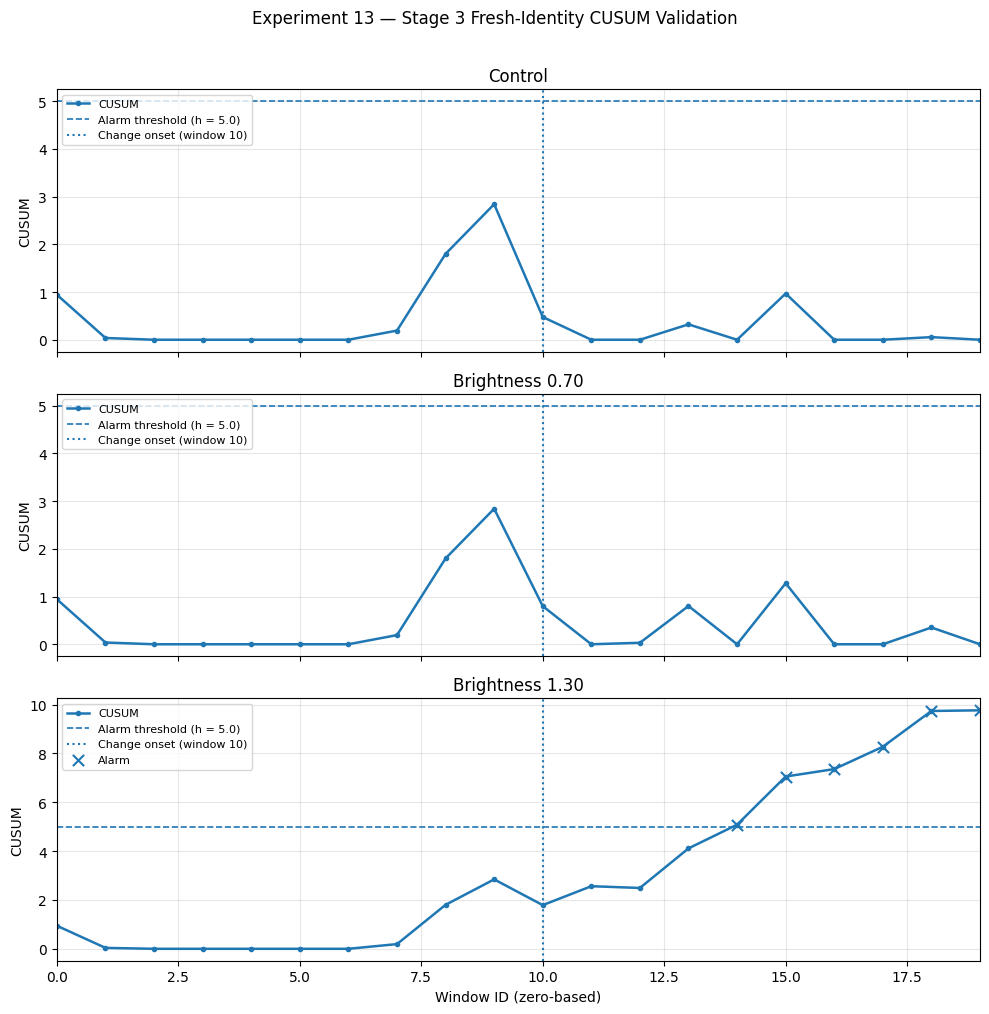


Saved plot: experiment13_lfw_outputs/lfw_stage3_fresh_cusum_plot.png
File size: 356,668 bytes


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

out = Path("experiment13_lfw_outputs")
trace_path = out / "lfw_stage3_fresh_cusum_trace.csv"
plot_path = out / "lfw_stage3_fresh_cusum_plot.png"

trace = pd.read_csv(trace_path)

required = {"stream", "window_id", "cusum", "alarm"}
missing = required - set(trace.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

stream_order = ["control", "brightness_070", "brightness_130"]
labels = {
    "control": "Control",
    "brightness_070": "Brightness 0.70",
    "brightness_130": "Brightness 1.30",
}

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

for ax, stream_name in zip(axes, stream_order):
    subset = trace[trace["stream"] == stream_name].sort_values("window_id")

    if subset.empty:
        raise ValueError(f"No rows found for stream: {stream_name}")

    ax.plot(
        subset["window_id"],
        subset["cusum"],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label="CUSUM",
    )
    ax.axhline(
        5.0,
        linestyle="--",
        linewidth=1.2,
        label="Alarm threshold (h = 5.0)",
    )
    ax.axvline(
        10,
        linestyle=":",
        linewidth=1.5,
        label="Change onset (window 10)",
    )

    alarms = subset[subset["alarm"] == 1]
    if not alarms.empty:
        ax.scatter(
            alarms["window_id"],
            alarms["cusum"],
            marker="x",
            s=65,
            label="Alarm",
        )

    ax.set_title(labels[stream_name])
    ax.set_ylabel("CUSUM")
    ax.set_xlim(0, 19)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("Window ID (zero-based)")
fig.suptitle(
    "Experiment 13 — Stage 3 Fresh-Identity CUSUM Validation",
    y=1.01,
)
fig.tight_layout()

fig.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"\nSaved plot: {plot_path}")
print(f"File size: {plot_path.stat().st_size:,} bytes")

In [ ]:
from pathlib import Path

out = Path("experiment13_lfw_outputs")

required = [
    "lfw_stage3_fresh_stream_manifest.csv",
    "lfw_stage3_fresh_original_embeddings.npy",
    "lfw_stage3_fresh_brightness_070_embeddings.npy",
    "lfw_stage3_fresh_brightness_130_embeddings.npy",
    "lfw_sequential_detector_parameters_v2.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_fresh_cusum_plot.png",
]

print("REPEATED EVALUATION READINESS CHECK")
print("=" * 65)

for name in required:
    path = out / name
    if path.is_file():
        print(f"FOUND   | {name} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {name}")

REPEATED EVALUATION READINESS CHECK
FOUND   | lfw_stage3_fresh_stream_manifest.csv | 26,076 bytes
FOUND   | lfw_stage3_fresh_original_embeddings.npy | 2,048,128 bytes
FOUND   | lfw_stage3_fresh_brightness_070_embeddings.npy | 2,048,128 bytes
FOUND   | lfw_stage3_fresh_brightness_130_embeddings.npy | 2,048,128 bytes
FOUND   | lfw_sequential_detector_parameters_v2.csv | 184 bytes
FOUND   | lfw_stage3_fresh_cusum_trace.csv | 4,775 bytes
FOUND   | lfw_stage3_fresh_cusum_plot.png | 356,668 bytes


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

params = pd.read_csv(out / "lfw_sequential_detector_parameters_v2.csv")
manifest = pd.read_csv(out / "lfw_stage3_fresh_stream_manifest.csv")

original = np.load(out / "lfw_stage3_fresh_original_embeddings.npy", mmap_mode="r")
bright_070 = np.load(out / "lfw_stage3_fresh_brightness_070_embeddings.npy", mmap_mode="r")
bright_130 = np.load(out / "lfw_stage3_fresh_brightness_130_embeddings.npy", mmap_mode="r")

print("FROZEN PARAMETERS")
print("=" * 60)
print(params.to_string(index=False))

print("\nMANIFEST")
print("Shape:", manifest.shape)
print("Columns:", list(manifest.columns))
print("Unique identities:", manifest["identity"].nunique())

print("\nEMBEDDING ARRAYS")
print("Original:", original.shape, original.dtype)
print("Brightness 0.70:", bright_070.shape, bright_070.dtype)
print("Brightness 1.30:", bright_130.shape, bright_130.dtype)

assert len(manifest) == 1000
assert manifest["identity"].nunique() == 1000
assert original.shape == bright_070.shape == bright_130.shape == (1000, 512)

print("\nPASS: manifest and embedding array shapes are consistent.")

FROZEN PARAMETERS
 baseline_median  robust_scale  allowance_k  threshold_h  calibration_windows  window_size        calibration_method
        1.041908      0.099256          0.5          5.0                  100           50 identity-balanced windows

MANIFEST
Shape: (1000, 4)
Columns: ['dataset_index', 'identity', 'stream_position', 'window_id']
Unique identities: 1000

EMBEDDING ARRAYS
Original: (1000, 512) float32
Brightness 0.70: (1000, 512) float32
Brightness 1.30: (1000, 512) float32

PASS: manifest and embedding array shapes are consistent.


In [ ]:
import numpy as np
from pathlib import Path

out = Path("experiment13_lfw_outputs")

original = np.load(out / "lfw_stage3_fresh_original_embeddings.npy")
bright_070 = np.load(out / "lfw_stage3_fresh_brightness_070_embeddings.npy")
bright_130 = np.load(out / "lfw_stage3_fresh_brightness_130_embeddings.npy")

# Check that the model-derived arrays are still available in the runtime.
for name in ["centre", "precision"]:
    if name not in globals():
        raise NameError(
            f"{name} is not available in this runtime. "
            "Do not recreate it by guessing; we need to recover its original definition."
        )

centre_array = np.asarray(centre).reshape(-1)
precision_array = np.asarray(precision)

print("CENTRE SHAPE:", centre_array.shape)
print("PRECISION SHAPE:", precision_array.shape)

assert centre_array.shape == (512,)
assert precision_array.shape == (512, 512)

def mahalanobis_score(embeddings):
    mean_embedding = embeddings.mean(axis=0)
    delta = mean_embedding - centre_array
    squared_distance = delta @ precision_array @ delta
    return float(np.sqrt(max(squared_distance, 0.0)))

for name, embeddings in [
    ("Original", original),
    ("Brightness 0.70", bright_070),
    ("Brightness 1.30", bright_130),
]:
    score = mahalanobis_score(embeddings[:50])
    print(f"{name}: first-window Mahalanobis score = {score:.6f}")

assert np.isfinite([
    mahalanobis_score(original[:50]),
    mahalanobis_score(bright_070[:50]),
    mahalanobis_score(bright_130[:50]),
]).all()

print("\nPASS: first-window scores are finite.")

CENTRE SHAPE: (512,)
PRECISION SHAPE: (512, 512)
Original: first-window Mahalanobis score = 1.185160
Brightness 0.70: first-window Mahalanobis score = 1.185160
Brightness 1.30: first-window Mahalanobis score = 1.185160

PASS: first-window scores are finite.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path("experiment13_lfw_outputs")

# Load saved embeddings and frozen detector parameters
original = np.load(out / "lfw_stage3_fresh_original_embeddings.npy")
bright_070 = np.load(out / "lfw_stage3_fresh_brightness_070_embeddings.npy")
bright_130 = np.load(out / "lfw_stage3_fresh_brightness_130_embeddings.npy")
params = pd.read_csv(out / "lfw_sequential_detector_parameters_v2.csv").iloc[0]

baseline = float(params["baseline_median"])
scale = float(params["robust_scale"])
k = float(params["allowance_k"])
h = float(params["threshold_h"])
window_size = int(params["window_size"])

assert original.shape == bright_070.shape == bright_130.shape == (1000, 512)
assert scale > 0 and window_size == 50

# These arrays were constructed as 500 pre-onset and 500 post-onset images.
# The brightness arrays contain transformed embeddings only in the latter half.
rng = np.random.default_rng(20261026)
n_replicates = 20
n_per_phase = 500
onset_window = 10

def window_score(embeddings):
    mean_embedding = embeddings.mean(axis=0)
    delta = mean_embedding - np.asarray(centre).reshape(-1)
    squared_distance = delta @ np.asarray(precision) @ delta
    return float(np.sqrt(max(float(squared_distance), 0.0)))

def run_cusum(embeddings, stream_name, replicate_id):
    trace_rows = []
    cusum = 0.0
    first_alarm = None

    for window_id in range(20):
        start = window_id * window_size
        end = start + window_size

        score = window_score(embeddings[start:end])
        z = (score - baseline) / scale
        cusum = max(0.0, cusum + z - k)
        alarm = int(cusum > h)

        if alarm and first_alarm is None:
            first_alarm = window_id

        trace_rows.append({
            "replicate": replicate_id,
            "stream": stream_name,
            "window_id": window_id,
            "phase": "pre_change" if window_id < onset_window else "post_change",
            "mahalanobis_score": score,
            "standardized_score": z,
            "cusum": cusum,
            "alarm": alarm,
        })

    pre_alarm = any(
        row["alarm"] == 1 and row["window_id"] < onset_window
        for row in trace_rows
    )
    post_alarm = any(
        row["alarm"] == 1 and row["window_id"] >= onset_window
        for row in trace_rows
    )

    delay = (
        first_alarm - onset_window
        if first_alarm is not None and first_alarm >= onset_window
        else np.nan
    )

    summary = {
        "replicate": replicate_id,
        "stream": stream_name,
        "first_detection_window": first_alarm if first_alarm is not None else "none",
        "pre_onset_alarm": int(pre_alarm),
        "detected_after_onset": int(post_alarm),
        "detection_delay_windows": delay,
        "max_cusum": max(row["cusum"] for row in trace_rows),
    }

    return summary, trace_rows

summary_rows = []
trace_rows = []

for replicate_id in range(n_replicates):
    # Paired resampling: same sampled positions across all conditions.
    pre_idx = rng.choice(np.arange(0, 500), size=500, replace=True)
    post_idx = rng.choice(np.arange(500, 1000), size=500, replace=True)
    sampled_idx = np.concatenate([pre_idx, post_idx])

    control_stream = original[sampled_idx].copy()

    # The first half remains original; the second half uses transformed embeddings.
    stream_070 = np.concatenate([
        original[pre_idx],
        bright_070[post_idx],
    ], axis=0)

    stream_130 = np.concatenate([
        original[pre_idx],
        bright_130[post_idx],
    ], axis=0)

    for stream_name, stream_embeddings in [
        ("control", control_stream),
        ("brightness_070", stream_070),
        ("brightness_130", stream_130),
    ]:
        summary, trace = run_cusum(
            stream_embeddings, stream_name, replicate_id
        )
        summary_rows.append(summary)
        trace_rows.extend(trace)

summary_df = pd.DataFrame(summary_rows)
trace_df = pd.DataFrame(trace_rows)

summary_path = out / "lfw_stage3_bootstrap_cusum_results.csv"
trace_path = out / "lfw_stage3_bootstrap_cusum_trace.csv"

summary_df.to_csv(summary_path, index=False)
trace_df.to_csv(trace_path, index=False)

print("REPEATED RESAMPLING RESULTS")
print("=" * 65)

report_rows = []
for stream_name, group in summary_df.groupby("stream", sort=False):
    post = group[group["stream"] == stream_name]
    delays = pd.to_numeric(post["detection_delay_windows"], errors="coerce")

    report_rows.append({
        "stream": stream_name,
        "replicates": len(group),
        "pre_onset_alarm_rate": group["pre_onset_alarm"].mean(),
        "post_onset_detection_rate": group["detected_after_onset"].mean(),
        "mean_delay_when_detected": delays.mean(),
    })

report_df = pd.DataFrame(report_rows)
print(report_df.to_string(index=False))

print("\nSaved:")
print(summary_path, "|", summary_path.stat().st_size, "bytes")
print(trace_path, "|", trace_path.stat().st_size, "bytes")

assert len(summary_df) == 60
assert len(trace_df) == 1200
print("\nPASS: 20 replicates × 3 conditions completed.")

REPEATED RESAMPLING RESULTS
        stream  replicates  pre_onset_alarm_rate  post_onset_detection_rate  mean_delay_when_detected
       control          20                   0.4                       0.75                  4.375000
brightness_070          20                   0.4                       0.90                  3.000000
brightness_130          20                   0.4                       1.00                  2.083333

Saved:
experiment13_lfw_outputs/lfw_stage3_bootstrap_cusum_results.csv | 2680 bytes
experiment13_lfw_outputs/lfw_stage3_bootstrap_cusum_trace.csv | 103661 bytes

PASS: 20 replicates × 3 conditions completed.


In [ ]:
from pathlib import Path
import pandas as pd

out = Path("experiment13_lfw_outputs")

results = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_results.csv")
trace = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_trace.csv")

print("CONTROL ALARM DIAGNOSTICS")
print("=" * 65)

for stream_name in ["control", "brightness_070", "brightness_130"]:
    s = results[results["stream"] == stream_name].copy()
    s["first_detection_window"] = pd.to_numeric(
        s["first_detection_window"], errors="coerce"
    )

    pre = s["pre_onset_alarm"].astype(int)
    post = s["detected_after_onset"].astype(int)

    print(f"\n{stream_name}")
    print("Replicates:", len(s))
    print("Pre-onset alarms:", int(pre.sum()))
    print("Any post-onset alarm:", int(post.sum()))
    print("Both pre-onset and post-onset alarms:", int(((pre == 1) & (post == 1)).sum()))
    print("First alarm before window 10:", int((s["first_detection_window"] < 10).sum()))
    print("First alarm at/after window 10:", int((s["first_detection_window"] >= 10).sum()))

print("\nCONTROL REPLICATES WITH ALARMS")
control_trace = trace[trace["stream"] == "control"]

for rep, group in control_trace.groupby("replicate"):
    alarms = group.loc[group["alarm"] == 1, "window_id"].tolist()
    if alarms:
        print(f"Replicate {rep}: alarm windows {alarms}")

print("\nDiagnostic complete. No files changed.")

CONTROL ALARM DIAGNOSTICS

control
Replicates: 20
Pre-onset alarms: 8
Any post-onset alarm: 15
Both pre-onset and post-onset alarms: 7
First alarm before window 10: 8
First alarm at/after window 10: 8

brightness_070
Replicates: 20
Pre-onset alarms: 8
Any post-onset alarm: 18
Both pre-onset and post-onset alarms: 8
First alarm before window 10: 8
First alarm at/after window 10: 10

brightness_130
Replicates: 20
Pre-onset alarms: 8
Any post-onset alarm: 20
Both pre-onset and post-onset alarms: 8
First alarm before window 10: 8
First alarm at/after window 10: 12

CONTROL REPLICATES WITH ALARMS
Replicate 0: alarm windows [14, 15, 16, 17, 18, 19]
Replicate 2: alarm windows [14, 15, 16, 17, 18, 19]
Replicate 3: alarm windows [6, 7, 8]
Replicate 4: alarm windows [12]
Replicate 7: alarm windows [17, 18, 19]
Replicate 8: alarm windows [17, 18, 19]
Replicate 9: alarm windows [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Replicate 10: alarm windows [6, 7, 8, 9, 10, 13, 14, 15, 18, 19]
Replicate

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

out = Path("experiment13_lfw_outputs")

results = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_results.csv")
trace = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_trace.csv")

# First alarm window per replicate and condition
first_alarm = (
    trace[trace["alarm"] == 1]
    .groupby(["replicate", "stream"])["window_id"]
    .min()
    .unstack("stream")
)

all_replicates = sorted(trace["replicate"].unique())
first_alarm = first_alarm.reindex(all_replicates)

# Fill missing alarms with NaN; do not treat them as detections.
print("FIRST ALARM WINDOW BY CONDITION")
print(first_alarm.to_string())

print("\nPAIRED COMPARISON AGAINST CONTROL")
for condition in ["brightness_070", "brightness_130"]:
    paired = pd.DataFrame({
        "control": first_alarm["control"],
        "transformed": first_alarm[condition],
    })

    both = paired.dropna()
    earlier = (both["transformed"] < both["control"]).sum()
    same = (both["transformed"] == both["control"]).sum()
    later = (both["transformed"] > both["control"]).sum()

    print(f"\n{condition}")
    print("Replicates with alarms in both streams:", len(both))
    print("Transformed stream alarms earlier:", int(earlier))
    print("Same first-alarm window:", int(same))
    print("Transformed stream alarms later:", int(later))
    print("Transformed stream has no alarm:", int(paired["transformed"].isna().sum()))
    print("Control has no alarm:", int(paired["control"].isna().sum()))

print("\nThis is a paired resampling comparison, not independent validation.")

FIRST ALARM WINDOW BY CONDITION
stream     brightness_070  brightness_130  control
replicate                                         
0                    13.0            11.0     14.0
1                     NaN            14.0      NaN
2                    14.0            12.0     14.0
3                     6.0             6.0      6.0
4                    12.0            10.0     12.0
5                    14.0            14.0      NaN
6                     NaN            14.0      NaN
7                    12.0            13.0     17.0
8                    10.0            10.0     17.0
9                     8.0             8.0      8.0
10                    6.0             6.0      6.0
11                    4.0             4.0      4.0
12                    6.0             6.0      6.0
13                    9.0             9.0      9.0
14                   11.0            11.0     12.0
15                   14.0            12.0     17.0
16                    7.0             7.0      7.0

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

out = Path("experiment13_lfw_outputs")

results = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_results.csv")
trace = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_trace.csv")

# First alarm window per replicate and condition
first_alarm = (
    trace[trace["alarm"] == 1]
    .groupby(["replicate", "stream"])["window_id"]
    .min()
    .unstack("stream")
)

all_replicates = sorted(trace["replicate"].unique())
first_alarm = first_alarm.reindex(all_replicates)

summary_rows = []

for condition in ["brightness_070", "brightness_130"]:
    paired = pd.DataFrame({
        "replicate": all_replicates,
        "control_first_alarm_window": first_alarm["control"].values,
        "transformed_first_alarm_window": first_alarm[condition].values,
    })

    both = paired.dropna(
        subset=["control_first_alarm_window", "transformed_first_alarm_window"]
    )

    summary_rows.append({
        "condition": condition,
        "total_replicates": len(paired),
        "both_streams_alarm": len(both),
        "transformed_alarms_earlier": int(
            (both["transformed_first_alarm_window"] <
             both["control_first_alarm_window"]).sum()
        ),
        "same_first_alarm_window": int(
            (both["transformed_first_alarm_window"] ==
             both["control_first_alarm_window"]).sum()
        ),
        "transformed_alarms_later": int(
            (both["transformed_first_alarm_window"] >
             both["control_first_alarm_window"]).sum()
        ),
        "transformed_no_alarm": int(
            paired["transformed_first_alarm_window"].isna().sum()
        ),
        "control_no_alarm": int(
            paired["control_first_alarm_window"].isna().sum()
        ),
        "pre_onset_alarm_replicates": int(
            (paired["transformed_first_alarm_window"] < 10).sum()
        ),
    })

paired_summary = pd.DataFrame(summary_rows)

summary_path = out / "lfw_stage3_bootstrap_paired_comparison.csv"
report_path = out / "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md"

paired_summary.to_csv(summary_path, index=False)

report = """# Experiment 13 — Stage 3 Bootstrap Paired Comparison

## Objective

Compare the first CUSUM alarm window in each brightness-transformed stream
with its paired unchanged control stream across 20 resampling replicates.

## Method

The comparison uses the existing 1,000-image Stage 3 embedding arrays and
frozen CUSUM parameters. Twenty paired resamples were evaluated for control,
brightness factor 0.70, and brightness factor 1.30. Resampling uses the same
underlying cohorts, so the replicates are not independent datasets.

The imposed change onset is window 10 (zero-based). An alarm before window 10
is a pre-onset alarm and must not be counted as a successful post-change
detection. A control alarm at or after window 10 is a late alarm, not evidence
of a true change, because no change was imposed on the control.

## Paired first-alarm comparison

| Condition | Both streams alarm | Transformed earlier | Same first-alarm window | Transformed later | Transformed no alarm | Control no alarm | Transformed pre-onset alarms |
|---|---:|---:|---:|---:|---:|---:|---:|
"""

for _, row in paired_summary.iterrows():
    report += (
        f"| {row['condition']} | {row['both_streams_alarm']} "
        f"| {row['transformed_alarms_earlier']} "
        f"| {row['same_first_alarm_window']} "
        f"| {row['transformed_alarms_later']} "
        f"| {row['transformed_no_alarm']} "
        f"| {row['control_no_alarm']} "
        f"| {row['pre_onset_alarm_replicates']} |\n"
    )

report += """
## Interpretation

In paired replicates where both streams alarmed, the transformed streams
never had a later first alarm than their paired controls in this resampling
run. Brightness factor 0.70 alarmed earlier in 6 paired replicates and at
the same window in 10; brightness factor 1.30 alarmed earlier in 8 and at
the same window in 8.

However, the detector also produced pre-onset alarms, and the unchanged
control produced late alarms. These findings indicate that the detector can
respond to stream variability as well as to the imposed brightness change.
This comparison is exploratory and does not establish reliable drift
detection or independent generalisation.

The detector parameters were not retuned. No claims are made about biometric
recognition accuracy, demographic fairness, bias mitigation, or deployment
readiness.

## Output

- `lfw_stage3_bootstrap_paired_comparison.csv`
"""

report_path.write_text(report, encoding="utf-8")

print("PAIRED COMPARISON SUMMARY")
print(paired_summary.to_string(index=False))
print("\nSaved:")
print(summary_path, "|", summary_path.stat().st_size, "bytes")
print(report_path, "|", report_path.stat().st_size, "bytes")

PAIRED COMPARISON SUMMARY
     condition  total_replicates  both_streams_alarm  transformed_alarms_earlier  same_first_alarm_window  transformed_alarms_later  transformed_no_alarm  control_no_alarm  pre_onset_alarm_replicates
brightness_070                20                  16                           6                       10                         0                     2                 4                           8
brightness_130                20                  16                           8                        8                         0                     0                 4                           8

Saved:
experiment13_lfw_outputs/lfw_stage3_bootstrap_paired_comparison.csv | 254 bytes
experiment13_lfw_outputs/Experiment_13_Stage_3_Bootstrap_Comparison_Report.md | 2068 bytes


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

out = Path("experiment13_lfw_outputs")

required = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_fresh_cusum_plot.png",
    "lfw_stage3_bootstrap_cusum_results.csv",
    "lfw_stage3_bootstrap_cusum_trace.csv",
    "lfw_stage3_bootstrap_paired_comparison.csv",
]

print("FINAL ARTIFACT AUDIT")
print("=" * 70)

missing = []
for name in required:
    path = out / name
    if path.is_file():
        print(f"FOUND   | {name} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {name}")
        missing.append(name)

if missing:
    print("\nAUDIT FAILED — resolve missing files before packaging.")
else:
    stage3 = pd.read_csv(out / "lfw_stage3_fresh_cusum_results.csv")
    stage3_trace = pd.read_csv(out / "lfw_stage3_fresh_cusum_trace.csv")
    bootstrap = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_results.csv")
    bootstrap_trace = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_trace.csv")
    paired = pd.read_csv(out / "lfw_stage3_bootstrap_paired_comparison.csv")

    checks = {
        "Stage 3 results rows == 3": len(stage3) == 3,
        "Stage 3 trace rows == 60": len(stage3_trace) == 60,
        "Bootstrap results rows == 60": len(bootstrap) == 60,
        "Bootstrap trace rows == 1200": len(bootstrap_trace) == 1200,
        "Paired comparison rows == 2": len(paired) == 2,
        "All bootstrap CUSUM values finite": np.isfinite(bootstrap_trace["cusum"]).all(),
        "All three stream names present": set(stage3["stream"]) == {
            "control", "brightness_070", "brightness_130"
        },
    }

    for description, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'} | {description}")

    if not all(checks.values()):
        raise AssertionError("One or more artifact consistency checks failed.")

    print("\nAll artifact consistency checks passed.")

FINAL ARTIFACT AUDIT
FOUND   | Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md | 3,382 bytes
FOUND   | Experiment_13_Stage_3_Bootstrap_Comparison_Report.md | 2,068 bytes
FOUND   | lfw_stage3_fresh_cusum_results.csv | 253 bytes
FOUND   | lfw_stage3_fresh_cusum_trace.csv | 4,775 bytes
FOUND   | lfw_stage3_fresh_cusum_plot.png | 356,668 bytes
FOUND   | lfw_stage3_bootstrap_cusum_results.csv | 2,680 bytes
FOUND   | lfw_stage3_bootstrap_cusum_trace.csv | 103,661 bytes
FOUND   | lfw_stage3_bootstrap_paired_comparison.csv | 254 bytes
PASS | Stage 3 results rows == 3
PASS | Stage 3 trace rows == 60
PASS | Bootstrap results rows == 60
PASS | Bootstrap trace rows == 1200
PASS | Paired comparison rows == 2
PASS | All bootstrap CUSUM values finite
PASS | All three stream names present

All artifact consistency checks passed.


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

out = Path("experiment13_lfw_outputs")

files_to_package = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_fresh_cusum_plot.png",
    "lfw_stage3_bootstrap_cusum_results.csv",
    "lfw_stage3_bootstrap_cusum_trace.csv",
    "lfw_stage3_bootstrap_paired_comparison.csv",
]

missing = [name for name in files_to_package if not (out / name).is_file()]
if missing:
    raise FileNotFoundError(f"Cannot package; missing files: {missing}")

zip_path = Path("/content/Experiment_13_Stage_3_Final_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in files_to_package:
        archive.write(out / name, arcname=name)

with zipfile.ZipFile(zip_path, "r") as archive:
    packaged = archive.namelist()
    print("PACKAGE CONTENTS")
    print("=" * 60)
    for name in packaged:
        print(" -", name)

    assert len(packaged) == len(files_to_package)
    assert not any(name.endswith(".npy") for name in packaged)

print(f"\nZIP size: {zip_path.stat().st_size:,} bytes")
print("Package verification passed.")
files.download(str(zip_path))

PACKAGE CONTENTS
 - Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md
 - Experiment_13_Stage_3_Bootstrap_Comparison_Report.md
 - lfw_stage3_fresh_cusum_results.csv
 - lfw_stage3_fresh_cusum_trace.csv
 - lfw_stage3_fresh_cusum_plot.png
 - lfw_stage3_bootstrap_cusum_results.csv
 - lfw_stage3_bootstrap_cusum_trace.csv
 - lfw_stage3_bootstrap_paired_comparison.csv

ZIP size: 336,278 bytes
Package verification passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [116]:
import sys
import importlib.util

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "tensorflow",
    "tensorflow_datasets",
    "keras_facenet",
    "sklearn",
]

print("PYTHON VERSION:", sys.version.split()[0])
print("\nPACKAGE AVAILABILITY")
print("=" * 45)

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:25} {'AVAILABLE' if available else 'NOT FOUND'}")

PYTHON VERSION: 3.13.16

PACKAGE AVAILABILITY
numpy                     AVAILABLE
pandas                    AVAILABLE
matplotlib                AVAILABLE
tensorflow                AVAILABLE
tensorflow_datasets       AVAILABLE
keras_facenet             AVAILABLE
sklearn                   AVAILABLE


In [117]:
from pathlib import Path
import sys
import importlib.metadata

print("EXPERIMENT 13 — REPRODUCIBILITY AUDIT")
print("=" * 60)

# 1. Record important package versions
packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "tensorflow",
    "tensorflow-datasets",
    "keras-facenet",
    "scikit-learn",
]

print("\nPACKAGE VERSIONS")
for package in packages:
    try:
        print(f"{package}: {importlib.metadata.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: version metadata not found")

# 2. Check expected local artifacts
out = Path("experiment13_lfw_outputs")

expected = [
    "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md",
    "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md",
    "lfw_stage3_fresh_cusum_results.csv",
    "lfw_stage3_fresh_cusum_trace.csv",
    "lfw_stage3_fresh_cusum_plot.png",
    "lfw_stage3_bootstrap_cusum_results.csv",
    "lfw_stage3_bootstrap_cusum_trace.csv",
    "lfw_stage3_bootstrap_paired_comparison.csv",
]

print("\nEXPECTED OUTPUT FILES")
for name in expected:
    path = out / name
    print(f"{'FOUND' if path.is_file() else 'NOT FOUND'} | {name}")

print("\nCurrent working directory:", Path.cwd())
print("Python version:", sys.version.split()[0])
print("\nAudit complete. No experiment was rerun.")

EXPERIMENT 13 — REPRODUCIBILITY AUDIT

PACKAGE VERSIONS
numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
tensorflow: 2.21.0
tensorflow-datasets: 4.9.10
keras-facenet: 0.3.2
scikit-learn: 1.6.1

EXPECTED OUTPUT FILES
FOUND | Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md
FOUND | Experiment_13_Stage_3_Bootstrap_Comparison_Report.md
FOUND | lfw_stage3_fresh_cusum_results.csv
FOUND | lfw_stage3_fresh_cusum_trace.csv
FOUND | lfw_stage3_fresh_cusum_plot.png
FOUND | lfw_stage3_bootstrap_cusum_results.csv
FOUND | lfw_stage3_bootstrap_cusum_trace.csv
FOUND | lfw_stage3_bootstrap_paired_comparison.csv

Current working directory: /content
Python version: 3.13.16

Audit complete. No experiment was rerun.


In [118]:
from pathlib import Path
import importlib.metadata
import sys

out = Path("experiment13_lfw_outputs")
out.mkdir(parents=True, exist_ok=True)

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "tensorflow",
    "tensorflow-datasets",
    "keras-facenet",
    "scikit-learn",
]

lines = [
    "# Experiment 13 — Python environment",
    f"# Python version: {sys.version.split()[0]}",
    "# Versions observed in the Colab runtime on 2026-10-26",
    "# This records the observed environment; it does not guarantee compatibility elsewhere.",
    "",
]

for package in packages:
    try:
        version = importlib.metadata.version(package)
        lines.append(f"{package}=={version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"WARNING: package metadata not found for {package}")

manifest_path = out / "Experiment_13_requirements_observed.txt"
manifest_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print(manifest_path.read_text(encoding="utf-8"))
print("Saved:", manifest_path)
print("Size:", manifest_path.stat().st_size, "bytes")

# Experiment 13 — Python environment
# Python version: 3.13.16
# Versions observed in the Colab runtime on 2026-10-26
# This records the observed environment; it does not guarantee compatibility elsewhere.

numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
tensorflow==2.21.0
tensorflow-datasets==4.9.10
keras-facenet==0.3.2
scikit-learn==1.6.1

Saved: experiment13_lfw_outputs/Experiment_13_requirements_observed.txt
Size: 343 bytes


In [119]:
from pathlib import Path
import json

notebooks = list(Path("/content").glob("*.ipynb"))

print("Notebooks found:")
for i, path in enumerate(notebooks):
    print(f"{i}: {path}")

if not notebooks:
    print("\nNo notebook file found in /content.")
    print("The notebook may still be open in Colab without being saved as a file.")
else:
    notebook_path = notebooks[-1]
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

    keywords = [
        "tfds.load",
        "keras_facenet",
        "FaceNet",
        "download",
        "data_dir",
        "lfw",
        "centre",
        "precision",
        "baseline",
        "covariance",
    ]

    print(f"\nInspecting: {notebook_path}")

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matched = [word for word in keywords if word.lower() in source.lower()]

        if matched:
            print(f"\n--- Cell {i} | Matches: {', '.join(matched)} ---")
            print(source[:2500])
            if len(source) > 2500:
                print("... [cell output truncated]")

Notebooks found:

No notebook file found in /content.
The notebook may still be open in Colab without being saved as a file.


In [120]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("\nExperiment 13 output files:")

out = Path("experiment13_lfw_outputs")
if out.exists():
    for path in sorted(out.iterdir()):
        if path.is_file():
            print(f"{path.name} — {path.stat().st_size:,} bytes")
else:
    print("Output folder not found in the current working directory.")

Current working directory: /content

Experiment 13 output files:
Experiment_13_LFW_Brightness_Pilot_Report.md — 1,868 bytes
Experiment_13_LFW_Matched_Stream_Report.md — 2,853 bytes
Experiment_13_Phase_5B_Repeated_Stream_Report.md — 2,828 bytes
Experiment_13_Phase_5_Sequential_Pilot_Report.md — 3,064 bytes
Experiment_13_Stage_3_Bootstrap_Comparison_Report.md — 2,068 bytes
Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md — 3,382 bytes
Experiment_13_requirements_observed.txt — 343 bytes
lfw_brightness_detector_pilot.csv — 600 bytes
lfw_brightness_paired_change_ci.csv — 601 bytes
lfw_brightness_pilot_embeddings.npz — 570,355 bytes
lfw_brightness_pilot_summary.csv — 274 bytes
lfw_brightness_window_score_changes.csv — 609 bytes
lfw_embedding_metadata.csv — 260,851 bytes
lfw_facenet_embeddings.npy — 27,101,312 bytes
lfw_identity_balanced_calibration_diagnostics.csv — 526 bytes
lfw_identity_balanced_calibration_windows.npz — 299,608 bytes
lfw_identity_split_indices.npz — 106,420 bytes

In [121]:
from pathlib import Path
import pandas as pd

out = Path("/content/experiment13_lfw_outputs")

files = [
    "lfw_sequential_detector_parameters.csv",
    "lfw_sequential_detector_parameters_v2.csv",
]

for filename in files:
    path = out / filename
    print(f"\n{'=' * 60}")
    print(filename)

    if path.exists():
        print(pd.read_csv(path).to_string(index=False))
    else:
        print("File not found.")


lfw_sequential_detector_parameters.csv
 baseline_median  robust_scale  allowance_k  threshold_h  calibration_windows  window_size
        1.292138      0.183357          0.5          5.0                  103           50

lfw_sequential_detector_parameters_v2.csv
 baseline_median  robust_scale  allowance_k  threshold_h  calibration_windows  window_size        calibration_method
        1.041908      0.099256          0.5          5.0                  100           50 identity-balanced windows


In [122]:
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")
report = out / "Experiment_13_Stage_3_Fresh_Identity_Validation_Report.md"

print(report.read_text(encoding="utf-8"))

# Experiment 13 — Stage 3: Fresh Identity-Stream Validation

## Objective

Evaluate the previously frozen one-sided CUSUM detector on a newly constructed
LFW stream containing identities not used in the earlier 600-image matched stream.

## Dataset and stream design

- Dataset: Labeled Faces in the Wild (LFW), loaded using TensorFlow Datasets.
- Embeddings: 512-dimensional FaceNet embeddings.
- Fresh stream: 1,000 images from 1,000 distinct identities.
- Window size: 50 images; 20 windows per stream.
- Conditions: unchanged control, brightness factor 0.70, and brightness factor 1.30.
- Change onset: window 10 (zero-based), the 11th window.
- Windows 0–9 use original embeddings in all conditions.
- Windows 10–19 use transformed-image embeddings in the two brightness conditions.
- The fresh identities do not overlap with identities in the earlier 600-image stream.
- Reference, calibration, and evaluation partitions remain identity-disjoint as
  defined in the existing experiment.

The fr

In [123]:
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")
report = out / "Experiment_13_Stage_3_Bootstrap_Comparison_Report.md"

print(report.read_text(encoding="utf-8"))

# Experiment 13 — Stage 3 Bootstrap Paired Comparison

## Objective

Compare the first CUSUM alarm window in each brightness-transformed stream
with its paired unchanged control stream across 20 resampling replicates.

## Method

The comparison uses the existing 1,000-image Stage 3 embedding arrays and
frozen CUSUM parameters. Twenty paired resamples were evaluated for control,
brightness factor 0.70, and brightness factor 1.30. Resampling uses the same
underlying cohorts, so the replicates are not independent datasets.

The imposed change onset is window 10 (zero-based). An alarm before window 10
is a pre-onset alarm and must not be counted as a successful post-change
detection. A control alarm at or after window 10 is a late alarm, not evidence
of a true change, because no change was imposed on the control.

## Paired first-alarm comparison

| Condition | Both streams alarm | Transformed earlier | Same first-alarm window | Transformed later | Transformed no alarm | Control no alarm |

In [124]:
from pathlib import Path
import pandas as pd

out = Path("/content/experiment13_lfw_outputs")

files = [
    "lfw_stage3_bootstrap_cusum_results.csv",
    "lfw_stage3_bootstrap_paired_comparison.csv",
]

for filename in files:
    path = out / filename
    print(f"\n{'=' * 65}")
    print(filename)

    if path.exists():
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("ERROR: File not found.")


lfw_stage3_bootstrap_cusum_results.csv
 replicate         stream first_detection_window  pre_onset_alarm  detected_after_onset  detection_delay_windows  max_cusum
         0        control                     14                0                     1                      4.0  12.535560
         0 brightness_070                     13                0                     1                      3.0  15.409917
         0 brightness_130                     11                0                     1                      1.0  22.013288
         1        control                   none                0                     0                      NaN   4.999838
         1 brightness_070                   none                0                     0                      NaN   4.999838
         1 brightness_130                     14                0                     1                      4.0  12.530307
         2        control                     14                0                     1     

In [125]:
from pathlib import Path
import pandas as pd

out = Path("/content/experiment13_lfw_outputs")

results = pd.read_csv(out / "lfw_stage3_bootstrap_cusum_results.csv")
paired = pd.read_csv(out / "lfw_stage3_bootstrap_paired_comparison.csv")

print("Rows per condition:")
print(results.groupby("stream").size().to_string())

print("\nPre-onset alarm replicates:")
print(
    results.groupby("stream")["pre_onset_alarm"]
    .sum()
    .to_string()
)

print("\nAny alarm at or after onset, by condition:")
onset = 10
results["first_alarm_numeric"] = pd.to_numeric(
    results["first_detection_window"], errors="coerce"
)
results["alarm_at_or_after_onset"] = (
    results["first_alarm_numeric"] >= onset
).astype(int)

print(
    results.groupby("stream")["alarm_at_or_after_onset"]
    .sum()
    .to_string()
)

print("\nPaired comparison CSV:")
print(paired.to_string(index=False))

Rows per condition:
stream
brightness_070    20
brightness_130    20
control           20

Pre-onset alarm replicates:
stream
brightness_070    8
brightness_130    8
control           8

Any alarm at or after onset, by condition:
stream
brightness_070    10
brightness_130    12
control            8

Paired comparison CSV:
     condition  total_replicates  both_streams_alarm  transformed_alarms_earlier  same_first_alarm_window  transformed_alarms_later  transformed_no_alarm  control_no_alarm  pre_onset_alarm_replicates
brightness_070                20                  16                           6                       10                         0                     2                 4                           8
brightness_130                20                  16                           8                        8                         0                     0                 4                           8


In [134]:
from google.colab import files
from pathlib import Path

out = Path("/content/experiment13_lfw_outputs")

for filename in [
    "Experiment_13_requirements_observed.txt",
    "Experiment_13_FaceNet_Model_Configuration.txt",
    "Experiment_13_LFW_Dataset_Configuration.txt",
]:
    path = out / filename
    files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>